
# 01 | Project Setup and Data Integrity

This section establishes a reproducible environment for the Richter's Predictor: Modeling Earthquake Damage competition.

The four competition files are retrieved from the project's GitHub repository and stored in a dedicated working directory. The data audit checks:

- Expected train and test dimensions
- Unique building identifiers
- Training feature/label alignment
- Test feature/submission alignment
- Missing values and duplicate records
- Valid target classes

The competition data are the sole modeling data source. No external datasets are introduced.


In [6]:

# ============================================================
# 01 | PROJECT SETUP, DATA DOWNLOAD, AND VALIDATION
# ============================================================

import sys
import subprocess
import importlib.util
from pathlib import Path
import warnings
import json
import time

warnings.filterwarnings("ignore")

# -----------------------------
# Reproducibility
# -----------------------------
RANDOM_STATE = 42

# -----------------------------
# Install required packages
# -----------------------------
required_packages = {
    "catboost": "catboost",
    "lightgbm": "lightgbm",
    "xgboost": "xgboost",
    "seaborn": "seaborn"
}

for module_name, package_name in required_packages.items():
    if importlib.util.find_spec(module_name) is None:
        print(f"Installing {package_name}...")
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", package_name]
        )

# -----------------------------
# Imports
# -----------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests

from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120

# -----------------------------
# Project paths
# -----------------------------
PROJECT_DIR = Path("/kaggle/working/nepal_earthquake_damage")
DATA_DIR = PROJECT_DIR / "data"
ARTIFACT_DIR = PROJECT_DIR / "artifacts"

DATA_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# -----------------------------
# GitHub raw data source
# -----------------------------
GITHUB_BASE = (
    "https://raw.githubusercontent.com/"
    "ut1776/nepal-earthquake-damage/main/Dataset/"
)

FILES = {
    "train_values.csv": DATA_DIR / "train_values.csv",
    "train_labels.csv": DATA_DIR / "train_labels.csv",
    "test_values.csv": DATA_DIR / "test_values.csv",
    "submission_format.csv": DATA_DIR / "submission_format.csv"
}

# -----------------------------
# Download missing files
# -----------------------------
for filename, destination in FILES.items():

    if destination.exists() and destination.stat().st_size > 0:
        print(f"Already available: {filename}")
        continue

    url = GITHUB_BASE + filename
    print(f"Downloading: {filename}")

    response = requests.get(url, timeout=120)
    response.raise_for_status()

    destination.write_bytes(response.content)

    if destination.stat().st_size == 0:
        raise RuntimeError(f"Downloaded file is empty: {filename}")

    print(
        f"Saved {filename}: "
        f"{destination.stat().st_size / (1024 ** 2):.2f} MB"
    )

# -----------------------------
# Load competition data
# -----------------------------
train_values = pd.read_csv(FILES["train_values.csv"])
train_labels = pd.read_csv(FILES["train_labels.csv"])
test_values = pd.read_csv(FILES["test_values.csv"])
submission_format = pd.read_csv(FILES["submission_format.csv"])

# -----------------------------
# Core schema validation
# -----------------------------
ID_COLUMN = "building_id"
TARGET = "damage_grade"

assert ID_COLUMN in train_values.columns
assert ID_COLUMN in train_labels.columns
assert ID_COLUMN in test_values.columns
assert ID_COLUMN in submission_format.columns
assert TARGET in train_labels.columns

assert train_values[ID_COLUMN].is_unique
assert train_labels[ID_COLUMN].is_unique
assert test_values[ID_COLUMN].is_unique
assert submission_format[ID_COLUMN].is_unique

assert set(train_values[ID_COLUMN]) == set(train_labels[ID_COLUMN])
assert set(test_values[ID_COLUMN]) == set(submission_format[ID_COLUMN])

assert train_values[ID_COLUMN].tolist() == train_labels[ID_COLUMN].tolist()
assert test_values[ID_COLUMN].tolist() == submission_format[ID_COLUMN].tolist()

assert set(train_values.columns) == set(test_values.columns)
assert set(train_labels[TARGET].unique()).issubset({1, 2, 3})

# -----------------------------
# Missing values and duplicates
# -----------------------------
missing_train_features = int(train_values.isna().sum().sum())
missing_train_labels = int(train_labels.isna().sum().sum())
missing_test_features = int(test_values.isna().sum().sum())

duplicate_train_features = int(train_values.duplicated().sum())
duplicate_train_labels = int(train_labels.duplicated().sum())
duplicate_test_features = int(test_values.duplicated().sum())

# -----------------------------
# Data audit report
# -----------------------------
audit = pd.DataFrame({
    "Dataset": [
        "train_values",
        "train_labels",
        "test_values",
        "submission_format"
    ],
    "Rows": [
        len(train_values),
        len(train_labels),
        len(test_values),
        len(submission_format)
    ],
    "Columns": [
        train_values.shape[1],
        train_labels.shape[1],
        test_values.shape[1],
        submission_format.shape[1]
    ]
})

print("=" * 72)
print("RICHTER | DATA INTEGRITY REPORT")
print("=" * 72)

display(audit)

print("\nValidation checks")
print("-" * 72)
print(f"Training observations:       {len(train_values):,}")
print(f"Test observations:           {len(test_values):,}")
print(f"Original predictors:         {train_values.shape[1] - 1}")
print(f"Missing training features:   {missing_train_features:,}")
print(f"Missing training labels:     {missing_train_labels:,}")
print(f"Missing test features:       {missing_test_features:,}")
print(f"Duplicate training rows:     {duplicate_train_features:,}")
print(f"Duplicate label rows:        {duplicate_train_labels:,}")
print(f"Duplicate test rows:         {duplicate_test_features:,}")
print("Training ID alignment:       PASS")
print("Test ID alignment:           PASS")
print("Feature schema alignment:    PASS")
print("Target class validation:     PASS")

print("\nTarget classes:")
display(
    train_labels[TARGET]
    .value_counts()
    .sort_index()
    .rename("building_count")
    .to_frame()
)

# -----------------------------
# Save a machine-readable audit
# -----------------------------
audit_report = {
    "random_state": RANDOM_STATE,
    "train_rows": int(len(train_values)),
    "test_rows": int(len(test_values)),
    "original_predictors": int(train_values.shape[1] - 1),
    "missing_train_features": missing_train_features,
    "missing_train_labels": missing_train_labels,
    "missing_test_features": missing_test_features,
    "duplicate_train_features": duplicate_train_features,
    "duplicate_train_labels": duplicate_train_labels,
    "duplicate_test_features": duplicate_test_features,
    "train_test_schema_match": True,
    "train_id_alignment": True,
    "test_id_alignment": True
}

with open(ARTIFACT_DIR / "data_audit.json", "w") as f:
    json.dump(audit_report, f, indent=2)

print(f"\nAudit saved to: {ARTIFACT_DIR / 'data_audit.json'}")
print("\nSECTION 01 COMPLETE")


Already available: train_values.csv
Already available: train_labels.csv
Already available: test_values.csv
Already available: submission_format.csv
RICHTER | DATA INTEGRITY REPORT


,Dataset,Rows,Columns
0,train_values,260601,39
1,train_labels,260601,2
2,test_values,86868,39
3,submission_format,86868,2



Validation checks
------------------------------------------------------------------------
Training observations:       260,601
Test observations:           86,868
Original predictors:         38
Missing training features:   0
Missing training labels:     0
Missing test features:       0
Duplicate training rows:     0
Duplicate label rows:        0
Duplicate test rows:         0
Training ID alignment:       PASS
Test ID alignment:           PASS
Feature schema alignment:    PASS
Target class validation:     PASS

Target classes:


,building_count
damage_grade,
1,25124
2,148259
3,87218



Audit saved to: /kaggle/working/nepal_earthquake_damage/artifacts/data_audit.json

SECTION 01 COMPLETE



# 02 | Exploratory Data Analysis

This section examines the distribution of earthquake damage grades and the structural and geographic characteristics associated with building damage.

The analysis focuses on:

1. Target-class imbalance and the majority-class baseline
2. Numeric building characteristics across damage grades
3. Structural characteristics and building materials
4. Geographic variation across administrative levels
5. Potential signals that may guide feature engineering

The competition target contains three ordered damage categories. However, the primary competition metric is micro-F1, which is equivalent to accuracy for this single-label multiclass task.

EDA is descriptive. Geographic and structural associations are not interpreted as causal effects.


TARGET DISTRIBUTION


,building_count,percentage
damage_grade,,
1,25124,9.64
2,148259,56.89
3,87218,33.47


Majority-class baseline accuracy: 0.5689 (56.89%)


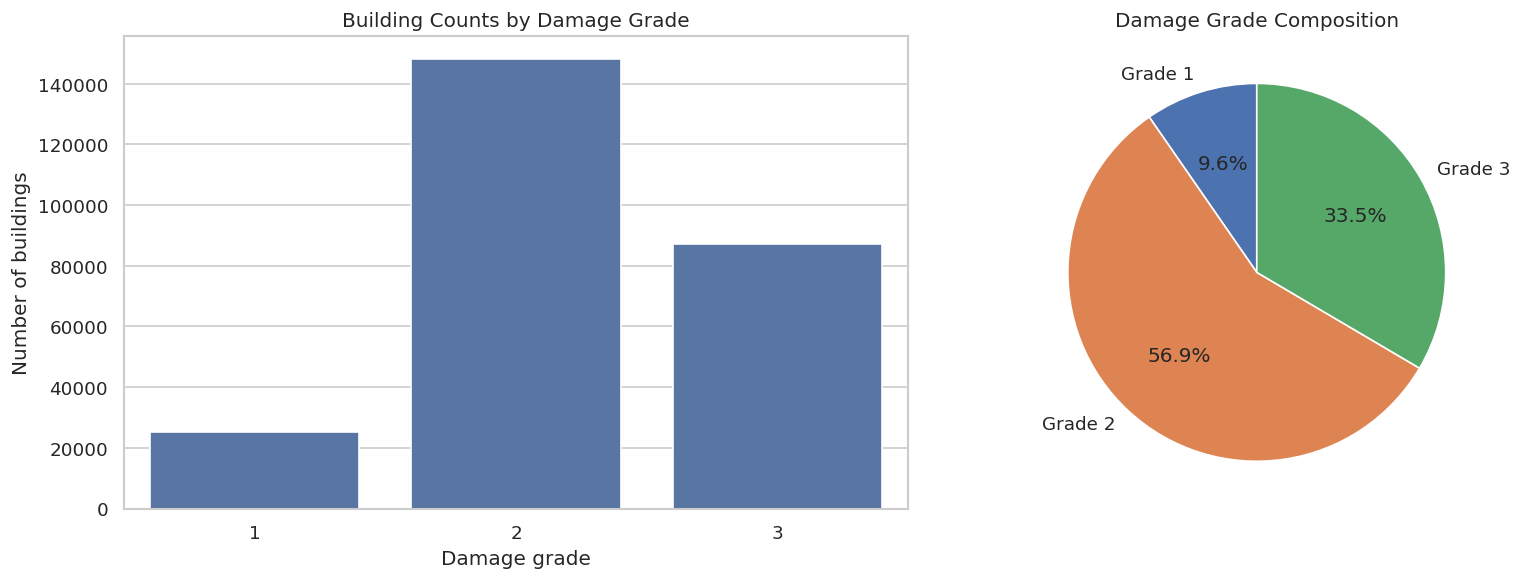


MEDIAN NUMERIC CHARACTERISTICS BY DAMAGE GRADE


damage_grade,1,2,3
age,5.0,15.0,20.0
count_floors_pre_eq,2.0,2.0,2.0
area_percentage,8.0,7.0,7.0
height_percentage,5.0,5.0,5.0
count_families,1.0,1.0,1.0


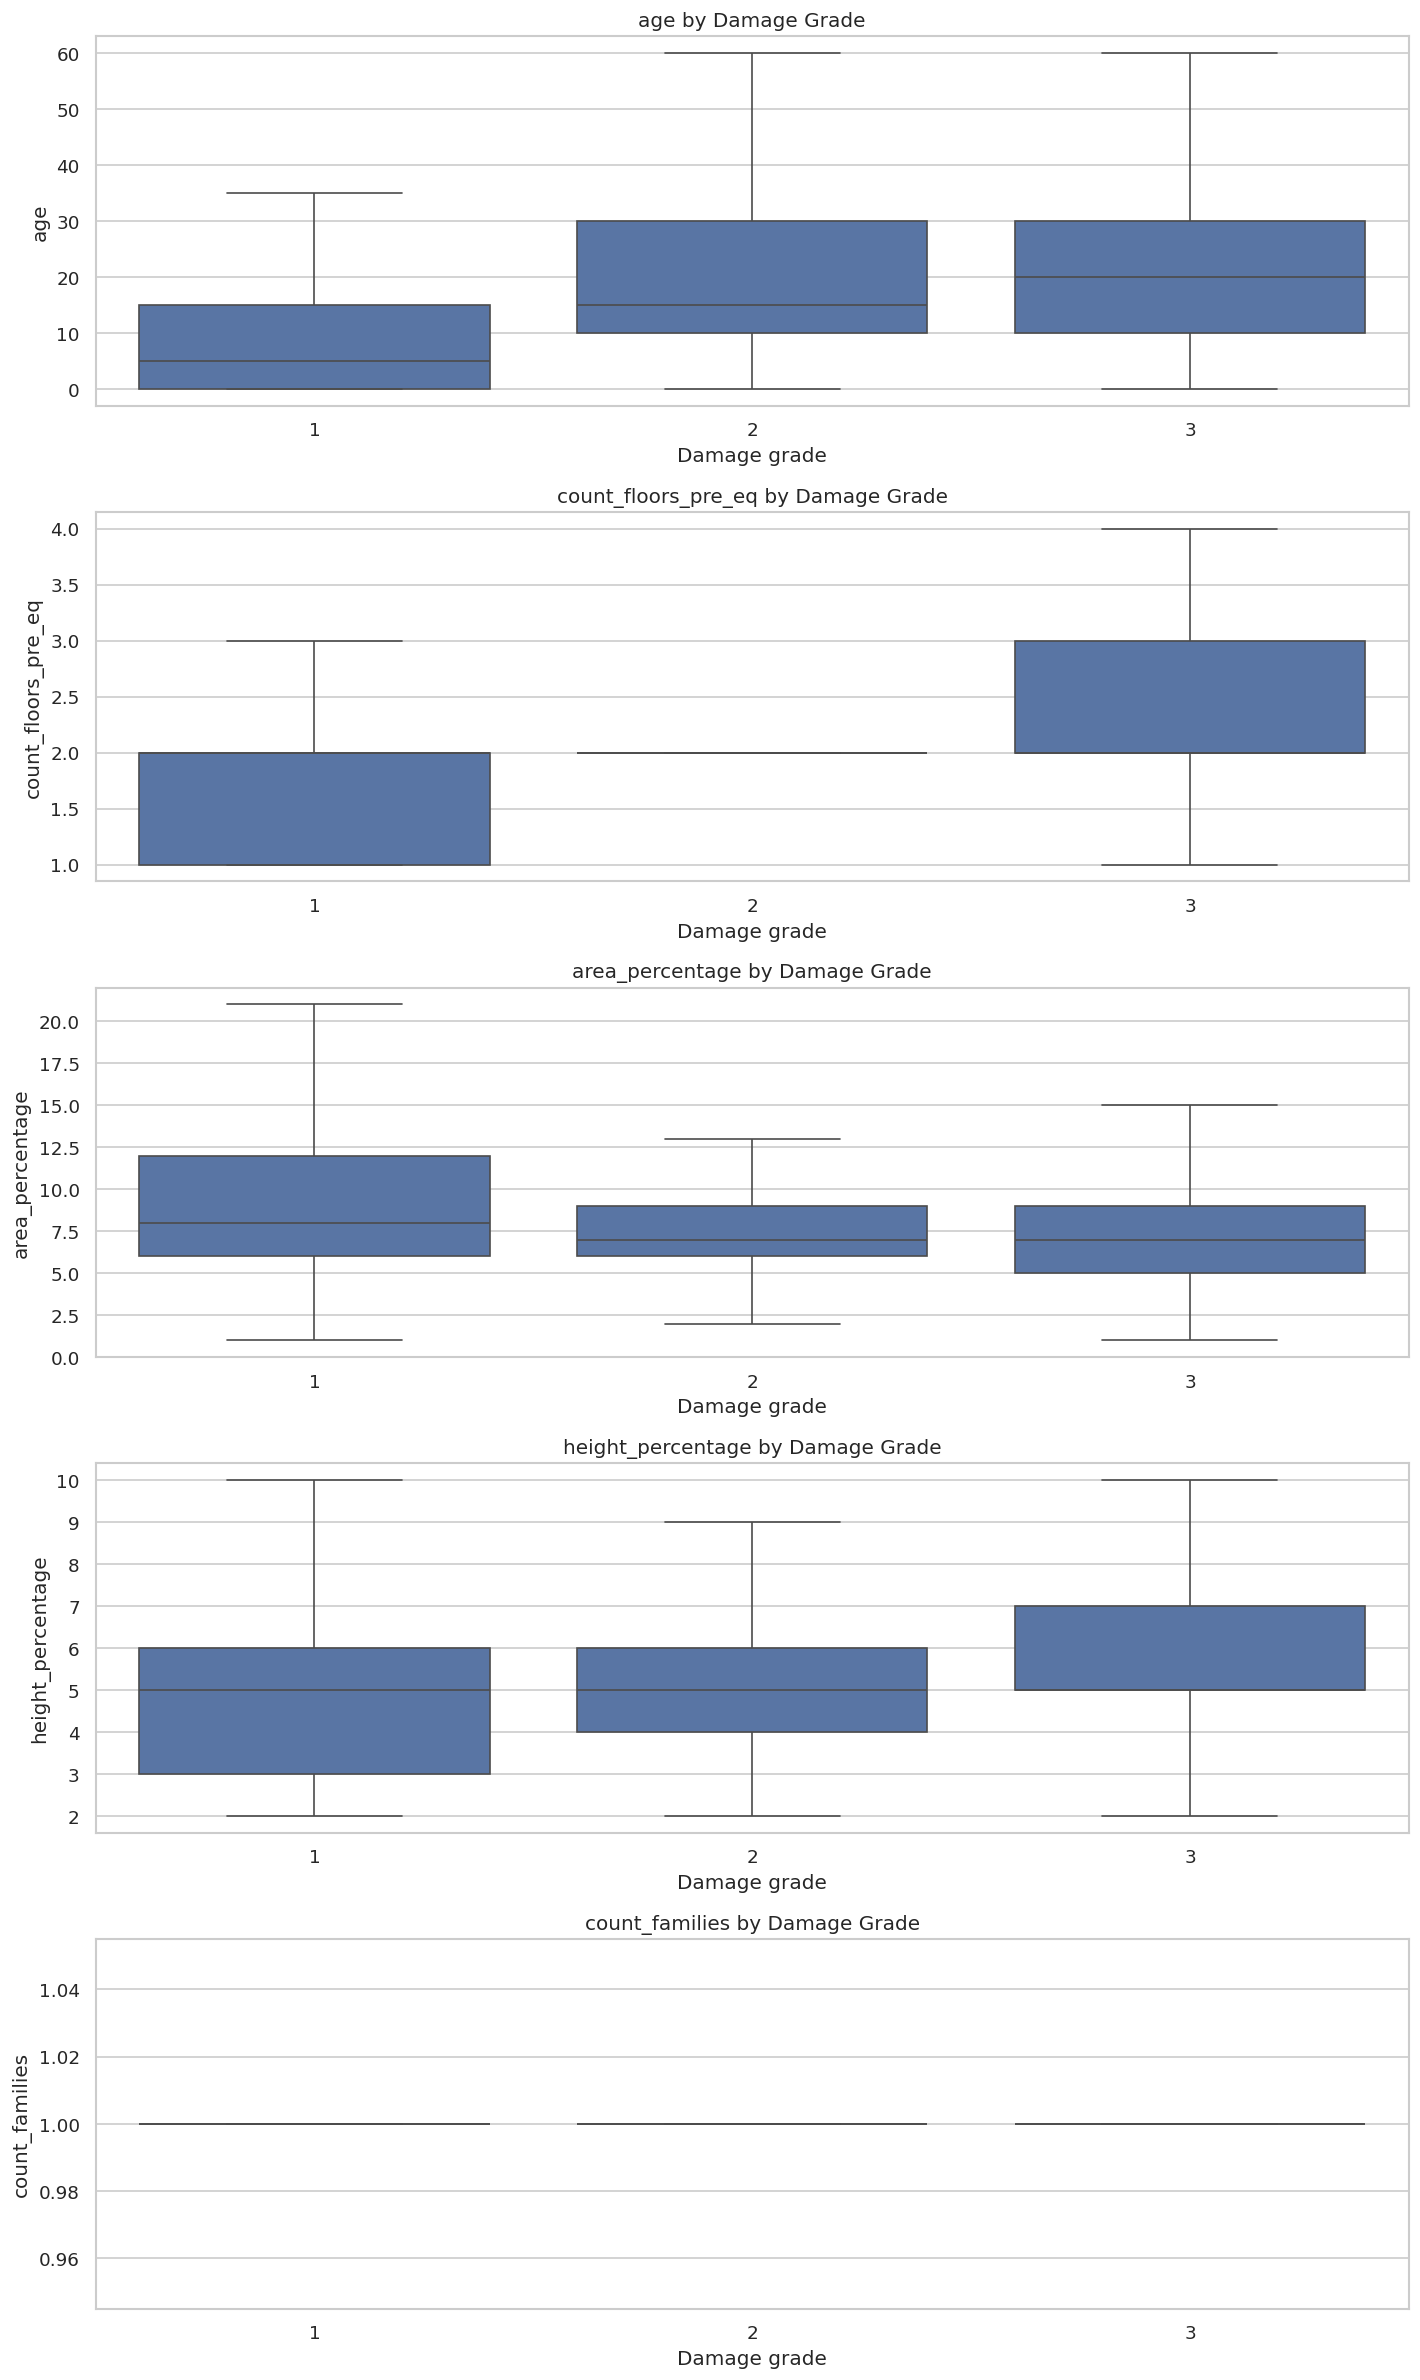

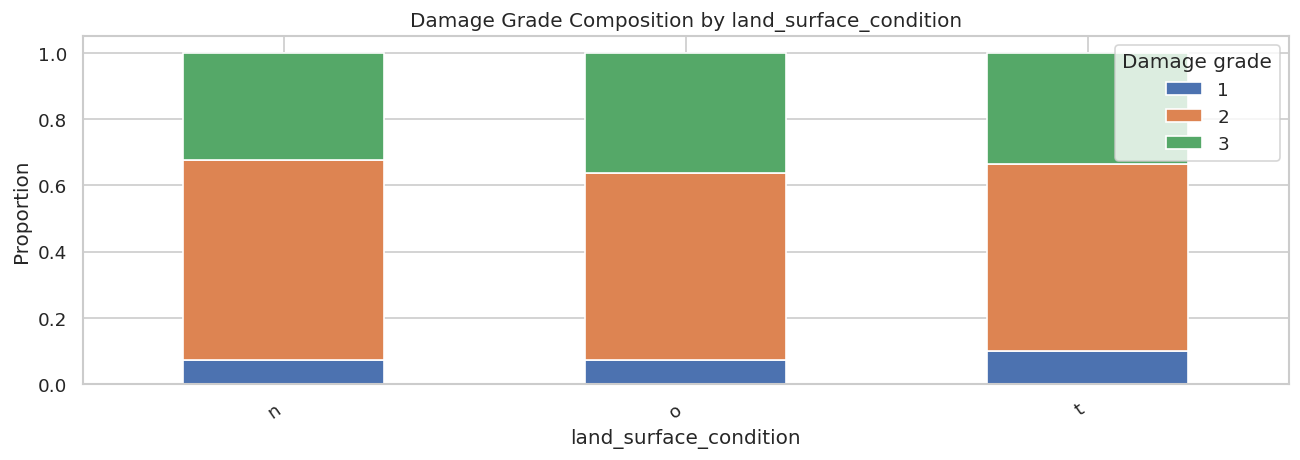

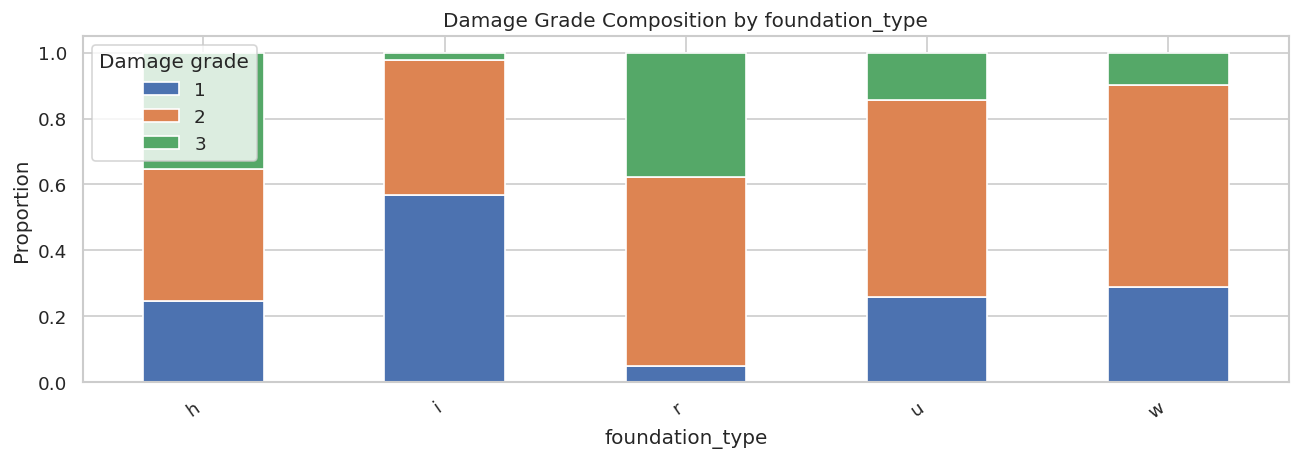

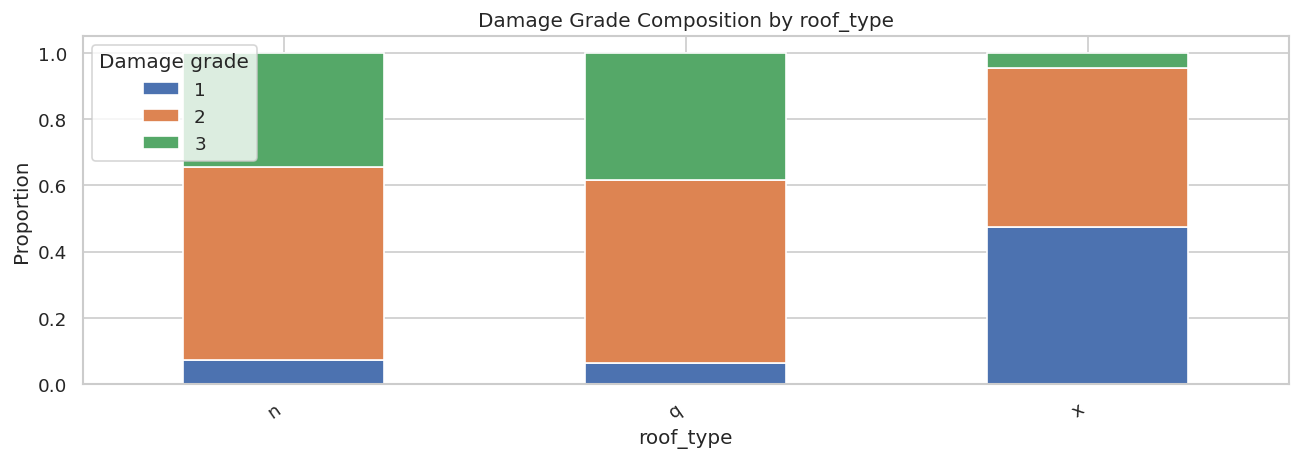

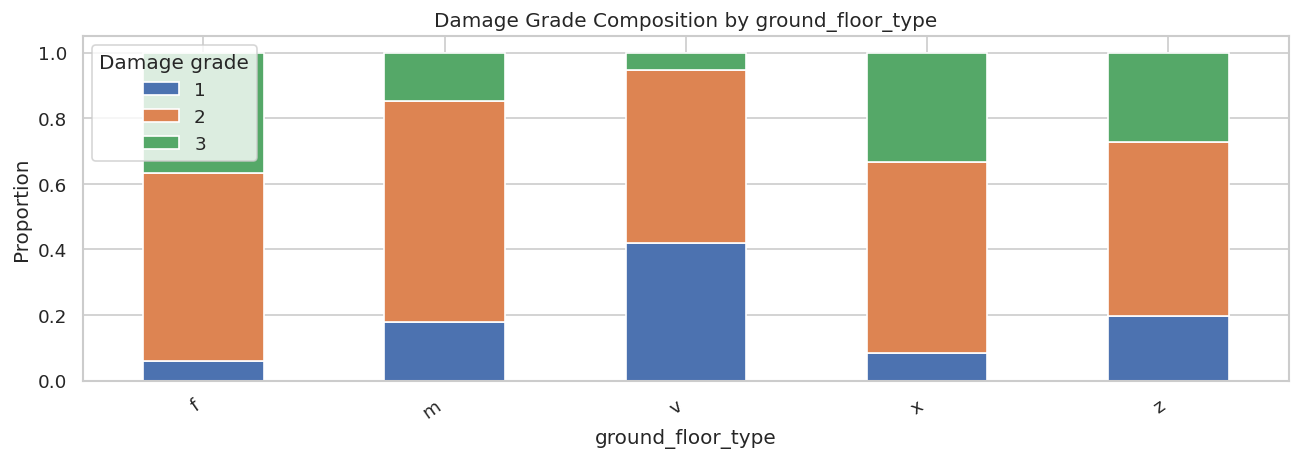

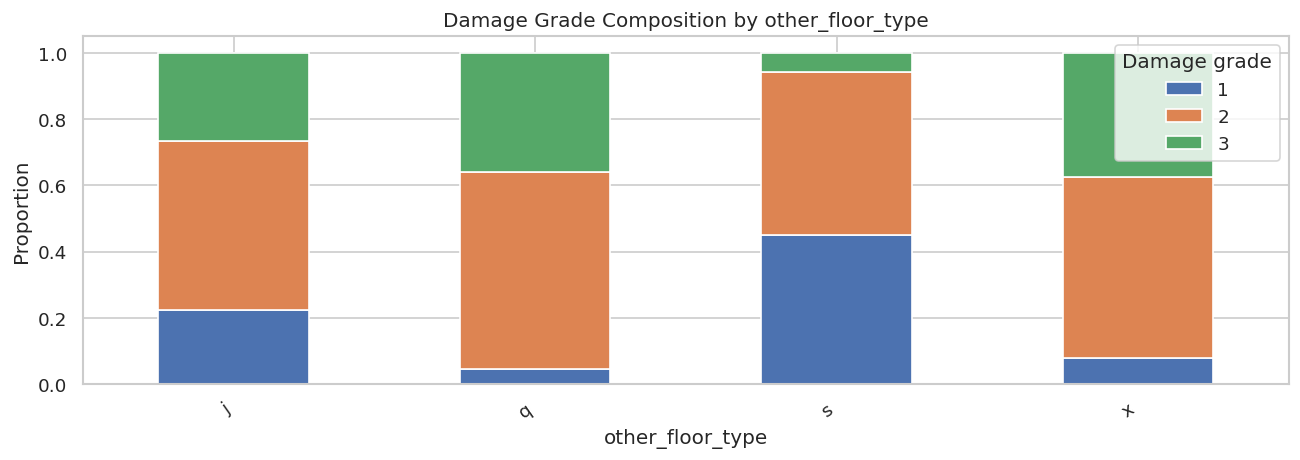

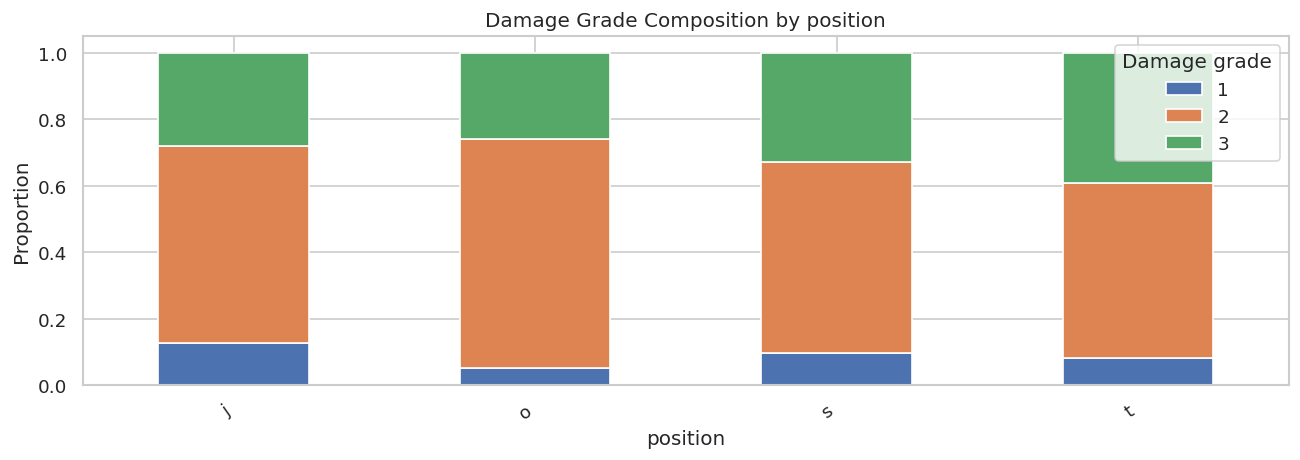

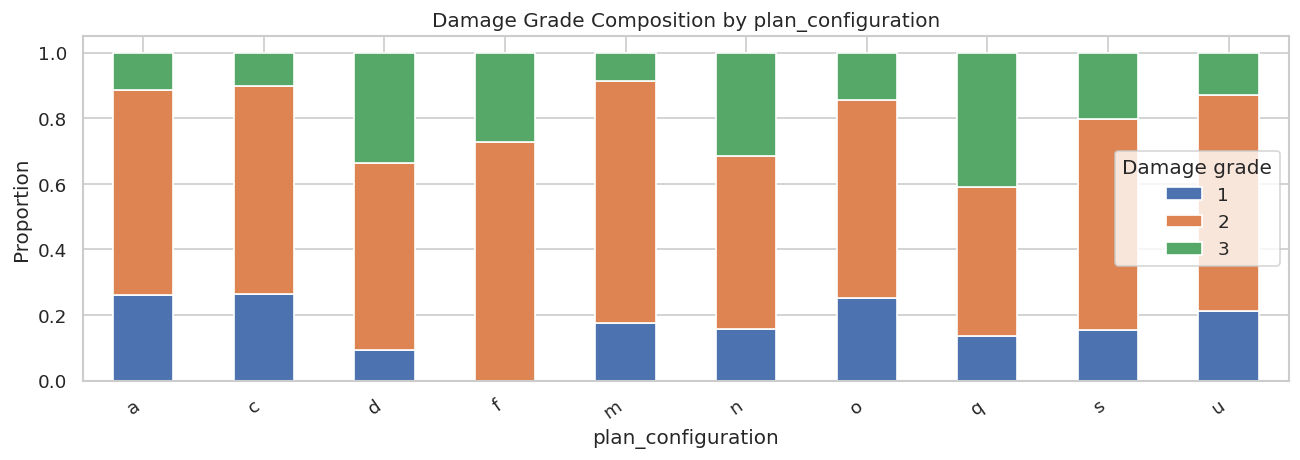

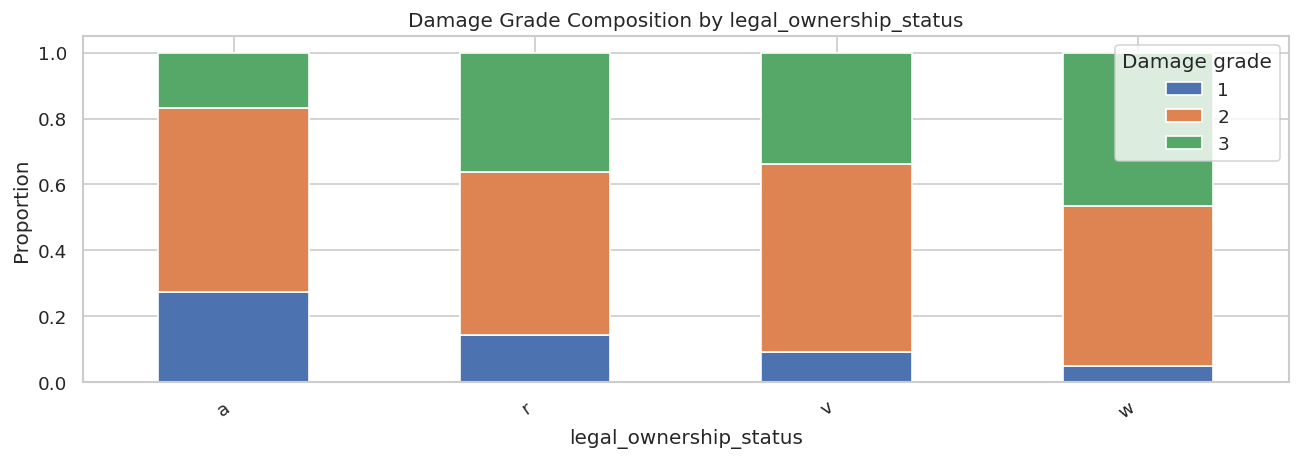


SUPERSTRUCTURE INDICATOR PREVALENCE BY DAMAGE GRADE


damage_grade,1,2,3
has_superstructure_adobe_mud,0.024,0.094,0.099
has_superstructure_mud_mortar_stone,0.349,0.769,0.870
has_superstructure_stone_flag,0.007,0.031,0.049
has_superstructure_cement_mortar_stone,0.033,0.022,0.008
has_superstructure_mud_mortar_brick,0.025,0.079,0.062
has_superstructure_cement_mortar_brick,0.283,0.077,0.012
has_superstructure_timber,0.304,0.271,0.213
has_superstructure_bamboo,0.113,0.094,0.061
has_superstructure_rc_non_engineered,0.154,0.039,0.016
has_superstructure_rc_engineered,0.106,0.009,0.001


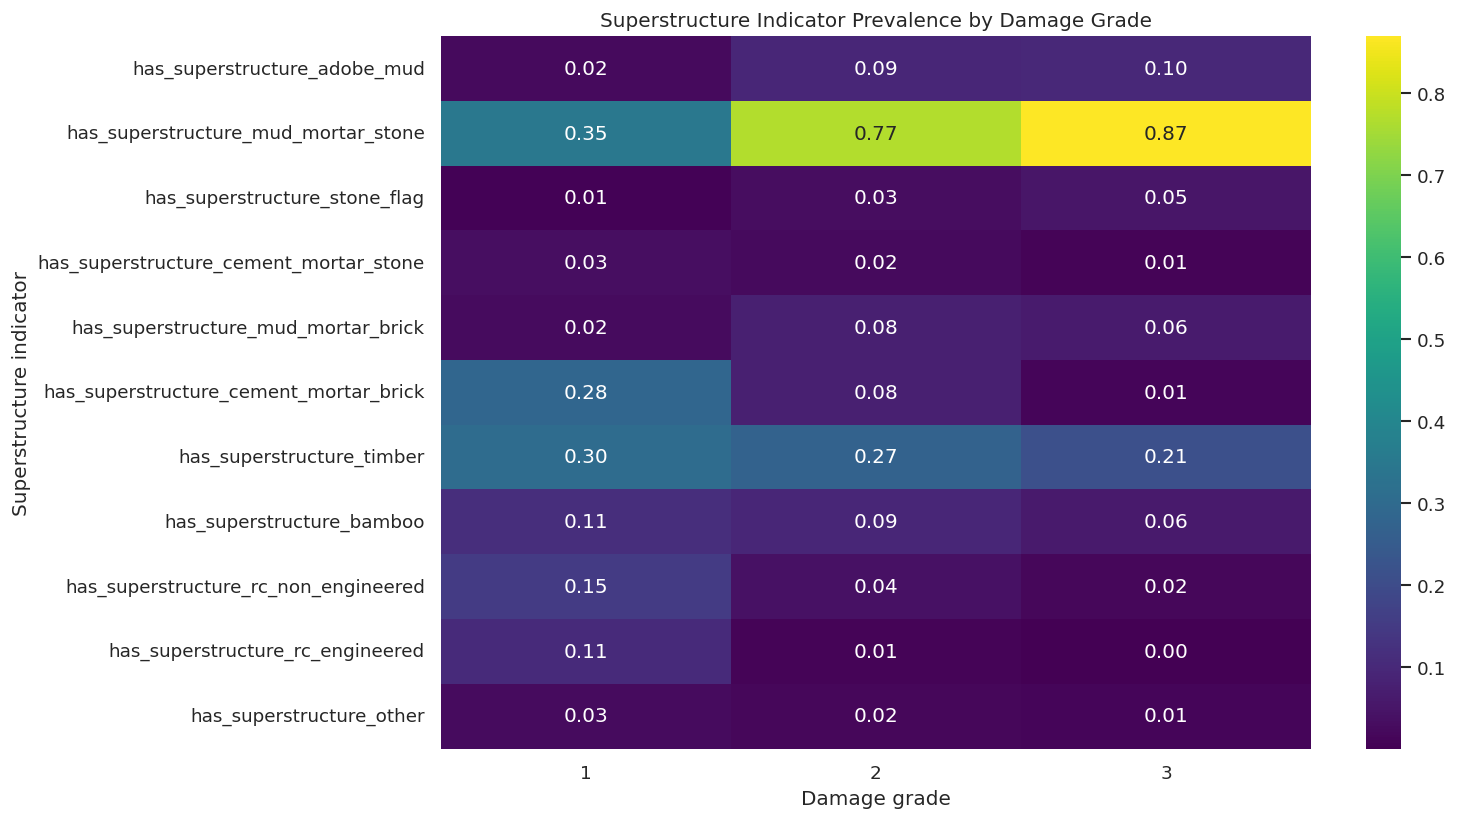


SECONDARY USE INDICATOR PREVALENCE


damage_grade,1,2,3
has_secondary_use_agriculture,0.033,0.072,0.060
has_secondary_use_hotel,0.088,0.034,0.017
has_secondary_use_rental,0.035,0.007,0.002
has_secondary_use_institution,0.004,0.001,0.000
has_secondary_use_school,0.001,0.000,0.000
has_secondary_use_industry,0.002,0.001,0.001
has_secondary_use_health_post,0.000,0.000,0.000
has_secondary_use_gov_office,0.001,0.000,0.000
has_secondary_use_use_police,0.000,0.000,0.000
has_secondary_use_other,0.007,0.006,0.004



GEOGRAPHIC DAMAGE SUMMARY


,building_count,grade_3_rate,grade_1_rate
geo_level_1_id,,,
6,24381,0.248,0.086
26,22615,0.086,0.355
10,22079,0.397,0.055
17,21813,0.808,0.013
8,19080,0.520,0.034
7,18994,0.352,0.054
20,17216,0.119,0.192
21,14889,0.585,0.022
4,14568,0.198,0.036


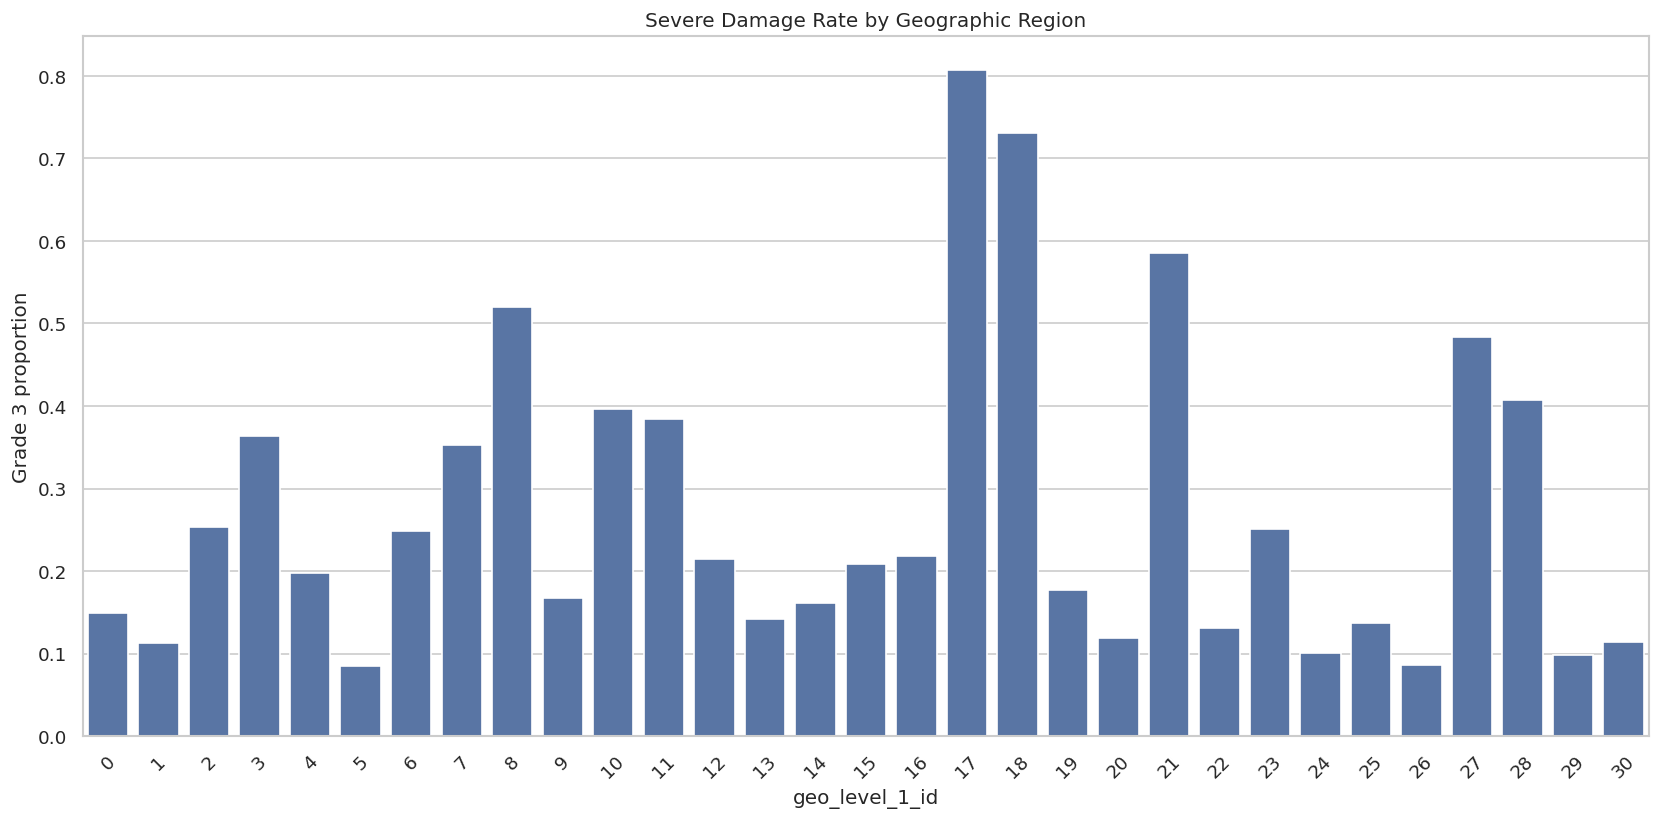


geo_level_1_id: TOP 15 GROUPS BY BUILDING COUNT


,building_count,grade_3_rate
geo_level_1_id,,
6,24381,0.248
26,22615,0.086
10,22079,0.397
17,21813,0.808
8,19080,0.520
7,18994,0.352
20,17216,0.119
21,14889,0.585
4,14568,0.198



geo_level_2_id: TOP 15 GROUPS BY BUILDING COUNT


,building_count,grade_3_rate
geo_level_2_id,,
39,4038,0.040
158,2520,0.107
181,2080,0.324
1387,2040,0.256
157,1897,0.158
363,1760,0.601
463,1740,0.378
673,1704,0.063
533,1684,0.587



geo_level_3_id: TOP 15 GROUPS BY BUILDING COUNT


,building_count,grade_3_rate
geo_level_3_id,,
633,651,0.009
9133,647,0.023
621,530,0.057
11246,470,0.055
2005,466,0.077
11440,455,0.057
7723,443,0.093
9229,381,0.115
2452,349,0.100



EDA CHECKPOINT
{
  "observations": 260601,
  "unique_buildings": 260601,
  "target_classes": [
    1,
    2,
    3
  ],
  "numeric_features_examined": 5,
  "categorical_features_examined": 8,
  "geographic_features_examined": 3,
  "superstructure_indicators": 11,
  "secondary_use_indicators": 10,
  "majority_class_baseline": 0.5689118614280068
}

SECTION 02 COMPLETE


In [7]:

# ============================================================
# 02 | EXPLORATORY DATA ANALYSIS
# ============================================================

# Merge features and labels for descriptive analysis
eda = train_values.merge(
    train_labels[[ID_COLUMN, TARGET]],
    on=ID_COLUMN,
    how="inner",
    validate="one_to_one"
)

assert len(eda) == len(train_values)

# -----------------------------
# Feature groups
# -----------------------------
numeric_features = [
    "age",
    "count_floors_pre_eq",
    "area_percentage",
    "height_percentage",
    "count_families"
]

categorical_features = [
    "land_surface_condition",
    "foundation_type",
    "roof_type",
    "ground_floor_type",
    "other_floor_type",
    "position",
    "plan_configuration",
    "legal_ownership_status"
]

geographic_features = [
    "geo_level_1_id",
    "geo_level_2_id",
    "geo_level_3_id"
]

superstructure_features = [
    col for col in eda.columns
    if col.startswith("has_superstructure_")
]

secondary_use_features = [
    col for col in eda.columns
    if col.startswith("has_secondary_use_")
    and col != "has_secondary_use"
]

# -----------------------------
# Target distribution
# -----------------------------
target_counts = (
    eda[TARGET]
    .value_counts()
    .sort_index()
)

target_percentages = (
    eda[TARGET]
    .value_counts(normalize=True)
    .sort_index() * 100
)

target_summary = pd.DataFrame({
    "building_count": target_counts,
    "percentage": target_percentages
})

majority_baseline = target_counts.max() / target_counts.sum()

print("=" * 72)
print("TARGET DISTRIBUTION")
print("=" * 72)
display(target_summary.round(2))
print(f"Majority-class baseline accuracy: {majority_baseline:.4f} "
      f"({majority_baseline:.2%})")

# -----------------------------
# Target distribution plot
# -----------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    x=target_counts.index.astype(str),
    y=target_counts.values,
    ax=axes[0]
)
axes[0].set_title("Building Counts by Damage Grade")
axes[0].set_xlabel("Damage grade")
axes[0].set_ylabel("Number of buildings")

axes[1].pie(
    target_counts.values,
    labels=[f"Grade {x}" for x in target_counts.index],
    autopct="%1.1f%%",
    startangle=90
)
axes[1].set_title("Damage Grade Composition")

plt.tight_layout()
plt.show()

# -----------------------------
# Numeric characteristics
# -----------------------------
numeric_summary = (
    eda.groupby(TARGET)[numeric_features]
    .median()
    .T
)

print("\nMEDIAN NUMERIC CHARACTERISTICS BY DAMAGE GRADE")
print("=" * 72)
display(numeric_summary)

fig, axes = plt.subplots(
    len(numeric_features),
    1,
    figsize=(12, 4 * len(numeric_features))
)

for ax, feature in zip(axes, numeric_features):
    sns.boxplot(
        data=eda,
        x=TARGET,
        y=feature,
        showfliers=False,
        ax=ax
    )
    ax.set_title(f"{feature} by Damage Grade")
    ax.set_xlabel("Damage grade")

plt.tight_layout()
plt.show()

# -----------------------------
# Structural categorical features
# -----------------------------
for feature in categorical_features:

    distribution = pd.crosstab(
        eda[feature],
        eda[TARGET],
        normalize="index"
    )

    plt.figure(figsize=(11, 4))
    distribution.plot(
        kind="bar",
        stacked=True,
        ax=plt.gca()
    )
    plt.title(f"Damage Grade Composition by {feature}")
    plt.xlabel(feature)
    plt.ylabel("Proportion")
    plt.legend(title="Damage grade")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

# -----------------------------
# Superstructure indicators
# -----------------------------
superstructure_rates = (
    eda.groupby(TARGET)[superstructure_features]
    .mean()
    .T
)

print("\nSUPERSTRUCTURE INDICATOR PREVALENCE BY DAMAGE GRADE")
print("=" * 72)
display(superstructure_rates.round(3))

plt.figure(figsize=(13, 7))
sns.heatmap(
    superstructure_rates,
    annot=True,
    fmt=".2f",
    cmap="viridis"
)
plt.title("Superstructure Indicator Prevalence by Damage Grade")
plt.xlabel("Damage grade")
plt.ylabel("Superstructure indicator")
plt.tight_layout()
plt.show()

# -----------------------------
# Secondary use indicators
# -----------------------------
secondary_rates = (
    eda.groupby(TARGET)[secondary_use_features]
    .mean()
    .T
)

print("\nSECONDARY USE INDICATOR PREVALENCE")
display(secondary_rates.round(3))

# -----------------------------
# Geographic damage summary
# -----------------------------
geo_summary = (
    eda.groupby("geo_level_1_id")
    .agg(
        building_count=(TARGET, "size"),
        grade_3_rate=(TARGET, lambda x: (x == 3).mean()),
        grade_1_rate=(TARGET, lambda x: (x == 1).mean())
    )
    .sort_values("building_count", ascending=False)
)

print("\nGEOGRAPHIC DAMAGE SUMMARY")
print("=" * 72)
display(geo_summary.head(20).round(3))

# -----------------------------
# Geographic severity visualization
# -----------------------------
geo_plot = geo_summary.sort_values("grade_3_rate", ascending=False)

plt.figure(figsize=(14, 7))
sns.barplot(
    data=geo_plot.reset_index(),
    x="geo_level_1_id",
    y="grade_3_rate"
)
plt.title("Severe Damage Rate by Geographic Region")
plt.xlabel("geo_level_1_id")
plt.ylabel("Grade 3 proportion")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# -----------------------------
# Damage grade by geographic level
# -----------------------------
for geo_feature in geographic_features:

    geo_counts = (
        eda.groupby(geo_feature)
        .agg(
            building_count=(TARGET, "size"),
            grade_3_rate=(TARGET, lambda x: (x == 3).mean())
        )
        .sort_values("building_count", ascending=False)
    )

    print(f"\n{geo_feature}: TOP 15 GROUPS BY BUILDING COUNT")
    display(geo_counts.head(15).round(3))

# -----------------------------
# EDA checkpoint
# -----------------------------
eda_checkpoint = {
    "observations": int(len(eda)),
    "unique_buildings": int(eda[ID_COLUMN].nunique()),
    "target_classes": sorted(
        [int(x) for x in eda[TARGET].unique()]
    ),
    "numeric_features_examined": len(numeric_features),
    "categorical_features_examined": len(categorical_features),
    "geographic_features_examined": len(geographic_features),
    "superstructure_indicators": len(superstructure_features),
    "secondary_use_indicators": len(secondary_use_features),
    "majority_class_baseline": float(majority_baseline)
}

with open(ARTIFACT_DIR / "eda_checkpoint.json", "w") as f:
    json.dump(eda_checkpoint, f, indent=2)

print("\nEDA CHECKPOINT")
print("=" * 72)
print(json.dumps(eda_checkpoint, indent=2))
print("\nSECTION 02 COMPLETE")



# 03 | Feature Engineering and Validation Design

This section constructs a modeling table and derives additional building-level features from the original competition predictors.

Engineered features include:

- Log-transformed building age
- Age bands
- Height and area relative to the number of floors
- Height-to-area ratio
- Counts of superstructure and secondary-use indicators
- Multi-story and older-building flags

The original geographic identifiers and structural categorical variables are retained. Geographic IDs are treated as categorical identifiers rather than continuous measurements.

A stratified 80/20 split is created with a fixed random seed. The 80% development partition is reserved for cross-validation. The 20% holdout partition remains untouched by the cross-validation benchmark and is retained for a later independent evaluation.


In [8]:

# ============================================================
# 03 | FEATURE ENGINEERING AND VALIDATION DESIGN
# ============================================================

from sklearn.model_selection import train_test_split

TARGET = "damage_grade"
ID_COLUMN = "building_id"
RANDOM_STATE = 42

# -----------------------------
# Combine training features/labels
# -----------------------------
model_data = train_values.merge(
    train_labels[[ID_COLUMN, TARGET]],
    on=ID_COLUMN,
    how="inner",
    validate="one_to_one"
)

assert len(model_data) == len(train_values)
assert model_data[TARGET].notna().all()

# -----------------------------
# Feature groups
# -----------------------------
geographic_features = [
    "geo_level_1_id",
    "geo_level_2_id",
    "geo_level_3_id"
]

categorical_features = [
    "land_surface_condition",
    "foundation_type",
    "roof_type",
    "ground_floor_type",
    "other_floor_type",
    "position",
    "plan_configuration",
    "legal_ownership_status"
]

superstructure_features = [
    col for col in model_data.columns
    if col.startswith("has_superstructure_")
]

secondary_use_features = [
    col for col in model_data.columns
    if col.startswith("has_secondary_use_")
    and col != "has_secondary_use"
]

# -----------------------------
# Feature engineering function
# -----------------------------
def engineer_features(data):

    data = data.copy()

    # Building age transformations
    data["age_log1p"] = np.log1p(
        data["age"].clip(lower=0)
    )

    data["age_group"] = pd.cut(
        data["age"],
        bins=[-1, 5, 15, 30, 60, np.inf],
        labels=["0-5", "6-15", "16-30", "31-60", "60+"]
    ).astype(str)

    # Structural proportions
    floors = data["count_floors_pre_eq"].clip(lower=1)

    data["height_per_floor"] = (
        data["height_percentage"] / floors
    )

    data["area_per_floor"] = (
        data["area_percentage"] / floors
    )

    data["height_area_ratio"] = (
        data["height_percentage"] /
        data["area_percentage"].clip(lower=1)
    )

    # Material and use counts
    data["superstructure_count"] = (
        data[superstructure_features].sum(axis=1)
    )

    data["secondary_use_count"] = (
        data[secondary_use_features].sum(axis=1)
    )

    # Building profile indicators
    data["is_multi_story"] = (
        data["count_floors_pre_eq"] > 1
    ).astype("int8")

    data["is_old_building"] = (
        data["age"] >= 30
    ).astype("int8")

    return data


engineered_data = engineer_features(model_data)

# -----------------------------
# Build modeling matrix
# -----------------------------
feature_columns = [
    col for col in engineered_data.columns
    if col not in [ID_COLUMN, TARGET]
]

X = engineered_data[feature_columns].copy()
y = engineered_data[TARGET].copy()

# -----------------------------
# Categorical model features
# -----------------------------
categorical_model_features = (
    geographic_features
    + categorical_features
    + ["age_group"]
)

for col in categorical_model_features:
    X[col] = X[col].astype(str)

# -----------------------------
# Stratified holdout split
# -----------------------------
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# -----------------------------
# Validation checks
# -----------------------------
assert len(X_train) + len(X_valid) == len(X)
assert len(y_train) == len(X_train)
assert len(y_valid) == len(X_valid)
assert X_train.columns.tolist() == X_valid.columns.tolist()
assert X_train.isna().sum().sum() == 0
assert X_valid.isna().sum().sum() == 0

# -----------------------------
# Report
# -----------------------------
print("=" * 72)
print("FEATURE ENGINEERING AND VALIDATION DESIGN")
print("=" * 72)

print(f"Total observations:             {len(X):,}")
print(f"Original predictors:            {train_values.shape[1] - 1}")
print(f"Engineered predictors:          {len(feature_columns)}")
print(f"Categorical predictors:         {len(categorical_model_features)}")
print(f"Superstructure indicators:      {len(superstructure_features)}")
print(f"Secondary-use indicators:       {len(secondary_use_features)}")

print("\nEngineered feature summary")
display(
    engineered_data[
        [
            "age",
            "age_log1p",
            "height_per_floor",
            "area_per_floor",
            "height_area_ratio",
            "superstructure_count",
            "secondary_use_count"
        ]
    ].describe().T.round(3)
)

print("\nValidation partition")
print("-" * 72)
print(f"Development training rows:      {len(X_train):,}")
print(f"Independent holdout rows:       {len(X_valid):,}")
print(f"Total rows:                     {len(X):,}")

split_distribution = pd.DataFrame({
    "Full dataset": y.value_counts(normalize=True).sort_index(),
    "Development": y_train.value_counts(normalize=True).sort_index(),
    "Holdout": y_valid.value_counts(normalize=True).sort_index()
}) * 100

split_distribution.index.name = TARGET

print("\nTarget distribution across partitions (%)")
display(split_distribution.round(2))

# -----------------------------
# Persist feature metadata
# -----------------------------
feature_metadata = {
    "target": TARGET,
    "id_column": ID_COLUMN,
    "random_state": RANDOM_STATE,
    "feature_count": len(feature_columns),
    "categorical_features": categorical_model_features,
    "feature_columns": feature_columns,
    "development_rows": len(X_train),
    "holdout_rows": len(X_valid)
}

with open(ARTIFACT_DIR / "feature_metadata.json", "w") as f:
    json.dump(feature_metadata, f, indent=2)

print("\nSECTION 03 COMPLETE")
print("The independent holdout remains separate from cross-validation.")


FEATURE ENGINEERING AND VALIDATION DESIGN
Total observations:             260,601
Original predictors:            38
Engineered predictors:          47
Categorical predictors:         12
Superstructure indicators:      11
Secondary-use indicators:       10

Engineered feature summary


,count,mean,std,min,25%,50%,75%,max
age,260601.0,26.535,73.566,0.000,10.000,15.000,30.000,995.000
age_log1p,260601.0,2.681,1.155,0.000,2.398,2.773,3.434,6.904
height_per_floor,260601.0,2.619,0.632,0.286,2.000,2.500,3.000,32.000
area_per_floor,260601.0,4.215,3.017,0.200,2.500,3.500,5.000,86.000
height_area_ratio,260601.0,0.815,0.511,0.033,0.533,0.714,1.000,16.000
superstructure_count,260601.0,1.460,0.777,1.000,1.000,1.000,2.000,8.000
secondary_use_count,260601.0,0.114,0.324,0.000,0.000,0.000,0.000,2.000



Validation partition
------------------------------------------------------------------------
Development training rows:      208,480
Independent holdout rows:       52,121
Total rows:                     260,601

Target distribution across partitions (%)


,Full dataset,Development,Holdout
damage_grade,,,
1,9.64,9.64,9.64
2,56.89,56.89,56.89
3,33.47,33.47,33.47



SECTION 03 COMPLETE
The independent holdout remains separate from cross-validation.


## 04 | LightGBM Five-Fold Cross-Validation

This experiment evaluates LightGBM using stratified five-fold cross-validation
on the training partition.

The model uses native categorical handling for geographic and structural
categorical predictors. The independent validation holdout remains untouched.

Evaluation:
- Five stratified folds
- Multiclass classification
- Early stopping
- Fold-level accuracy and micro-F1
- Out-of-fold probability predictions
- Feature importance
- Checkpointed outputs after every completed fold

The objective is to establish a computationally efficient benchmark before
testing more expensive models and probability ensembles.

In [9]:
# ============================================================
# 04B | LIGHTGBM FIVE-FOLD CROSS-VALIDATION
# ============================================================

import os
import time
import warnings
import numpy as np
import pandas as pd

from lightgbm import LGBMClassifier, early_stopping, log_evaluation
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

RANDOM_STATE = 42
N_SPLITS = 5
N_THREADS = min(os.cpu_count() or 4, 4)

OUTPUT_DIR = "/kaggle/working/richter_benchmark"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("=" * 70)
print("LIGHTGBM FIVE-FOLD CROSS-VALIDATION")
print("=" * 70)

print(f"Training rows: {len(X_train):,}")
print(f"Features: {X_train.shape[1]}")
print(f"Categorical features: {len(categorical_model_features)}")
print(f"CPU threads: {N_THREADS}")
print(f"Folds: {N_SPLITS}")

# ------------------------------------------------------------
# 2. PREPARE CATEGORICAL FEATURES
# ------------------------------------------------------------

X_lgb = X_train.copy()

for col in categorical_model_features:
    categories = pd.Index(X_lgb[col].astype(str).unique())

    X_lgb[col] = pd.Categorical(
        X_lgb[col].astype(str),
        categories=categories
    )

y_lgb = y_train.astype(int).to_numpy() - 1

# Confirm target encoding
assert set(np.unique(y_lgb)) == {0, 1, 2}

# ------------------------------------------------------------
# 3. CROSS-VALIDATION SETUP
# ------------------------------------------------------------

skf = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

oof_probabilities = np.zeros(
    (len(X_lgb), 3),
    dtype=np.float32
)

fold_results = []
importance_results = []

# ------------------------------------------------------------
# 4. TRAIN FIVE FOLDS
# ------------------------------------------------------------

overall_start = time.time()

for fold, (train_idx, valid_idx) in enumerate(
    skf.split(X_lgb, y_lgb), start=1
):

    fold_start = time.time()

    print("\n" + "=" * 70)
    print(f"LIGHTGBM | FOLD {fold}/{N_SPLITS}")
    print("=" * 70)

    X_fold_train = X_lgb.iloc[train_idx]
    X_fold_valid = X_lgb.iloc[valid_idx]

    y_fold_train = y_lgb[train_idx]
    y_fold_valid = y_lgb[valid_idx]

    model = LGBMClassifier(
        objective="multiclass",
        num_class=3,

        n_estimators=2000,
        learning_rate=0.04,

        num_leaves=31,
        max_depth=-1,
        min_child_samples=40,

        subsample=0.85,
        subsample_freq=1,
        colsample_bytree=0.85,

        reg_alpha=0.1,
        reg_lambda=3.0,

        max_bin=255,

        random_state=RANDOM_STATE + fold,
        n_jobs=N_THREADS,
        verbosity=-1
    )

    model.fit(
        X_fold_train,
        y_fold_train,

        eval_set=[(X_fold_valid, y_fold_valid)],
        eval_metric="multi_logloss",

        callbacks=[
            early_stopping(
                stopping_rounds=100,
                verbose=False
            ),
            log_evaluation(period=200)
        ]
    )

    # --------------------------------------------------------
    # PREDICTIONS
    # --------------------------------------------------------

    probabilities = model.predict_proba(X_fold_valid)

    predictions = np.argmax(probabilities, axis=1)

    oof_probabilities[valid_idx] = probabilities

    accuracy = accuracy_score(
        y_fold_valid,
        predictions
    )

    micro_f1 = f1_score(
        y_fold_valid,
        predictions,
        average="micro"
    )

    best_iteration = model.best_iteration_

    elapsed = time.time() - fold_start

    fold_results.append({
        "fold": fold,
        "accuracy": accuracy,
        "micro_f1": micro_f1,
        "best_iteration": best_iteration,
        "training_seconds": elapsed
    })

    # --------------------------------------------------------
    # FEATURE IMPORTANCE
    # --------------------------------------------------------

    importance_results.append(
        pd.DataFrame({
            "feature": X_lgb.columns,
            "importance": model.feature_importances_,
            "fold": fold
        })
    )

    # --------------------------------------------------------
    # CHECKPOINT AFTER EVERY FOLD
    # --------------------------------------------------------

    pd.DataFrame(fold_results).to_csv(
        f"{OUTPUT_DIR}/lightgbm_fold_checkpoint.csv",
        index=False
    )

    np.savez_compressed(
        f"{OUTPUT_DIR}/lightgbm_oof_checkpoint.npz",
        probabilities=oof_probabilities
    )

    pd.concat(
        importance_results,
        ignore_index=True
    ).to_csv(
        f"{OUTPUT_DIR}/lightgbm_importance_checkpoint.csv",
        index=False
    )

    print(f"\nFold {fold} completed.")
    print(f"Accuracy:       {accuracy:.5f}")
    print(f"Micro-F1:       {micro_f1:.5f}")
    print(f"Best iteration: {best_iteration}")
    print(f"Elapsed time:   {elapsed / 60:.2f} minutes")

# ------------------------------------------------------------
# 5. FINAL CROSS-VALIDATION SUMMARY
# ------------------------------------------------------------

results_df = pd.DataFrame(fold_results)

mean_accuracy = results_df["accuracy"].mean()
std_accuracy = results_df["accuracy"].std()

mean_f1 = results_df["micro_f1"].mean()
std_f1 = results_df["micro_f1"].std()

print("\n" + "=" * 70)
print("LIGHTGBM CROSS-VALIDATION RESULTS")
print("=" * 70)

print(results_df.to_string(index=False))

print("\nMEAN PERFORMANCE")
print("-" * 50)

print(f"Accuracy: {mean_accuracy:.5f} ± {std_accuracy:.5f}")
print(f"Micro-F1: {mean_f1:.5f} ± {std_f1:.5f}")

print(
    f"\nTotal runtime: {(time.time() - overall_start) / 60:.2f} minutes"
)

# ------------------------------------------------------------
# 6. SAVE FINAL ARTIFACTS
# ------------------------------------------------------------

results_df.to_csv(
    f"{OUTPUT_DIR}/lightgbm_cv_results.csv",
    index=False
)

importance_df = pd.concat(
    importance_results,
    ignore_index=True
)

importance_summary = (
    importance_df
    .groupby("feature")["importance"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

importance_summary.to_csv(
    f"{OUTPUT_DIR}/lightgbm_feature_importance.csv",
    index=False
)

np.savez_compressed(
    f"{OUTPUT_DIR}/lightgbm_oof_probabilities.npz",
    probabilities=oof_probabilities,
    targets=y_lgb
)

print("\nSAVED ARTIFACTS")
print("-" * 50)

for filename in [
    "lightgbm_cv_results.csv",
    "lightgbm_feature_importance.csv",
    "lightgbm_oof_probabilities.npz"
]:
    print(f"✓ {filename}")

print("\nTOP 20 FEATURES")
print("-" * 50)
print(importance_summary.head(20).to_string(index=False))

print("\nLIGHTGBM BENCHMARK COMPLETE.")

LIGHTGBM FIVE-FOLD CROSS-VALIDATION
Training rows: 208,480
Features: 47
Categorical features: 12
CPU threads: 4
Folds: 5

LIGHTGBM | FOLD 1/5
[200]	valid_0's multi_logloss: 0.569972

Fold 1 completed.
Accuracy:       0.74847
Micro-F1:       0.74847
Best iteration: 282
Elapsed time:   0.74 minutes

LIGHTGBM | FOLD 2/5
[200]	valid_0's multi_logloss: 0.567819
[400]	valid_0's multi_logloss: 0.566703

Fold 2 completed.
Accuracy:       0.74775
Micro-F1:       0.74775
Best iteration: 342
Elapsed time:   0.87 minutes

LIGHTGBM | FOLD 3/5
[200]	valid_0's multi_logloss: 0.570151
[400]	valid_0's multi_logloss: 0.569522

Fold 3 completed.
Accuracy:       0.74911
Micro-F1:       0.74911
Best iteration: 303
Elapsed time:   0.79 minutes

LIGHTGBM | FOLD 4/5
[200]	valid_0's multi_logloss: 0.569854
[400]	valid_0's multi_logloss: 0.569412

Fold 4 completed.
Accuracy:       0.74583
Micro-F1:       0.74583
Best iteration: 314
Elapsed time:   0.81 minutes

LIGHTGBM | FOLD 5/5
[200]	valid_0's multi_logloss:

## 05 | Independent Holdout Validation

The selected LightGBM configuration is refitted on the complete training
partition using 306 boosting iterations, based on the five-fold benchmark.

It is then evaluated once on the independent validation holdout.

Evaluation includes:
- Overall accuracy and micro-F1
- Per-class precision, recall, and F1
- Confusion matrix
- Comparison with the majority-class baseline

This provides an independent generalization check before further model
development.

INDEPENDENT HOLDOUT VALIDATION
Training rows: 208,480
Holdout rows:  52,121
Boosting rounds: 306

Model training completed in 0.58 minutes.

HOLDOUT PERFORMANCE
Accuracy:             0.75271
Micro-F1:             0.75271
Training baseline:    0.56891
Improvement:          0.18380

PER-CLASS PERFORMANCE
                precision  recall  f1-score     support
Damage Grade 1     0.6751  0.5707    0.6186   5025.0000
Damage Grade 2     0.7571  0.8431    0.7978  29652.0000
Damage Grade 3     0.7651  0.6515    0.7037  17444.0000
accuracy           0.7527  0.7527    0.7527      0.7527
macro avg          0.7325  0.6884    0.7067  52121.0000
weighted avg       0.7519  0.7527    0.7490  52121.0000


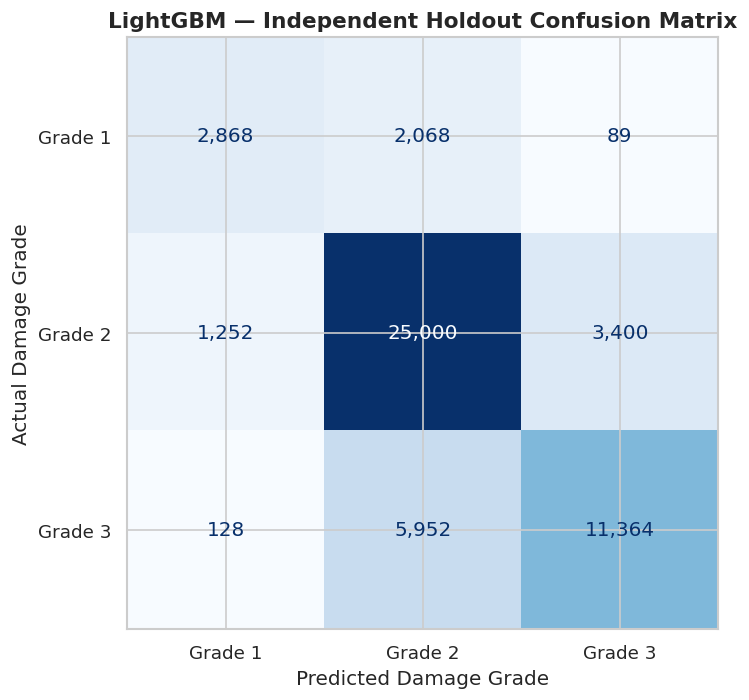


HOLDOUT EVALUATION COMPLETE
Saved outputs to: /kaggle/working/richter_benchmark
✓ holdout_classification_report.csv
✓ holdout_confusion_matrix.png
✓ holdout_predictions.csv
✓ holdout_summary.csv


In [10]:
# ============================================================
# 05 | INDEPENDENT HOLDOUT VALIDATION — LIGHTGBM
# ============================================================

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lightgbm import LGBMClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

OUTPUT_DIR = "/kaggle/working/richter_benchmark"
os.makedirs(OUTPUT_DIR, exist_ok=True)

BEST_ITERATIONS = 306
N_THREADS = min(os.cpu_count() or 4, 4)

print("=" * 70)
print("INDEPENDENT HOLDOUT VALIDATION")
print("=" * 70)

print(f"Training rows: {len(X_train):,}")
print(f"Holdout rows:  {len(X_valid):,}")
print(f"Boosting rounds: {BEST_ITERATIONS}")

# ------------------------------------------------------------
# 2. ALIGN CATEGORICAL LEVELS
# ------------------------------------------------------------

X_fit = X_train.copy()
X_holdout = X_valid.copy()

for col in categorical_model_features:

    combined_categories = pd.Index(
        pd.concat(
            [
                X_fit[col].astype(str),
                X_holdout[col].astype(str)
            ],
            ignore_index=True
        ).unique()
    )

    X_fit[col] = pd.Categorical(
        X_fit[col].astype(str),
        categories=combined_categories
    )

    X_holdout[col] = pd.Categorical(
        X_holdout[col].astype(str),
        categories=combined_categories
    )

y_fit = y_train.astype(int).to_numpy() - 1
y_holdout = y_valid.astype(int).to_numpy() - 1

assert set(np.unique(y_fit)) == {0, 1, 2}
assert set(np.unique(y_holdout)) == {0, 1, 2}

# ------------------------------------------------------------
# 3. TRAIN FINAL HOLDOUT-CHECK MODEL
# ------------------------------------------------------------

model = LGBMClassifier(
    objective="multiclass",
    num_class=3,

    n_estimators=BEST_ITERATIONS,
    learning_rate=0.04,

    num_leaves=31,
    max_depth=-1,
    min_child_samples=40,

    subsample=0.85,
    subsample_freq=1,
    colsample_bytree=0.85,

    reg_alpha=0.1,
    reg_lambda=3.0,

    max_bin=255,

    random_state=42,
    n_jobs=N_THREADS,
    verbosity=-1
)

start_time = time.time()

model.fit(
    X_fit,
    y_fit,
    categorical_feature=categorical_model_features
)

training_seconds = time.time() - start_time

print(f"\nModel training completed in {training_seconds / 60:.2f} minutes.")

# ------------------------------------------------------------
# 4. HOLDOUT PREDICTIONS
# ------------------------------------------------------------

probabilities = model.predict_proba(X_holdout)

predictions = np.argmax(probabilities, axis=1)

# Convert encoded labels 0, 1, 2 back to 1, 2, 3
predictions_competition = predictions + 1
actual_competition = y_holdout + 1

# ------------------------------------------------------------
# 5. OVERALL METRICS
# ------------------------------------------------------------

holdout_accuracy = accuracy_score(
    actual_competition,
    predictions_competition
)

holdout_micro_f1 = f1_score(
    actual_competition,
    predictions_competition,
    average="micro"
)

majority_baseline = (
    pd.Series(y_fit).value_counts(normalize=True).max()
)

print("\n" + "=" * 70)
print("HOLDOUT PERFORMANCE")
print("=" * 70)

print(f"Accuracy:             {holdout_accuracy:.5f}")
print(f"Micro-F1:             {holdout_micro_f1:.5f}")
print(f"Training baseline:    {majority_baseline:.5f}")
print(f"Improvement:          {holdout_accuracy - majority_baseline:.5f}")

# ------------------------------------------------------------
# 6. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PER-CLASS PERFORMANCE")
print("=" * 70)

report = classification_report(
    actual_competition,
    predictions_competition,
    labels=[1, 2, 3],
    target_names=[
        "Damage Grade 1",
        "Damage Grade 2",
        "Damage Grade 3"
    ],
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T

print(report_df.round(4).to_string())

report_df.to_csv(
    f"{OUTPUT_DIR}/holdout_classification_report.csv"
)

# ------------------------------------------------------------
# 7. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    actual_competition,
    predictions_competition,
    labels=[1, 2, 3]
)

fig, ax = plt.subplots(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Grade 1",
        "Grade 2",
        "Grade 3"
    ]
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format=",",
    colorbar=False
)

ax.set_title(
    "LightGBM — Independent Holdout Confusion Matrix",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Predicted Damage Grade")
ax.set_ylabel("Actual Damage Grade")

plt.tight_layout()
plt.savefig(
    f"{OUTPUT_DIR}/holdout_confusion_matrix.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 8. SAVE PREDICTIONS AND SUMMARY
# ------------------------------------------------------------

holdout_predictions = pd.DataFrame({
    "actual_damage_grade": actual_competition,
    "predicted_damage_grade": predictions_competition,
    "probability_grade_1": probabilities[:, 0],
    "probability_grade_2": probabilities[:, 1],
    "probability_grade_3": probabilities[:, 2]
})

holdout_predictions.to_csv(
    f"{OUTPUT_DIR}/holdout_predictions.csv",
    index=False
)

summary = pd.DataFrame([{
    "model": "LightGBM",
    "boosting_iterations": BEST_ITERATIONS,
    "cv_micro_f1": 0.74710,
    "holdout_accuracy": holdout_accuracy,
    "holdout_micro_f1": holdout_micro_f1,
    "training_seconds": training_seconds
}])

summary.to_csv(
    f"{OUTPUT_DIR}/holdout_summary.csv",
    index=False
)

print("\n" + "=" * 70)
print("HOLDOUT EVALUATION COMPLETE")
print("=" * 70)

print(f"Saved outputs to: {OUTPUT_DIR}")
print("✓ holdout_classification_report.csv")
print("✓ holdout_confusion_matrix.png")
print("✓ holdout_predictions.csv")
print("✓ holdout_summary.csv")

## 06 | Leakage-Safe Geographic Target Encoding

Geographic identifiers were the three most influential predictors in the
initial LightGBM benchmark.

This experiment introduces smoothed geographic damage-rate features.

For each geographic group, the model receives estimates of the probability
of each damage grade. These estimates are generated using cross-fitting so
that no training observation contributes its own target label to its
encoded features.

The experiment evaluates:
- Original 47 engineered predictors
- Geographic target-encoded predictors
- Five-fold stratified cross-validation
- Independent holdout performance
- Per-class precision, recall, and F1
- Confusion matrix
- Feature importance

The independent holdout remains excluded from model fitting and target
encoding.

GEOGRAPHIC TARGET ENCODING EXPERIMENT
Training rows: 208,480
Independent holdout rows: 52,121
Geographic encodings: 5
Inner folds: 5
Outer folds: 5
Smoothing: 20

STARTING NESTED GEOGRAPHIC CROSS-VALIDATION

OUTER FOLD 1/5
Accuracy: 0.74820
Micro-F1: 0.74820
Elapsed: 0.86 minutes

OUTER FOLD 2/5
Accuracy: 0.74746
Micro-F1: 0.74746
Elapsed: 0.86 minutes

OUTER FOLD 3/5
Accuracy: 0.74794
Micro-F1: 0.74794
Elapsed: 0.86 minutes

OUTER FOLD 4/5
Accuracy: 0.74477
Micro-F1: 0.74477
Elapsed: 0.90 minutes

OUTER FOLD 5/5
Accuracy: 0.74340
Micro-F1: 0.74340
Elapsed: 0.94 minutes

GEOGRAPHIC MODEL CROSS-VALIDATION
 fold  accuracy  micro_f1  training_seconds
    1  0.748201  0.748201         51.811533
    2  0.747458  0.747458         51.795188
    3  0.747937  0.747937         51.714381
    4  0.744772  0.744772         53.869981
    5  0.743405  0.743405         56.412027

Mean micro-F1: 0.74635
Standard deviation: 0.00214
Total CV time: 4.44 minutes

INDEPENDENT HOLDOUT EVALUATION
Original fea

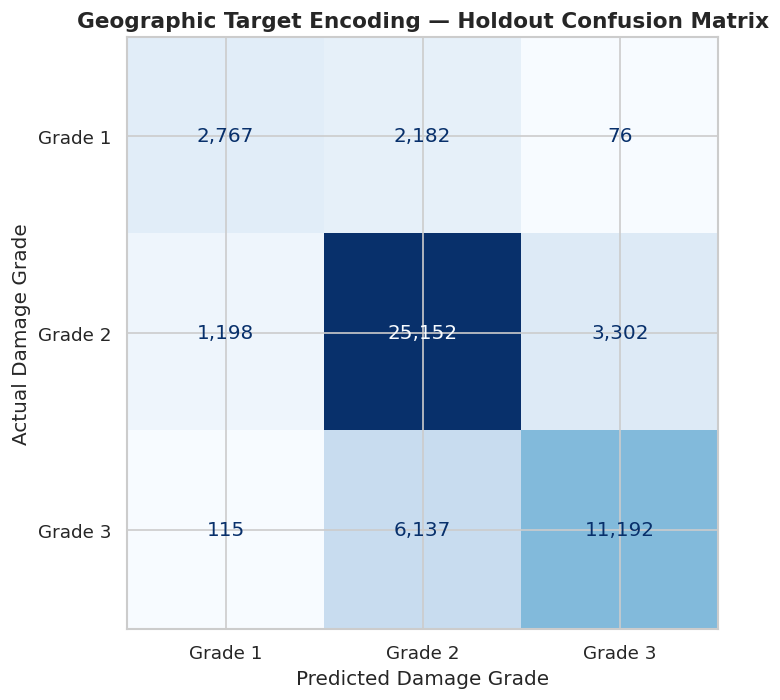


TOP 25 FEATURES
                               feature  importance
                        geo_level_3_id     13878.4
                        geo_level_2_id      8298.8
              geo3_damage_grade_2_rate       701.8
              geo3_damage_grade_1_rate       560.8
                                   age       491.2
                        geo_level_1_id       323.0
                       foundation_type       248.6
                      other_floor_type       226.8
   has_superstructure_mud_mortar_stone       214.2
              geo3_damage_grade_3_rate       204.6
                       area_percentage       204.2
                     ground_floor_type       201.6
              geo2_damage_grade_3_rate       186.8
                        count_families       152.2
                             roof_type       138.2
              geo2_damage_grade_1_rate       138.0
              geo2_damage_grade_2_rate       120.0
has_superstructure_cement_mortar_brick       114.8
    geo1_geo2_

In [11]:
# ============================================================
# 06 | LEAKAGE-SAFE GEOGRAPHIC TARGET ENCODING
# ============================================================

import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lightgbm import LGBMClassifier, log_evaluation
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

RANDOM_STATE = 42
OUTER_FOLDS = 5
INNER_FOLDS = 5
SMOOTHING = 20
N_THREADS = min(os.cpu_count() or 4, 4)

OUTPUT_DIR = "/kaggle/working/richter_benchmark"
os.makedirs(OUTPUT_DIR, exist_ok=True)

GEO_SPECS = {
    "geo1": ["geo_level_1_id"],
    "geo2": ["geo_level_2_id"],
    "geo3": ["geo_level_3_id"],
    "geo1_geo2": ["geo_level_1_id", "geo_level_2_id"],
    "geo1_geo2_geo3": [
        "geo_level_1_id",
        "geo_level_2_id",
        "geo_level_3_id"
    ]
}

BEST_ITERATIONS = 306

print("=" * 70)
print("GEOGRAPHIC TARGET ENCODING EXPERIMENT")
print("=" * 70)

print(f"Training rows: {len(X_train):,}")
print(f"Independent holdout rows: {len(X_valid):,}")
print(f"Geographic encodings: {len(GEO_SPECS)}")
print(f"Inner folds: {INNER_FOLDS}")
print(f"Outer folds: {OUTER_FOLDS}")
print(f"Smoothing: {SMOOTHING}")

# ------------------------------------------------------------
# 2. GEOGRAPHIC KEY GENERATION
# ------------------------------------------------------------

def make_geo_key(data, columns):

    if len(columns) == 1:
        return data[columns[0]].astype(str)

    return (
        data[columns]
        .astype(str)
        .agg("::".join, axis=1)
    )


# ------------------------------------------------------------
# 3. FIT SMOOTHED GEOGRAPHIC TARGET ENCODINGS
# ------------------------------------------------------------

def fit_geo_encoders(data, targets):

    targets = np.asarray(targets, dtype=np.int8)

    global_prior = np.bincount(
        targets,
        minlength=3
    ).astype(float)

    global_prior /= global_prior.sum()

    encoders = {}

    for name, columns in GEO_SPECS.items():

        keys = make_geo_key(data, columns)

        temp = pd.DataFrame({
            "key": keys.to_numpy(),
            "grade_0": (targets == 0).astype(np.float32),
            "grade_1": (targets == 1).astype(np.float32),
            "grade_2": (targets == 2).astype(np.float32)
        })

        grouped = temp.groupby("key", sort=False).agg({
            "grade_0": "sum",
            "grade_1": "sum",
            "grade_2": "sum"
        })

        counts = temp.groupby("key", sort=False).size()

        encoded = (
            grouped.to_numpy()
            + SMOOTHING * global_prior
        ) / (
            counts.to_numpy().reshape(-1, 1)
            + SMOOTHING
        )

        mapping = {
            key: value
            for key, value in zip(grouped.index, encoded)
        }

        encoders[name] = {
            "mapping": mapping,
            "prior": global_prior,
            "columns": columns
        }

    return encoders


# ------------------------------------------------------------
# 4. APPLY GEOGRAPHIC ENCODINGS
# ------------------------------------------------------------

def apply_geo_encoders(data, encoders):

    encoded_features = {}

    for name, encoder in encoders.items():

        keys = make_geo_key(
            data,
            encoder["columns"]
        )

        mapping = encoder["mapping"]
        prior = encoder["prior"]

        values = np.vstack([
            mapping.get(key, prior)
            for key in keys
        ])

        for grade in range(3):

            encoded_features[
                f"{name}_damage_grade_{grade + 1}_rate"
            ] = values[:, grade]

    return pd.DataFrame(
        encoded_features,
        index=data.index
    )


# ------------------------------------------------------------
# 5. GENERATE LEAKAGE-SAFE OOF ENCODINGS
# ------------------------------------------------------------

def crossfit_geo_encodings(
    training_data,
    training_targets,
    application_data,
    random_state=42
):

    training_targets = np.asarray(
        training_targets,
        dtype=np.int8
    )

    inner_cv = StratifiedKFold(
        n_splits=INNER_FOLDS,
        shuffle=True,
        random_state=random_state
    )

    oof_encoded = np.zeros(
        (len(training_data), len(GEO_SPECS) * 3),
        dtype=np.float32
    )

    for inner_fold, (fit_idx, encode_idx) in enumerate(
        inner_cv.split(training_data, training_targets),
        start=1
    ):

        encoder = fit_geo_encoders(
            training_data.iloc[fit_idx],
            training_targets[fit_idx]
        )

        encoded_validation = apply_geo_encoders(
            training_data.iloc[encode_idx],
            encoder
        )

        oof_encoded[encode_idx] = (
            encoded_validation.to_numpy(dtype=np.float32)
        )

    # For independent application data, fit encoders on
    # the complete available training partition.
    full_encoder = fit_geo_encoders(
        training_data,
        training_targets
    )

    application_encoded = apply_geo_encoders(
        application_data,
        full_encoder
    )

    oof_encoded_df = pd.DataFrame(
        oof_encoded,
        index=training_data.index,
        columns=application_encoded.columns
    )

    return oof_encoded_df, application_encoded


# ------------------------------------------------------------
# 6. PREPARE BASE MODEL FEATURES
# ------------------------------------------------------------

X_base = X_train.copy()
X_holdout_base = X_valid.copy()

for col in categorical_model_features:

    categories = pd.Index(
        pd.concat([
            X_base[col].astype(str),
            X_holdout_base[col].astype(str)
        ], ignore_index=True).unique()
    )

    X_base[col] = pd.Categorical(
        X_base[col].astype(str),
        categories=categories
    )

    X_holdout_base[col] = pd.Categorical(
        X_holdout_base[col].astype(str),
        categories=categories
    )

y_array = y_train.astype(int).to_numpy() - 1
y_holdout_array = y_valid.astype(int).to_numpy() - 1

assert set(np.unique(y_array)) == {0, 1, 2}
assert set(np.unique(y_holdout_array)) == {0, 1, 2}

# ------------------------------------------------------------
# 7. FIVE-FOLD OUTER CROSS-VALIDATION
# ------------------------------------------------------------

outer_cv = StratifiedKFold(
    n_splits=OUTER_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)

geo_oof_predictions = np.zeros(
    (len(X_base), 3),
    dtype=np.float32
)

fold_results = []
importance_results = []

overall_start = time.time()

print("\n" + "=" * 70)
print("STARTING NESTED GEOGRAPHIC CROSS-VALIDATION")
print("=" * 70)

for fold, (train_idx, valid_idx) in enumerate(
    outer_cv.split(X_base, y_array),
    start=1
):

    fold_start = time.time()

    print(f"\nOUTER FOLD {fold}/{OUTER_FOLDS}")

    X_fold_train = X_base.iloc[train_idx].copy()
    X_fold_valid = X_base.iloc[valid_idx].copy()

    y_fold_train = y_array[train_idx]
    y_fold_valid = y_array[valid_idx]

    # Inner cross-fitting ensures training rows do not
    # encode their own target labels.
    geo_train, geo_valid = crossfit_geo_encodings(
        X_fold_train,
        y_fold_train,
        X_fold_valid,
        random_state=RANDOM_STATE + fold
    )

    X_fold_train = pd.concat(
        [X_fold_train, geo_train],
        axis=1
    )

    X_fold_valid = pd.concat(
        [X_fold_valid, geo_valid],
        axis=1
    )

    model = LGBMClassifier(
        objective="multiclass",
        num_class=3,

        n_estimators=BEST_ITERATIONS,
        learning_rate=0.04,

        num_leaves=31,
        max_depth=-1,
        min_child_samples=40,

        subsample=0.85,
        subsample_freq=1,
        colsample_bytree=0.85,

        reg_alpha=0.1,
        reg_lambda=3.0,

        max_bin=255,

        random_state=RANDOM_STATE + fold,
        n_jobs=N_THREADS,
        verbosity=-1
    )

    model.fit(
        X_fold_train,
        y_fold_train,
        categorical_feature=categorical_model_features
    )

    probabilities = model.predict_proba(X_fold_valid)

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    geo_oof_predictions[valid_idx] = probabilities

    accuracy = accuracy_score(
        y_fold_valid,
        predictions
    )

    micro_f1 = f1_score(
        y_fold_valid,
        predictions,
        average="micro"
    )

    elapsed = time.time() - fold_start

    fold_results.append({
        "fold": fold,
        "accuracy": accuracy,
        "micro_f1": micro_f1,
        "training_seconds": elapsed
    })

    importance_results.append(
        pd.DataFrame({
            "feature": X_fold_train.columns,
            "importance": model.feature_importances_,
            "fold": fold
        })
    )

    # Save a checkpoint after each completed outer fold.
    pd.DataFrame(fold_results).to_csv(
        f"{OUTPUT_DIR}/geo_encoding_fold_checkpoint.csv",
        index=False
    )

    np.savez_compressed(
        f"{OUTPUT_DIR}/geo_encoding_oof_checkpoint.npz",
        probabilities=geo_oof_predictions,
        targets=y_array
    )

    print(f"Accuracy: {accuracy:.5f}")
    print(f"Micro-F1: {micro_f1:.5f}")
    print(f"Elapsed: {elapsed / 60:.2f} minutes")

# ------------------------------------------------------------
# 8. CROSS-VALIDATION SUMMARY
# ------------------------------------------------------------

cv_results = pd.DataFrame(fold_results)

cv_mean = cv_results["micro_f1"].mean()
cv_std = cv_results["micro_f1"].std()

print("\n" + "=" * 70)
print("GEOGRAPHIC MODEL CROSS-VALIDATION")
print("=" * 70)

print(cv_results.to_string(index=False))

print(f"\nMean micro-F1: {cv_mean:.5f}")
print(f"Standard deviation: {cv_std:.5f}")

print(
    f"Total CV time: {(time.time() - overall_start) / 60:.2f} minutes"
)

# ------------------------------------------------------------
# 9. INDEPENDENT HOLDOUT EVALUATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("INDEPENDENT HOLDOUT EVALUATION")
print("=" * 70)

geo_train, geo_holdout = crossfit_geo_encodings(
    X_base,
    y_array,
    X_holdout_base,
    random_state=RANDOM_STATE + 100
)

X_geo_train = pd.concat(
    [X_base, geo_train],
    axis=1
)

X_geo_holdout = pd.concat(
    [X_holdout_base, geo_holdout],
    axis=1
)

print(f"Original features: {X_base.shape[1]}")
print(f"Geographic encoded features: {geo_train.shape[1]}")
print(f"Total features: {X_geo_train.shape[1]}")

holdout_model = LGBMClassifier(
    objective="multiclass",
    num_class=3,

    n_estimators=BEST_ITERATIONS,
    learning_rate=0.04,

    num_leaves=31,
    max_depth=-1,
    min_child_samples=40,

    subsample=0.85,
    subsample_freq=1,
    colsample_bytree=0.85,

    reg_alpha=0.1,
    reg_lambda=3.0,

    max_bin=255,

    random_state=RANDOM_STATE,
    n_jobs=N_THREADS,
    verbosity=-1
)

holdout_start = time.time()

holdout_model.fit(
    X_geo_train,
    y_array,
    categorical_feature=categorical_model_features
)

holdout_probabilities = holdout_model.predict_proba(
    X_geo_holdout
)

holdout_predictions = np.argmax(
    holdout_probabilities,
    axis=1
)

holdout_accuracy = accuracy_score(
    y_holdout_array,
    holdout_predictions
)

holdout_micro_f1 = f1_score(
    y_holdout_array,
    holdout_predictions,
    average="micro"
)

print(f"\nHoldout accuracy: {holdout_accuracy:.5f}")
print(f"Holdout micro-F1: {holdout_micro_f1:.5f}")
print(
    f"Holdout training time: "
    f"{(time.time() - holdout_start) / 60:.2f} minutes"
)

# ------------------------------------------------------------
# 10. PER-CLASS PERFORMANCE
# ------------------------------------------------------------

report = classification_report(
    y_holdout_array,
    holdout_predictions,
    labels=[0, 1, 2],
    target_names=[
        "Damage Grade 1",
        "Damage Grade 2",
        "Damage Grade 3"
    ],
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T

print("\nPER-CLASS PERFORMANCE")
print(report_df.round(4).to_string())

report_df.to_csv(
    f"{OUTPUT_DIR}/geo_encoding_classification_report.csv"
)

# ------------------------------------------------------------
# 11. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_holdout_array,
    holdout_predictions,
    labels=[0, 1, 2]
)

fig, ax = plt.subplots(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Grade 1",
        "Grade 2",
        "Grade 3"
    ]
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format=",",
    colorbar=False
)

ax.set_title(
    "Geographic Target Encoding — Holdout Confusion Matrix",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Predicted Damage Grade")
ax.set_ylabel("Actual Damage Grade")

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/geo_encoding_confusion_matrix.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 12. FEATURE IMPORTANCE
# ------------------------------------------------------------

importance_df = pd.concat(
    importance_results,
    ignore_index=True
)

importance_summary = (
    importance_df
    .groupby("feature")["importance"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

importance_summary.to_csv(
    f"{OUTPUT_DIR}/geo_encoding_feature_importance.csv",
    index=False
)

print("\nTOP 25 FEATURES")
print(
    importance_summary.head(25).to_string(index=False)
)

# ------------------------------------------------------------
# 13. SAVE FINAL EXPERIMENT RESULTS
# ------------------------------------------------------------

cv_results.to_csv(
    f"{OUTPUT_DIR}/geo_encoding_cv_results.csv",
    index=False
)

np.savez_compressed(
    f"{OUTPUT_DIR}/geo_encoding_oof_probabilities.npz",
    probabilities=geo_oof_predictions,
    targets=y_array
)

np.savez_compressed(
    f"{OUTPUT_DIR}/geo_encoding_holdout_probabilities.npz",
    probabilities=holdout_probabilities,
    targets=y_holdout_array
)

comparison = pd.DataFrame([
    {
        "experiment": "Original LightGBM",
        "cv_micro_f1": 0.74710,
        "holdout_micro_f1": 0.75271
    },
    {
        "experiment": "Geographic target encoding",
        "cv_micro_f1": cv_mean,
        "holdout_micro_f1": holdout_micro_f1
    }
])

comparison.to_csv(
    f"{OUTPUT_DIR}/geographic_experiment_comparison.csv",
    index=False
)

print("\n" + "=" * 70)
print("EXPERIMENT COMPLETE")
print("=" * 70)

print(comparison.to_string(index=False))

print("\nSaved artifacts:")
print("✓ geo_encoding_cv_results.csv")
print("✓ geo_encoding_classification_report.csv")
print("✓ geo_encoding_confusion_matrix.png")
print("✓ geo_encoding_feature_importance.csv")
print("✓ geo_encoding_oof_probabilities.npz")
print("✓ geo_encoding_holdout_probabilities.npz")
print("✓ geographic_experiment_comparison.csv")


## 07 | Structural Interaction Engineering

### Research objective

The baseline model established that geographic identifiers are the strongest predictors of earthquake damage. This experiment investigates whether interactions between building characteristics provide additional predictive information.

We introduce a compact set of features representing:

- Foundation and ground-floor construction combinations.
- Roof and ground-floor construction combinations.
- Building age and foundation combinations.
- Building height relative to floor count.
- Building age in relation to structural material indicators.

### Validation protocol

The experiment uses five-fold stratified cross-validation on the existing training partition. The original validation holdout is excluded from model selection.

The LightGBM configuration and random seed remain consistent with the baseline benchmark. We compare the new model against the original cross-validation score of 0.74710 micro-F1.

**Decision criterion:** Retain structural interactions only if they demonstrate a meaningful and repeatable improvement in cross-validation performance.


In [12]:

# ============================================================
# 07 | STRUCTURAL INTERACTION ENGINEERING
# Five-fold LightGBM cross-validation
# ============================================================

import os
import time
import warnings
import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

RANDOM_STATE = 42
N_SPLITS = 5
N_THREADS = 4

BASELINE_CV = 0.74710

OUTPUT_DIR = "/kaggle/working/richter_benchmark"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("=" * 72)
print("STRUCTURAL INTERACTION EXPERIMENT")
print("=" * 72)

# ------------------------------------------------------------
# 2. VERIFY REQUIRED INPUTS
# ------------------------------------------------------------

required_objects = [
    "X_train",
    "y_train",
    "categorical_model_features"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Missing required notebook objects: {missing_objects}. "
        "Please rerun the earlier data preparation cells."
    )

if len(X_train) != len(y_train):
    raise ValueError("X_train and y_train have different row counts.")

print(f"Training rows: {len(X_train):,}")
print(f"Original features: {X_train.shape[1]}")
print(f"Baseline CV micro-F1: {BASELINE_CV:.5f}")

# ------------------------------------------------------------
# 3. CREATE STRUCTURAL INTERACTIONS
# ------------------------------------------------------------

X_interaction = X_train.copy()

required_columns = [
    "foundation_type",
    "ground_floor_type",
    "roof_type",
    "age_group",
    "age_log1p",
    "superstructure_count",
    "count_floors_pre_eq",
    "height_percentage",
]

missing_columns = [
    col for col in required_columns
    if col not in X_interaction.columns
]

if missing_columns:
    raise RuntimeError(
        f"Required structural columns are missing: {missing_columns}"
    )

# Categorical construction interactions.
X_interaction["foundation_ground_floor"] = (
    X_interaction["foundation_type"].astype(str)
    + "__"
    + X_interaction["ground_floor_type"].astype(str)
)

X_interaction["roof_ground_floor"] = (
    X_interaction["roof_type"].astype(str)
    + "__"
    + X_interaction["ground_floor_type"].astype(str)
)

X_interaction["age_foundation"] = (
    X_interaction["age_group"].astype(str)
    + "__"
    + X_interaction["foundation_type"].astype(str)
)

# Numeric structural interactions.
X_interaction["floors_x_height"] = (
    X_interaction["count_floors_pre_eq"].astype(float)
    * X_interaction["height_percentage"].astype(float)
)

X_interaction["age_x_superstructure"] = (
    X_interaction["age_log1p"].astype(float)
    * X_interaction["superstructure_count"].astype(float)
)

X_interaction["age_x_floors"] = (
    X_interaction["age_log1p"].astype(float)
    * X_interaction["count_floors_pre_eq"].astype(float)
)

interaction_features = [
    "foundation_ground_floor",
    "roof_ground_floor",
    "age_foundation",
    "floors_x_height",
    "age_x_superstructure",
    "age_x_floors",
]

categorical_features = list(categorical_model_features) + [
    "foundation_ground_floor",
    "roof_ground_floor",
    "age_foundation",
]

categorical_features = list(dict.fromkeys(categorical_features))

# Ensure categorical levels are consistent across folds.
for col in categorical_features:
    X_interaction[col] = (
        X_interaction[col]
        .fillna("Unknown")
        .astype(str)
        .astype("category")
    )

# Numeric feature validation.
for col in interaction_features:
    if col not in categorical_features:
        X_interaction[col] = pd.to_numeric(
            X_interaction[col],
            errors="coerce"
        )

if X_interaction.isnull().any().any():
    raise ValueError(
        "Missing values detected after interaction engineering. "
        "Inspect the affected columns before modeling."
    )

print("\nFEATURE ENGINEERING AUDIT")
print("-" * 72)
print(f"Original feature count: {X_train.shape[1]}")
print(f"New interaction features: {len(interaction_features)}")
print(f"Total feature count: {X_interaction.shape[1]}")
print(f"Categorical feature count: {len(categorical_features)}")
print(f"Missing values: {int(X_interaction.isnull().sum().sum())}")

# ------------------------------------------------------------
# 4. PREPARE TARGET
# ------------------------------------------------------------

y_original = pd.Series(y_train).reset_index(drop=True)

expected_classes = [1, 2, 3]

if sorted(y_original.unique().tolist()) != expected_classes:
    raise ValueError(
        f"Unexpected target classes: {sorted(y_original.unique().tolist())}"
    )

# LightGBM multiclass labels must be 0, 1, 2.
y_encoded = y_original.astype(int) - 1

X_interaction = X_interaction.reset_index(drop=True)

# ------------------------------------------------------------
# 5. FIVE-FOLD STRATIFIED CROSS-VALIDATION
# ------------------------------------------------------------

skf = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

oof_probabilities = np.zeros(
    (len(X_interaction), 3),
    dtype=np.float32
)

fold_results = []
importance_frames = []

print("\n" + "=" * 72)
print("STARTING STRUCTURAL INTERACTION FIVE-FOLD CV")
print("=" * 72)

overall_start = time.time()

for fold, (train_idx, valid_idx) in enumerate(
    skf.split(X_interaction, y_encoded),
    start=1
):

    fold_start = time.time()

    X_fold_train = X_interaction.iloc[train_idx]
    X_fold_valid = X_interaction.iloc[valid_idx]

    y_fold_train = y_encoded.iloc[train_idx]
    y_fold_valid = y_encoded.iloc[valid_idx]

    model = lgb.LGBMClassifier(
        objective="multiclass",
        num_class=3,

        n_estimators=2000,
        learning_rate=0.04,

        num_leaves=31,
        max_depth=-1,
        min_child_samples=40,

        subsample=0.85,
        subsample_freq=1,
        colsample_bytree=0.85,

        reg_alpha=0.1,
        reg_lambda=3,

        max_bin=255,

        random_state=RANDOM_STATE,
        n_jobs=N_THREADS,
        verbosity=-1
    )

    model.fit(
        X_fold_train,
        y_fold_train,
        categorical_feature=categorical_features,
        eval_set=[(X_fold_valid, y_fold_valid)],
        eval_metric="multi_logloss",
        callbacks=[
            lgb.early_stopping(
                stopping_rounds=100,
                verbose=False
            ),
            lgb.log_evaluation(period=0)
        ]
    )

    probabilities = model.predict_proba(
        X_fold_valid,
        num_iteration=model.best_iteration_
    )

    predictions = np.argmax(probabilities, axis=1)

    oof_probabilities[valid_idx] = probabilities

    accuracy = accuracy_score(y_fold_valid, predictions)

    micro_f1 = f1_score(
        y_fold_valid,
        predictions,
        average="micro"
    )

    elapsed = time.time() - fold_start

    fold_results.append({
        "fold": fold,
        "accuracy": accuracy,
        "micro_f1": micro_f1,
        "best_iteration": model.best_iteration_,
        "runtime_seconds": elapsed
    })

    fold_importance = pd.DataFrame({
        "feature": X_interaction.columns,
        "gain_importance": model.booster_.feature_importance(
            importance_type="gain"
        ),
        "split_importance": model.booster_.feature_importance(
            importance_type="split"
        ),
        "fold": fold
    })

    importance_frames.append(fold_importance)

    print(
        f"Fold {fold}/{N_SPLITS} | "
        f"Micro-F1: {micro_f1:.6f} | "
        f"Best iteration: {model.best_iteration_} | "
        f"Runtime: {elapsed:.1f}s"
    )

# ------------------------------------------------------------
# 6. AGGREGATE RESULTS
# ------------------------------------------------------------

results_df = pd.DataFrame(fold_results)

mean_cv = results_df["micro_f1"].mean()
std_cv = results_df["micro_f1"].std(ddof=1)

overall_oof_predictions = np.argmax(
    oof_probabilities,
    axis=1
)

overall_oof_f1 = f1_score(
    y_encoded,
    overall_oof_predictions,
    average="micro"
)

mean_best_iteration = int(
    round(results_df["best_iteration"].mean())
)

total_runtime = time.time() - overall_start

print("\n" + "=" * 72)
print("STRUCTURAL INTERACTION CV RESULTS")
print("=" * 72)

print(results_df.to_string(index=False))

print("\nSUMMARY")
print("-" * 72)
print(f"Mean fold micro-F1: {mean_cv:.6f}")
print(f"Fold standard deviation: {std_cv:.6f}")
print(f"Overall OOF micro-F1: {overall_oof_f1:.6f}")
print(f"Mean best iteration: {mean_best_iteration}")
print(f"Baseline CV micro-F1: {BASELINE_CV:.6f}")
print(f"Difference vs baseline: {mean_cv - BASELINE_CV:+.6f}")
print(f"Total runtime: {total_runtime / 60:.2f} minutes")

# ------------------------------------------------------------
# 7. FEATURE IMPORTANCE
# ------------------------------------------------------------

importance_all = pd.concat(
    importance_frames,
    ignore_index=True
)

importance_summary = (
    importance_all
    .groupby("feature", as_index=False)
    .agg(
        mean_gain=("gain_importance", "mean"),
        mean_splits=("split_importance", "mean")
    )
    .sort_values("mean_gain", ascending=False)
)

print("\nTOP 20 FEATURES BY MEAN GAIN")
print("-" * 72)
print(importance_summary.head(20).to_string(index=False))

print("\nINTERACTION FEATURE IMPORTANCE")
print("-" * 72)

print(
    importance_summary[
        importance_summary["feature"].isin(interaction_features)
    ].to_string(index=False)
)

# ------------------------------------------------------------
# 8. SAVE EXPERIMENT ARTIFACTS
# ------------------------------------------------------------

results_path = os.path.join(
    OUTPUT_DIR,
    "structural_interaction_cv_results.csv"
)

importance_path = os.path.join(
    OUTPUT_DIR,
    "structural_interaction_feature_importance.csv"
)

oof_path = os.path.join(
    OUTPUT_DIR,
    "structural_interaction_oof_probabilities.npz"
)

summary_path = os.path.join(
    OUTPUT_DIR,
    "structural_interaction_summary.csv"
)

results_df.to_csv(results_path, index=False)

importance_summary.to_csv(
    importance_path,
    index=False
)

np.savez_compressed(
    oof_path,
    probabilities=oof_probabilities,
    targets=y_original.to_numpy(),
    predictions=overall_oof_predictions + 1
)

summary_df = pd.DataFrame([{
    "experiment": "structural_interactions",
    "baseline_cv_micro_f1": BASELINE_CV,
    "mean_fold_micro_f1": mean_cv,
    "fold_std": std_cv,
    "overall_oof_micro_f1": overall_oof_f1,
    "mean_best_iteration": mean_best_iteration,
    "feature_count": X_interaction.shape[1],
    "interaction_feature_count": len(interaction_features),
    "runtime_minutes": total_runtime / 60
}])

summary_df.to_csv(summary_path, index=False)

print("\n" + "=" * 72)
print("ARTIFACTS SAVED")
print("=" * 72)

for path in [
    results_path,
    importance_path,
    oof_path,
    summary_path
]:
    print(path)

# ------------------------------------------------------------
# 9. EXPERIMENT DECISION
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("EXPERIMENT DECISION")
print("=" * 72)

if mean_cv > BASELINE_CV + 0.001:
    print(
        "PROMISING: Structural interactions improved mean CV "
        "micro-F1 by more than 0.001."
    )
    print(
        "Retain this candidate for the next comparison stage."
    )

elif mean_cv > BASELINE_CV:
    print(
        "MARGINAL: Structural interactions improved CV slightly."
    )
    print(
        "Review fold consistency and feature importance before retaining."
    )

else:
    print(
        "NO IMPROVEMENT: Structural interactions did not beat "
        "the original LightGBM CV benchmark."
    )
    print(
        "Keep the original LightGBM model as champion."
    )

print("\nHoldout data was not used in this experiment.")
print("Experiment complete.")


STRUCTURAL INTERACTION EXPERIMENT
Training rows: 208,480
Original features: 47
Baseline CV micro-F1: 0.74710

FEATURE ENGINEERING AUDIT
------------------------------------------------------------------------
Original feature count: 47
New interaction features: 6
Total feature count: 53
Categorical feature count: 15
Missing values: 0

STARTING STRUCTURAL INTERACTION FIVE-FOLD CV
Fold 1/5 | Micro-F1: 0.748273 | Best iteration: 293 | Runtime: 47.1s
Fold 2/5 | Micro-F1: 0.748321 | Best iteration: 317 | Runtime: 50.4s
Fold 3/5 | Micro-F1: 0.750288 | Best iteration: 275 | Runtime: 46.4s
Fold 4/5 | Micro-F1: 0.745803 | Best iteration: 324 | Runtime: 51.3s
Fold 5/5 | Micro-F1: 0.745203 | Best iteration: 293 | Runtime: 47.3s

STRUCTURAL INTERACTION CV RESULTS
 fold  accuracy  micro_f1  best_iteration  runtime_seconds
    1  0.748273  0.748273             293        47.060406
    2  0.748321  0.748321             317        50.432603
    3  0.750288  0.750288             275        46.438986
  


## 08 | Out-of-Fold Probability Blending

### Research objective

This experiment tests whether the original LightGBM model and the structural-interaction LightGBM model provide complementary predictive information.

Instead of training another expensive model, we combine their saved out-of-fold class probabilities using weighted averaging.

### Methodology

- Load the original and structural-interaction OOF predictions.
- Verify identical targets, row ordering, and probability dimensions.
- Reconstruct the same five stratified folds.
- Evaluate blend weights from 0.00 to 1.00.
- Compare fold-level micro-F1 and overall OOF micro-F1.

The holdout dataset and competition test dataset are not used.

**Decision criterion:** Retain blending only if it produces a consistent improvement over the strongest individual candidate.


In [14]:

# ============================================================
# 08 | REVISED OOF PROBABILITY BLENDING
# Safe label normalization + alignment verification
# ============================================================

import os
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

OUTPUT_DIR = "/kaggle/working/richter_benchmark"

BASELINE_PATH = os.path.join(
    OUTPUT_DIR,
    "lightgbm_oof_probabilities.npz"
)

STRUCTURAL_PATH = os.path.join(
    OUTPUT_DIR,
    "structural_interaction_oof_probabilities.npz"
)

RANDOM_STATE = 42
N_SPLITS = 5

print("=" * 72)
print("REVISED OUT-OF-FOLD PROBABILITY BLENDING")
print("=" * 72)

# ------------------------------------------------------------
# 2. LOAD ARTIFACTS
# ------------------------------------------------------------

for path in [BASELINE_PATH, STRUCTURAL_PATH]:
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Missing OOF artifact: {path}"
        )

baseline_data = np.load(BASELINE_PATH)
structural_data = np.load(STRUCTURAL_PATH)

print("\nBASELINE ARTIFACT KEYS:", baseline_data.files)
print("STRUCTURAL ARTIFACT KEYS:", structural_data.files)

for name, artifact in [
    ("Baseline", baseline_data),
    ("Structural", structural_data)
]:
    if not {"probabilities", "targets"}.issubset(
        set(artifact.files)
    ):
        raise ValueError(
            f"{name} artifact must contain probabilities and targets."
        )

baseline_prob = np.asarray(
    baseline_data["probabilities"],
    dtype=np.float64
)

structural_prob = np.asarray(
    structural_data["probabilities"],
    dtype=np.float64
)

baseline_targets_raw = np.asarray(
    baseline_data["targets"]
).astype(int)

structural_targets_raw = np.asarray(
    structural_data["targets"]
).astype(int)

# ------------------------------------------------------------
# 3. NORMALIZE TARGET LABELS
# ------------------------------------------------------------

def normalize_damage_labels(values, name):

    unique_values = set(np.unique(values).tolist())

    if unique_values == {0, 1, 2}:
        normalized = values + 1
        encoding = "0, 1, 2 -> 1, 2, 3"

    elif unique_values == {1, 2, 3}:
        normalized = values.copy()
        encoding = "1, 2, 3 (already normalized)"

    else:
        raise ValueError(
            f"{name} contains unexpected target labels: "
            f"{sorted(unique_values)}"
        )

    print(f"{name} label encoding: {encoding}")

    return normalized

print("\nTARGET LABEL NORMALIZATION")
print("-" * 72)

baseline_targets = normalize_damage_labels(
    baseline_targets_raw,
    "Baseline"
)

structural_targets = normalize_damage_labels(
    structural_targets_raw,
    "Structural"
)

# ------------------------------------------------------------
# 4. VERIFY ROW AND TARGET ALIGNMENT
# ------------------------------------------------------------

if baseline_prob.shape != structural_prob.shape:
    raise ValueError(
        "Probability dimensions differ: "
        f"{baseline_prob.shape} vs {structural_prob.shape}"
    )

if baseline_prob.ndim != 2 or baseline_prob.shape[1] != 3:
    raise ValueError(
        "Expected probability arrays with three class columns."
    )

if len(baseline_targets) != len(structural_targets):
    raise ValueError("Target array lengths differ.")

if not np.array_equal(
    baseline_targets,
    structural_targets
):
    differing = np.flatnonzero(
        baseline_targets != structural_targets
    )

    raise ValueError(
        "Target ordering still differs after label normalization. "
        f"First mismatched positions: {differing[:10].tolist()}. "
        "Do not blend these artifacts. Reconstruct their row alignment."
    )

# Compare against current notebook training target.
current_targets = np.asarray(y_train).astype(int)

if not np.array_equal(
    baseline_targets,
    current_targets
):
    raise ValueError(
        "Saved OOF targets do not match current y_train order. "
        "Blending is stopped to prevent invalid evaluation."
    )

if len(baseline_targets) != len(current_targets):
    raise ValueError(
        "OOF observations do not match current training observations."
    )

print("\nALIGNMENT AUDIT")
print("-" * 72)
print("Probability shapes:", baseline_prob.shape)
print("Target arrays identical: YES")
print("Target order matches y_train: YES")
print("Class labels normalized: YES")

# ------------------------------------------------------------
# 5. VERIFY PROBABILITY VALUES
# ------------------------------------------------------------

for name, probabilities in [
    ("Baseline", baseline_prob),
    ("Structural", structural_prob)
]:

    if not np.isfinite(probabilities).all():
        raise ValueError(
            f"{name} probabilities contain NaN or infinity."
        )

    if (probabilities < -1e-7).any():
        raise ValueError(
            f"{name} probabilities contain negative values."
        )

    if not np.allclose(
        probabilities.sum(axis=1),
        1.0,
        atol=1e-4
    ):
        raise ValueError(
            f"{name} probability rows do not sum to 1."
        )

# ------------------------------------------------------------
# 6. RECREATE FIVE-FOLD VALIDATION
# ------------------------------------------------------------

y = pd.Series(baseline_targets).reset_index(drop=True)

y_encoded = y - 1

skf = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

fold_indices = list(
    skf.split(np.zeros(len(y)), y_encoded)
)

# ------------------------------------------------------------
# 7. INDIVIDUAL MODEL PERFORMANCE
# ------------------------------------------------------------

baseline_predictions = np.argmax(
    baseline_prob,
    axis=1
)

structural_predictions = np.argmax(
    structural_prob,
    axis=1
)

baseline_oof_f1 = f1_score(
    y_encoded,
    baseline_predictions,
    average="micro"
)

structural_oof_f1 = f1_score(
    y_encoded,
    structural_predictions,
    average="micro"
)

print("\nINDIVIDUAL OOF PERFORMANCE")
print("-" * 72)
print(f"Original LightGBM: {baseline_oof_f1:.6f}")
print(f"Structural model:  {structural_oof_f1:.6f}")

# ------------------------------------------------------------
# 8. EVALUATE BLEND WEIGHTS
# ------------------------------------------------------------

blend_weights = np.round(
    np.arange(0.0, 1.0001, 0.05),
    2
)

blend_results = []
best_probabilities = None
best_weight = None
best_mean_score = -1

for weight in blend_weights:

    blended_prob = (
        weight * baseline_prob
        + (1.0 - weight) * structural_prob
    )

    predictions = np.argmax(
        blended_prob,
        axis=1
    )

    fold_scores = []

    for _, valid_idx in fold_indices:

        score = f1_score(
            y_encoded.iloc[valid_idx],
            predictions[valid_idx],
            average="micro"
        )

        fold_scores.append(score)

    mean_score = float(np.mean(fold_scores))
    std_score = float(np.std(fold_scores, ddof=1))

    overall_score = f1_score(
        y_encoded,
        predictions,
        average="micro"
    )

    blend_results.append({
        "baseline_weight": weight,
        "structural_weight": round(1.0 - weight, 2),
        "fold_1": fold_scores[0],
        "fold_2": fold_scores[1],
        "fold_3": fold_scores[2],
        "fold_4": fold_scores[3],
        "fold_5": fold_scores[4],
        "mean_fold_micro_f1": mean_score,
        "fold_std": std_score,
        "overall_oof_micro_f1": overall_score
    })

    if mean_score > best_mean_score:
        best_mean_score = mean_score
        best_weight = float(weight)
        best_probabilities = blended_prob.copy()

blend_results_df = pd.DataFrame(blend_results)

# ------------------------------------------------------------
# 9. SELECT BEST BLEND
# ------------------------------------------------------------

best_structural_weight = round(
    1.0 - best_weight,
    2
)

best_predictions = np.argmax(
    best_probabilities,
    axis=1
)

best_oof_f1 = f1_score(
    y_encoded,
    best_predictions,
    average="micro"
)

best_row = blend_results_df.loc[
    blend_results_df["baseline_weight"] == best_weight
].iloc[0]

# ------------------------------------------------------------
# 10. DISPLAY RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("BLEND WEIGHT COMPARISON")
print("=" * 72)

print(
    blend_results_df[
        [
            "baseline_weight",
            "structural_weight",
            "mean_fold_micro_f1",
            "fold_std",
            "overall_oof_micro_f1"
        ]
    ].sort_values(
        "mean_fold_micro_f1",
        ascending=False
    ).head(10).to_string(index=False)
)

print("\nBEST BLEND")
print("-" * 72)
print(f"Original model weight: {best_weight:.2f}")
print(f"Structural model weight: {best_structural_weight:.2f}")
print(f"Mean fold micro-F1: {best_mean_score:.6f}")
print(f"Fold standard deviation: {best_row['fold_std']:.6f}")
print(f"Overall OOF micro-F1: {best_oof_f1:.6f}")

# ------------------------------------------------------------
# 11. SAVE ARTIFACTS
# ------------------------------------------------------------

results_path = os.path.join(
    OUTPUT_DIR,
    "oof_blending_results.csv"
)

probabilities_path = os.path.join(
    OUTPUT_DIR,
    "best_blended_oof_probabilities.npz"
)

summary_path = os.path.join(
    OUTPUT_DIR,
    "oof_blending_summary.csv"
)

blend_results_df.to_csv(
    results_path,
    index=False
)

np.savez_compressed(
    probabilities_path,
    probabilities=best_probabilities,
    targets=baseline_targets,
    predictions=best_predictions + 1,
    baseline_weight=best_weight,
    structural_weight=best_structural_weight
)

pd.DataFrame([{
    "baseline_oof_micro_f1": baseline_oof_f1,
    "structural_oof_micro_f1": structural_oof_f1,
    "best_baseline_weight": best_weight,
    "best_structural_weight": best_structural_weight,
    "best_mean_fold_micro_f1": best_mean_score,
    "best_fold_std": best_row["fold_std"],
    "best_overall_oof_micro_f1": best_oof_f1
}]).to_csv(
    summary_path,
    index=False
)

print("\nARTIFACTS SAVED")
print("-" * 72)
print(results_path)
print(probabilities_path)
print(summary_path)

# ------------------------------------------------------------
# 12. DECISION
# ------------------------------------------------------------

best_individual = max(
    baseline_oof_f1,
    structural_oof_f1
)

print("\n" + "=" * 72)
print("BLENDING EXPERIMENT DECISION")
print("=" * 72)

if best_mean_score > best_individual + 0.0005:
    print("PROMISING BLEND: improvement exceeds 0.0005.")

elif best_mean_score > best_individual:
    print("MARGINAL BLEND: improvement is small.")

else:
    print("NO BLENDING ADVANTAGE: retain the best individual model.")

print(
    "\nCaution: blend weights were selected on these same OOF "
    "predictions. This score is exploratory, not an independent "
    "performance estimate."
)

print("Holdout data was not used.")
print("Test data was not used.")
print("Blending experiment complete.")


REVISED OUT-OF-FOLD PROBABILITY BLENDING

BASELINE ARTIFACT KEYS: ['probabilities', 'targets']
STRUCTURAL ARTIFACT KEYS: ['probabilities', 'targets', 'predictions']

TARGET LABEL NORMALIZATION
------------------------------------------------------------------------
Baseline label encoding: 0, 1, 2 -> 1, 2, 3
Structural label encoding: 1, 2, 3 (already normalized)

ALIGNMENT AUDIT
------------------------------------------------------------------------
Probability shapes: (208480, 3)
Target arrays identical: YES
Target order matches y_train: YES
Class labels normalized: YES

INDIVIDUAL OOF PERFORMANCE
------------------------------------------------------------------------
Original LightGBM: 0.747103
Structural model:  0.747578

BLEND WEIGHT COMPARISON
 baseline_weight  structural_weight  mean_fold_micro_f1  fold_std  overall_oof_micro_f1
            0.40               0.60            0.747640  0.001730              0.747640
            0.15               0.85            0.747640  0.001


## 09 | Controlled LightGBM Hyperparameter Optimization

### Research objective

Evaluate whether increasing tree complexity and adjusting regularization improves earthquake damage classification.

### Candidate configurations

Three LightGBM configurations will be evaluated using identical five-fold stratified partitions:

- Configuration A: 31 leaves, 40 minimum child samples, baseline regularization.
- Configuration B: 63 leaves, 60 minimum child samples, stronger regularization.
- Configuration C: 47 leaves, 80 minimum child samples, conservative regularization.

### Validation protocol

- Use the 53-feature structural-interaction dataset.
- Preserve the original five-fold random seed and partitions.
- Use early stopping within each training fold.
- Record fold-level micro-F1, best iterations, and runtime.
- Save out-of-fold probabilities for each configuration.

The previously selected blend score of 0.747640 is an exploratory reference, not an independent performance estimate. Hyperparameter selection using these same folds introduces selection optimism.

No holdout or competition test data is used.


In [15]:

# ============================================================
# 09 | CONTROLLED LIGHTGBM HYPERPARAMETER OPTIMIZATION
# Structural interaction feature set | Five-fold CV
# ============================================================

import os
import time
import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

OUTPUT_DIR = "/kaggle/working/richter_benchmark"
os.makedirs(OUTPUT_DIR, exist_ok=True)

RANDOM_STATE = 42
N_SPLITS = 5
N_THREADS = 4

BLEND_REFERENCE = 0.747640
STRUCTURAL_REFERENCE = 0.747578
BASELINE_REFERENCE = 0.747103

N_ESTIMATORS = 2000
EARLY_STOPPING_ROUNDS = 100

print("=" * 72)
print("CONTROLLED LIGHTGBM HYPERPARAMETER OPTIMIZATION")
print("=" * 72)

# ------------------------------------------------------------
# 2. VERIFY REQUIRED DATA
# ------------------------------------------------------------

required_objects = [
    "X_interaction",
    "y_train",
    "categorical_features"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Missing notebook objects: {missing_objects}. "
        "Rerun Cells 03 and 07 before continuing."
    )

X_opt = X_interaction.copy().reset_index(drop=True)
y_opt_original = pd.Series(y_train).reset_index(drop=True)

if len(X_opt) != len(y_opt_original):
    raise ValueError("Feature and target row counts do not match.")

if not np.array_equal(
    y_opt_original.to_numpy().astype(int),
    np.asarray(y_train).astype(int)
):
    raise ValueError("Target ordering verification failed.")

y_opt = y_opt_original.astype(int) - 1

if sorted(y_opt.unique().tolist()) != [0, 1, 2]:
    raise ValueError("Expected three encoded classes: 0, 1, 2.")

if X_opt.isnull().any().any():
    raise ValueError("Missing feature values detected.")

for col in categorical_features:
    if col not in X_opt.columns:
        raise ValueError(
            f"Categorical feature missing: {col}"
        )

print(f"Training rows: {len(X_opt):,}")
print(f"Feature count: {X_opt.shape[1]}")
print(f"Categorical features: {len(categorical_features)}")
print(f"Threads: {N_THREADS}")
print(f"CV folds: {N_SPLITS}")

# ------------------------------------------------------------
# 3. DEFINE CONTROLLED CONFIGURATIONS
# ------------------------------------------------------------

configurations = {
    "A_baseline_complexity": {
        "num_leaves": 31,
        "min_child_samples": 40,
        "reg_alpha": 0.1,
        "reg_lambda": 3.0,
        "colsample_bytree": 0.85,
        "subsample": 0.85
    },

    "B_higher_complexity": {
        "num_leaves": 63,
        "min_child_samples": 60,
        "reg_alpha": 0.2,
        "reg_lambda": 5.0,
        "colsample_bytree": 0.85,
        "subsample": 0.85
    },

    "C_regularized_complexity": {
        "num_leaves": 47,
        "min_child_samples": 80,
        "reg_alpha": 0.3,
        "reg_lambda": 8.0,
        "colsample_bytree": 0.90,
        "subsample": 0.90
    }
}

# ------------------------------------------------------------
# 4. RECREATE IDENTICAL FOLDS
# ------------------------------------------------------------

skf = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

fold_indices = list(
    skf.split(X_opt, y_opt)
)

# ------------------------------------------------------------
# 5. RUN CONFIGURATION EXPERIMENTS
# ------------------------------------------------------------

all_fold_results = []
all_summary_results = []
all_oof_probabilities = {}

experiment_start = time.time()

for config_name, config in configurations.items():

    print("\n" + "=" * 72)
    print(f"CONFIGURATION: {config_name}")
    print("=" * 72)

    print("Parameters:", config)

    oof_probabilities = np.zeros(
        (len(X_opt), 3),
        dtype=np.float32
    )

    fold_scores = []
    fold_iterations = []
    config_start = time.time()

    for fold, (train_idx, valid_idx) in enumerate(
        fold_indices,
        start=1
    ):

        fold_start = time.time()

        X_fold_train = X_opt.iloc[train_idx]
        X_fold_valid = X_opt.iloc[valid_idx]

        y_fold_train = y_opt.iloc[train_idx]
        y_fold_valid = y_opt.iloc[valid_idx]

        model = lgb.LGBMClassifier(
            objective="multiclass",
            num_class=3,

            n_estimators=N_ESTIMATORS,
            learning_rate=0.04,

            max_depth=-1,
            num_leaves=config["num_leaves"],
            min_child_samples=config["min_child_samples"],

            subsample=config["subsample"],
            subsample_freq=1,
            colsample_bytree=config["colsample_bytree"],

            reg_alpha=config["reg_alpha"],
            reg_lambda=config["reg_lambda"],

            max_bin=255,

            random_state=RANDOM_STATE,
            n_jobs=N_THREADS,
            verbosity=-1
        )

        model.fit(
            X_fold_train,
            y_fold_train,
            categorical_feature=categorical_features,
            eval_set=[(X_fold_valid, y_fold_valid)],
            eval_metric="multi_logloss",
            callbacks=[
                lgb.early_stopping(
                    stopping_rounds=EARLY_STOPPING_ROUNDS,
                    verbose=False
                ),
                lgb.log_evaluation(period=0)
            ]
        )

        probabilities = model.predict_proba(
            X_fold_valid,
            num_iteration=model.best_iteration_
        )

        predictions = np.argmax(
            probabilities,
            axis=1
        )

        oof_probabilities[valid_idx] = probabilities

        fold_score = f1_score(
            y_fold_valid,
            predictions,
            average="micro"
        )

        elapsed = time.time() - fold_start

        fold_scores.append(fold_score)
        fold_iterations.append(model.best_iteration_)

        all_fold_results.append({
            "configuration": config_name,
            "fold": fold,
            "micro_f1": fold_score,
            "best_iteration": model.best_iteration_,
            "runtime_seconds": elapsed
        })

        print(
            f"Fold {fold}/{N_SPLITS} | "
            f"Micro-F1: {fold_score:.6f} | "
            f"Best iteration: {model.best_iteration_} | "
            f"Runtime: {elapsed:.1f}s"
        )

        del model

    # Configuration-level metrics.
    mean_score = float(np.mean(fold_scores))
    std_score = float(np.std(fold_scores, ddof=1))

    overall_oof_predictions = np.argmax(
        oof_probabilities,
        axis=1
    )

    overall_oof_score = f1_score(
        y_opt,
        overall_oof_predictions,
        average="micro"
    )

    mean_iteration = int(
        round(np.mean(fold_iterations))
    )

    config_runtime = time.time() - config_start

    all_oof_probabilities[config_name] = (
        oof_probabilities.copy()
    )

    all_summary_results.append({
        "configuration": config_name,
        "mean_fold_micro_f1": mean_score,
        "fold_std": std_score,
        "overall_oof_micro_f1": overall_oof_score,
        "mean_best_iteration": mean_iteration,
        "runtime_minutes": config_runtime / 60,
        **config
    })

    print("\nCONFIGURATION SUMMARY")
    print("-" * 72)
    print(f"Mean fold micro-F1: {mean_score:.6f}")
    print(f"Fold standard deviation: {std_score:.6f}")
    print(f"Overall OOF micro-F1: {overall_oof_score:.6f}")
    print(f"Mean best iteration: {mean_iteration}")
    print(f"Runtime: {config_runtime / 60:.2f} minutes")

# ------------------------------------------------------------
# 6. AGGREGATE CONFIGURATION RESULTS
# ------------------------------------------------------------

fold_results_df = pd.DataFrame(all_fold_results)

summary_df = pd.DataFrame(all_summary_results)

summary_df = summary_df.sort_values(
    "mean_fold_micro_f1",
    ascending=False
).reset_index(drop=True)

total_runtime = time.time() - experiment_start

print("\n" + "=" * 72)
print("HYPERPARAMETER COMPARISON")
print("=" * 72)

print(
    summary_df[
        [
            "configuration",
            "mean_fold_micro_f1",
            "fold_std",
            "overall_oof_micro_f1",
            "mean_best_iteration",
            "runtime_minutes"
        ]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# 7. IDENTIFY BEST CONFIGURATION
# ------------------------------------------------------------

best_configuration = summary_df.iloc[0]["configuration"]

best_oof = all_oof_probabilities[
    best_configuration
]

best_predictions = np.argmax(
    best_oof,
    axis=1
)

best_overall_oof = f1_score(
    y_opt,
    best_predictions,
    average="micro"
)

best_mean_cv = float(
    summary_df.iloc[0]["mean_fold_micro_f1"]
)

print("\nBEST CONFIGURATION")
print("-" * 72)
print(best_configuration)
print(f"Mean CV micro-F1: {best_mean_cv:.6f}")
print(f"Overall OOF micro-F1: {best_overall_oof:.6f}")

print("\nREFERENCE SCORES")
print("-" * 72)
print(f"Original LightGBM: {BASELINE_REFERENCE:.6f}")
print(f"Structural model:  {STRUCTURAL_REFERENCE:.6f}")
print(f"Blended model:     {BLEND_REFERENCE:.6f}")

print(
    "Best configuration change vs blended reference: "
    f"{best_mean_cv - BLEND_REFERENCE:+.6f}"
)

# ------------------------------------------------------------
# 8. SAVE EXPERIMENT ARTIFACTS
# ------------------------------------------------------------

fold_path = os.path.join(
    OUTPUT_DIR,
    "hyperparameter_fold_results.csv"
)

summary_path = os.path.join(
    OUTPUT_DIR,
    "hyperparameter_comparison.csv"
)

best_oof_path = os.path.join(
    OUTPUT_DIR,
    "best_hyperparameter_oof_probabilities.npz"
)

all_oof_path = os.path.join(
    OUTPUT_DIR,
    "hyperparameter_all_oof_probabilities.npz"
)

fold_results_df.to_csv(
    fold_path,
    index=False
)

summary_df.to_csv(
    summary_path,
    index=False
)

np.savez_compressed(
    best_oof_path,
    probabilities=best_oof,
    targets=y_opt_original.to_numpy(),
    predictions=best_predictions + 1,
    configuration=best_configuration
)

np.savez_compressed(
    all_oof_path,
    **all_oof_probabilities,
    targets=y_opt_original.to_numpy()
)

print("\nARTIFACTS SAVED")
print("-" * 72)
print(fold_path)
print(summary_path)
print(best_oof_path)
print(all_oof_path)

# ------------------------------------------------------------
# 9. EXPERIMENT DECISION
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("HYPERPARAMETER OPTIMIZATION DECISION")
print("=" * 72)

if best_mean_cv > BLEND_REFERENCE + 0.0005:
    print("PROMISING IMPROVEMENT.")
    print(
        "The best configuration exceeds the exploratory blend "
        "reference by more than 0.0005."
    )

elif best_mean_cv > BLEND_REFERENCE:
    print("MARGINAL IMPROVEMENT.")
    print(
        "The best configuration is slightly better than the blend. "
        "Review fold-level consistency."
    )

else:
    print("NO IMPROVEMENT OVER THE BLEND REFERENCE.")
    print(
        "Retain the existing structural/blended candidates."
    )

print(f"\nTotal experiment runtime: {total_runtime / 60:.2f} minutes")
print("No holdout data was used.")
print("No competition test data was used.")
print("Hyperparameter experiment complete.")


CONTROLLED LIGHTGBM HYPERPARAMETER OPTIMIZATION
Training rows: 208,480
Feature count: 53
Categorical features: 15
Threads: 4
CV folds: 5

CONFIGURATION: A_baseline_complexity
Parameters: {'num_leaves': 31, 'min_child_samples': 40, 'reg_alpha': 0.1, 'reg_lambda': 3.0, 'colsample_bytree': 0.85, 'subsample': 0.85}
Fold 1/5 | Micro-F1: 0.748273 | Best iteration: 293 | Runtime: 47.4s
Fold 2/5 | Micro-F1: 0.748321 | Best iteration: 317 | Runtime: 51.0s
Fold 3/5 | Micro-F1: 0.750288 | Best iteration: 275 | Runtime: 45.8s
Fold 4/5 | Micro-F1: 0.745803 | Best iteration: 324 | Runtime: 53.9s
Fold 5/5 | Micro-F1: 0.745203 | Best iteration: 293 | Runtime: 56.8s

CONFIGURATION SUMMARY
------------------------------------------------------------------------
Mean fold micro-F1: 0.747578
Fold standard deviation: 0.002072
Overall OOF micro-F1: 0.747578
Mean best iteration: 300
Runtime: 4.25 minutes

CONFIGURATION: B_higher_complexity
Parameters: {'num_leaves': 63, 'min_child_samples': 60, 'reg_alpha': 


## 10 | Final Model Training and Submission Generation

### Objective

Train the selected LightGBM candidates on the complete labeled dataset and generate competition-ready predictions.

### Final candidates

- Original LightGBM: 47 engineered features, 306 boosting rounds.
- Structural LightGBM: 53 engineered and interaction features, 300 boosting rounds.
- Probability blend: 40% original model + 60% structural model.

### Data protocol

- Train on all 260,601 labeled buildings.
- Predict all 86,868 competition test buildings.
- Preserve the official submission ID order.
- Do not use test labels or external data.

Three submission files will be generated for final review.


In [16]:

# ============================================================
# 10 | FINAL MODEL TRAINING AND SUBMISSION GENERATION
# ============================================================

import os
import time
import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.metrics import f1_score

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

OUTPUT_DIR = "/kaggle/working/richter_benchmark"
SUBMISSION_DIR = "/kaggle/working/richter_submissions"

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(SUBMISSION_DIR, exist_ok=True)

RANDOM_STATE = 42
N_THREADS = 4

ORIGINAL_ITERATIONS = 306
STRUCTURAL_ITERATIONS = 300

BLEND_ORIGINAL_WEIGHT = 0.40
BLEND_STRUCTURAL_WEIGHT = 0.60

print("=" * 72)
print("FINAL MODEL TRAINING")
print("=" * 72)

# ------------------------------------------------------------
# 2. VERIFY REQUIRED OBJECTS
# ------------------------------------------------------------

required_objects = [
    "engineered_data",
    "feature_columns",
    "engineer_features",
    "train_values",
    "train_labels",
    "test_values",
    "submission_format",
    "categorical_model_features"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Missing required objects: {missing_objects}. "
        "Rerun the relevant earlier notebook cells."
    )

# ------------------------------------------------------------
# 3. PREPARE FULL TRAINING AND TEST FEATURES
# ------------------------------------------------------------

print("\nPreparing full training and test features...")

X_full_original = (
    engineered_data[feature_columns]
    .copy()
    .reset_index(drop=True)
)

y_full_original = (
    engineered_data["damage_grade"]
    .astype(int)
    .reset_index(drop=True)
)

X_test_original = (
    engineer_features(test_values)[feature_columns]
    .copy()
    .reset_index(drop=True)
)

if len(X_full_original) != len(train_labels):
    raise ValueError("Full training feature count does not match labels.")

if len(X_test_original) != len(submission_format):
    raise ValueError("Test feature count does not match submission template.")

if X_full_original.columns.tolist() != X_test_original.columns.tolist():
    raise ValueError("Training and test feature columns do not match.")

if X_full_original.isnull().any().any():
    raise ValueError("Missing values found in full training features.")

if X_test_original.isnull().any().any():
    raise ValueError("Missing values found in test features.")

print(f"Full training rows: {len(X_full_original):,}")
print(f"Test rows: {len(X_test_original):,}")
print(f"Original feature count: {X_full_original.shape[1]}")

# ------------------------------------------------------------
# 4. PREPARE STRUCTURAL INTERACTION FEATURES
# ------------------------------------------------------------

print("\nEngineering structural interactions...")

def add_structural_interactions(data):

    result = data.copy()

    # Categorical structural interactions
    result["foundation_ground_floor"] = (
        result["foundation_type"].astype(str)
        + "_"
        + result["ground_floor_type"].astype(str)
    )

    result["roof_ground_floor"] = (
        result["roof_type"].astype(str)
        + "_"
        + result["ground_floor_type"].astype(str)
    )

    result["age_foundation"] = (
        result["age_group"].astype(str)
        + "_"
        + result["foundation_type"].astype(str)
    )

    # Numeric structural interactions
    result["floors_x_height"] = (
        result["count_floors_pre_eq"]
        * result["height_percentage"]
    )

    result["age_x_superstructure"] = (
        result["age"]
        * result["superstructure_count"]
    )

    result["age_x_floors"] = (
        result["age"]
        * result["count_floors_pre_eq"]
    )

    return result


X_full_structural = add_structural_interactions(
    X_full_original
)

X_test_structural = add_structural_interactions(
    X_test_original
)

interaction_categorical = [
    "foundation_ground_floor",
    "roof_ground_floor",
    "age_foundation"
]

structural_categorical_features = (
    list(categorical_model_features)
    + interaction_categorical
)

if X_full_structural.columns.tolist() != X_test_structural.columns.tolist():
    raise ValueError("Structural training/test columns do not match.")

if X_full_structural.shape[1] != 53:
    raise ValueError(
        f"Expected 53 structural features; found "
        f"{X_full_structural.shape[1]}."
    )

# ------------------------------------------------------------
# 5. ALIGN CATEGORICAL LEVELS
# ------------------------------------------------------------

print("Aligning categorical feature categories...")

def align_categories(train_frame, test_frame, categorical_cols):

    train_frame = train_frame.copy()
    test_frame = test_frame.copy()

    for col in categorical_cols:

        combined_values = pd.concat(
            [
                train_frame[col].astype(str),
                test_frame[col].astype(str)
            ],
            ignore_index=True
        )

        categories = sorted(
            combined_values.dropna().unique().tolist()
        )

        train_frame[col] = pd.Categorical(
            train_frame[col].astype(str),
            categories=categories
        )

        test_frame[col] = pd.Categorical(
            test_frame[col].astype(str),
            categories=categories
        )

    return train_frame, test_frame


X_full_original, X_test_original = align_categories(
    X_full_original,
    X_test_original,
    categorical_model_features
)

X_full_structural, X_test_structural = align_categories(
    X_full_structural,
    X_test_structural,
    structural_categorical_features
)

# ------------------------------------------------------------
# 6. ENCODE TARGET
# ------------------------------------------------------------

y_full = y_full_original.to_numpy() - 1

if sorted(np.unique(y_full).tolist()) != [0, 1, 2]:
    raise ValueError("Unexpected target class encoding.")

print("\nTarget distribution:")
print(
    y_full_original.value_counts(normalize=True)
    .sort_index()
    .rename("proportion")
)

# ------------------------------------------------------------
# 7. TRAIN ORIGINAL LIGHTGBM
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("TRAINING ORIGINAL LIGHTGBM")
print("=" * 72)

start = time.time()

original_model = lgb.LGBMClassifier(
    objective="multiclass",
    num_class=3,

    n_estimators=ORIGINAL_ITERATIONS,
    learning_rate=0.04,

    num_leaves=31,
    max_depth=-1,
    min_child_samples=40,

    subsample=0.85,
    subsample_freq=1,
    colsample_bytree=0.85,

    reg_alpha=0.1,
    reg_lambda=3.0,

    max_bin=255,

    random_state=RANDOM_STATE,
    n_jobs=N_THREADS,
    verbosity=-1
)

original_model.fit(
    X_full_original,
    y_full,
    categorical_feature=categorical_model_features
)

original_runtime = time.time() - start

print(f"Original model trained in {original_runtime / 60:.2f} minutes.")

# ------------------------------------------------------------
# 8. TRAIN STRUCTURAL LIGHTGBM
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("TRAINING STRUCTURAL LIGHTGBM")
print("=" * 72)

start = time.time()

structural_model = lgb.LGBMClassifier(
    objective="multiclass",
    num_class=3,

    n_estimators=STRUCTURAL_ITERATIONS,
    learning_rate=0.04,

    num_leaves=31,
    max_depth=-1,
    min_child_samples=40,

    subsample=0.85,
    subsample_freq=1,
    colsample_bytree=0.85,

    reg_alpha=0.1,
    reg_lambda=3.0,

    max_bin=255,

    random_state=RANDOM_STATE,
    n_jobs=N_THREADS,
    verbosity=-1
)

structural_model.fit(
    X_full_structural,
    y_full,
    categorical_feature=structural_categorical_features
)

structural_runtime = time.time() - start

print(
    f"Structural model trained in "
    f"{structural_runtime / 60:.2f} minutes."
)

# ------------------------------------------------------------
# 9. GENERATE TEST PROBABILITIES
# ------------------------------------------------------------

print("\nGenerating competition test probabilities...")

original_probabilities = original_model.predict_proba(
    X_test_original
)

structural_probabilities = structural_model.predict_proba(
    X_test_structural
)

blended_probabilities = (
    BLEND_ORIGINAL_WEIGHT * original_probabilities
    + BLEND_STRUCTURAL_WEIGHT * structural_probabilities
)

for name, probabilities in {
    "original": original_probabilities,
    "structural": structural_probabilities,
    "blend": blended_probabilities
}.items():

    if probabilities.shape != (len(test_values), 3):
        raise ValueError(
            f"Unexpected probability dimensions for {name}: "
            f"{probabilities.shape}"
        )

    if not np.isfinite(probabilities).all():
        raise ValueError(
            f"Invalid probabilities detected for {name}."
        )

    if not np.allclose(
        probabilities.sum(axis=1),
        1.0,
        atol=1e-5
    ):
        raise ValueError(
            f"Probability rows do not sum to 1 for {name}."
        )

print("Probability validation passed.")

# ------------------------------------------------------------
# 10. CREATE SUBMISSION FILES
# ------------------------------------------------------------

print("\nCreating submission files...")

template = submission_format.copy()

if "building_id" not in template.columns:
    raise ValueError("Submission template lacks building_id.")

target_columns = [
    col for col in template.columns
    if col != "building_id"
]

if len(target_columns) != 1:
    raise ValueError(
        f"Expected one target column; found {target_columns}"
    )

target_column = target_columns[0]

if not np.array_equal(
    template["building_id"].to_numpy(),
    test_values["building_id"].to_numpy()
):
    raise ValueError(
        "Submission template and test building IDs are not aligned."
    )

def create_submission(probabilities, filename):

    predictions = np.argmax(
        probabilities,
        axis=1
    ) + 1

    submission = template.copy()

    submission[target_column] = predictions.astype(int)

    output_path = os.path.join(
        SUBMISSION_DIR,
        filename
    )

    submission.to_csv(
        output_path,
        index=False
    )

    # Read-back validation
    check = pd.read_csv(output_path)

    if len(check) != len(template):
        raise ValueError("Submission row count validation failed.")

    if not np.array_equal(
        check["building_id"].to_numpy(),
        template["building_id"].to_numpy()
    ):
        raise ValueError("Submission ID order changed.")

    if not set(check[target_column].unique()).issubset({1, 2, 3}):
        raise ValueError("Unexpected damage grades in submission.")

    print(f"\nSaved: {output_path}")
    print("Prediction distribution:")
    print(
        check[target_column]
        .value_counts(normalize=True)
        .sort_index()
        .rename("proportion")
    )

    return submission


submission_original = create_submission(
    original_probabilities,
    "submission_original_lightgbm.csv"
)

submission_structural = create_submission(
    structural_probabilities,
    "submission_structural_lightgbm.csv"
)

submission_blend = create_submission(
    blended_probabilities,
    "submission_blended_40_60.csv"
)

# ------------------------------------------------------------
# 11. SAVE MODEL PROBABILITIES AND SUMMARY
# ------------------------------------------------------------

np.savez_compressed(
    os.path.join(OUTPUT_DIR, "final_test_probabilities.npz"),
    original=original_probabilities,
    structural=structural_probabilities,
    blended=blended_probabilities,
    building_ids=test_values["building_id"].to_numpy()
)

training_summary = pd.DataFrame([
    {
        "model": "Original LightGBM",
        "features": X_full_original.shape[1],
        "iterations": ORIGINAL_ITERATIONS,
        "training_runtime_minutes": original_runtime / 60
    },
    {
        "model": "Structural LightGBM",
        "features": X_full_structural.shape[1],
        "iterations": STRUCTURAL_ITERATIONS,
        "training_runtime_minutes": structural_runtime / 60
    },
    {
        "model": "40/60 Probability Blend",
        "features": "47 + 53",
        "iterations": "306 + 300",
        "training_runtime_minutes": (
            original_runtime + structural_runtime
        ) / 60
    }
])

training_summary.to_csv(
    os.path.join(OUTPUT_DIR, "final_training_summary.csv"),
    index=False
)

print("\n" + "=" * 72)
print("FINAL TRAINING COMPLETE")
print("=" * 72)

print(training_summary.to_string(index=False))

print("\nSUBMISSION DIRECTORY:")
print(SUBMISSION_DIR)

print("\nFiles created:")
for filename in sorted(os.listdir(SUBMISSION_DIR)):
    print(" -", filename)

print("\nNo test labels were used.")
print("All models were trained on the complete labeled training dataset.")


FINAL MODEL TRAINING

Preparing full training and test features...
Full training rows: 260,601
Test rows: 86,868
Original feature count: 47

Engineering structural interactions...
Aligning categorical feature categories...

Target distribution:
damage_grade
1    0.096408
2    0.568912
3    0.334680
Name: proportion, dtype: float64

TRAINING ORIGINAL LIGHTGBM
Original model trained in 0.61 minutes.

TRAINING STRUCTURAL LIGHTGBM
Structural model trained in 0.66 minutes.

Generating competition test probabilities...
Probability validation passed.

Creating submission files...

Saved: /kaggle/working/richter_submissions/submission_original_lightgbm.csv
Prediction distribution:
damage_grade
1    0.080237
2    0.635079
3    0.284685
Name: proportion, dtype: float64

Saved: /kaggle/working/richter_submissions/submission_structural_lightgbm.csv
Prediction distribution:
damage_grade
1    0.081008
2    0.635217
3    0.283775
Name: proportion, dtype: float64

Saved: /kaggle/working/richter_submis

## 12. Out-of-Fold Error Analysis

Before changing the model, we will inspect the saved out-of-fold prediction artifacts from the original and structural LightGBM experiments.

The analysis will establish whether errors are concentrated in:
- Specific damage grades.
- Geographic regions.
- Buildings with particular structural characteristics.

All diagnostics will use development-set out-of-fold predictions. The previously used holdout set will not be used for further model selection.

The objective is to identify a defensible improvement in micro-averaged F1 while preserving leakage-safe validation.

In [18]:
# ============================================================
# SECTION 12 — OOF DIAGNOSTIC ARTIFACT AUDIT
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

ARTIFACT_DIR = Path("/kaggle/working/richter_benchmark")

print("=" * 72)
print("OUT-OF-FOLD ARTIFACT INVENTORY")
print("=" * 72)

if not ARTIFACT_DIR.exists():
    print(f"Artifact directory not found: {ARTIFACT_DIR}")
else:
    files = sorted(
        path for path in ARTIFACT_DIR.rglob("*")
        if path.is_file()
    )

    print(f"\nDirectory: {ARTIFACT_DIR}")
    print(f"Files found: {len(files)}")

    for path in files:
        size_mb = path.stat().st_size / (1024 ** 2)
        print(f"\n{path.relative_to(ARTIFACT_DIR)}")
        print(f"  Size: {size_mb:.3f} MB")
        print(f"  Type: {path.suffix.lower() or 'no extension'}")

        try:
            if path.suffix.lower() == ".npz":
                with np.load(path, allow_pickle=False) as data:
                    for key in data.files:
                        arr = data[key]
                        print(
                            f"  Array: {key} | "
                            f"shape={arr.shape} | "
                            f"dtype={arr.dtype}"
                        )

            elif path.suffix.lower() == ".npy":
                arr = np.load(path, mmap_mode="r", allow_pickle=False)
                print(
                    f"  Array shape={arr.shape} | "
                    f"dtype={arr.dtype}"
                )

            elif path.suffix.lower() == ".csv":
                preview = pd.read_csv(path, nrows=5)
                print(f"  Columns: {list(preview.columns)}")

        except Exception as exc:
            print(f"  Inspection note: {type(exc).__name__}: {exc}")

print("\n" + "=" * 72)
print("AUDIT COMPLETE")
print("No model files or predictions were modified.")
print("=" * 72)

OUT-OF-FOLD ARTIFACT INVENTORY

Directory: /kaggle/working/richter_benchmark
Files found: 37

best_blended_oof_probabilities.npz
  Size: 3.027 MB
  Type: .npz
  Array: probabilities | shape=(208480, 3) | dtype=float64
  Array: targets | shape=(208480,) | dtype=int64
  Array: predictions | shape=(208480,) | dtype=int64
  Array: baseline_weight | shape=() | dtype=float64
  Array: structural_weight | shape=() | dtype=float64

best_hyperparameter_oof_probabilities.npz
  Size: 2.335 MB
  Type: .npz
  Array: probabilities | shape=(208480, 3) | dtype=float32
  Array: targets | shape=(208480,) | dtype=int64
  Array: predictions | shape=(208480,) | dtype=int64
  Array: configuration | shape=() | dtype=<U21

final_test_probabilities.npz
  Size: 5.919 MB
  Type: .npz
  Array: original | shape=(86868, 3) | dtype=float64
  Array: structural | shape=(86868, 3) | dtype=float64
  Array: blended | shape=(86868, 3) | dtype=float64
  Array: building_ids | shape=(86868,) | dtype=int64

final_training_summ

## 12. Out-of-Fold Error Analysis

This section evaluates the blended LightGBM model using its saved out-of-fold probabilities.

We examine:
1. Overall accuracy and per-grade precision, recall, and F1.
2. The confusion matrix to identify which damage grades are confused.
3. Performance differences across geographic regions.
4. Error patterns across building age, height, floors, and foundation type.

All observations are aligned to the development-set row order used during cross-validation. The previously used holdout is excluded.

These diagnostics will guide the next feature-engineering experiment.

SECTION 12 — OUT-OF-FOLD ERROR ANALYSIS

OOF ARTIFACT
----------------------------------------------------------------------------
Probability shape: (208480, 3)
Target shape: (208480,)
Probability values finite: True
Probability row sums valid: True

ALIGNMENT VALIDATION
----------------------------------------------------------------------------
Development rows: 208480
OOF rows: 208480
Target alignment: PASS
Classes: [1, 2, 3]

OVERALL PERFORMANCE
----------------------------------------------------------------------------
OOF accuracy: 0.747640
OOF micro-F1: 0.747640

CLASSIFICATION REPORT


,precision,recall,f1-score,support
1,0.6754,0.5563,0.6101,20099.0
2,0.7518,0.8414,0.7941,118607.0
3,0.7585,0.6433,0.6962,69774.0


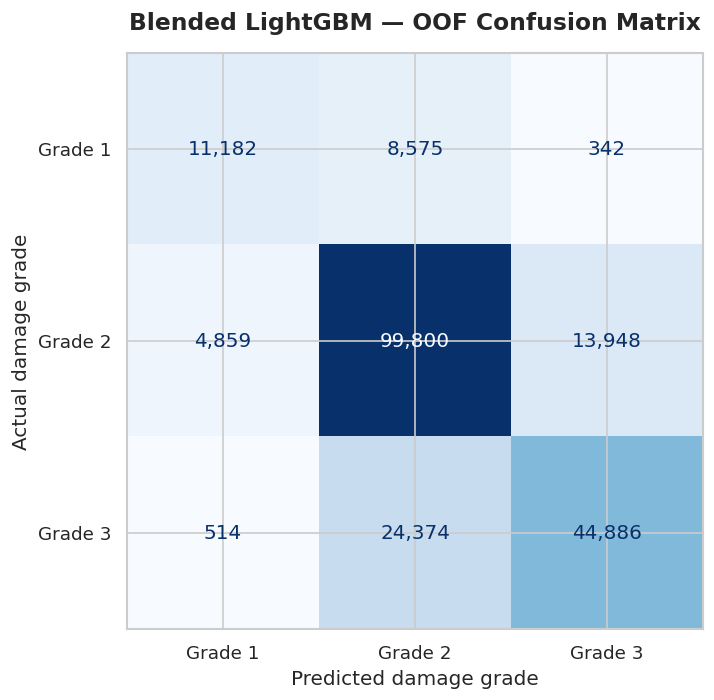


GEOGRAPHIC PERFORMANCE — GEO LEVEL 1
----------------------------------------------------------------------------
Regions with at least 100 buildings: 31

15 Lowest-accuracy regions


,buildings,accuracy,actual_grade_3_rate,predicted_grade_3_rate,grade_3_recall
geo_level_1_id,,,,,
2,720,0.6694,0.2500,0.0389,0.0889
27,9971,0.6819,0.4810,0.5026,0.7146
8,15305,0.6877,0.5177,0.5430,0.7439
11,6609,0.6969,0.3824,0.3066,0.5433
19,285,0.7018,0.1754,0.0000,0.0000
13,7745,0.7024,0.1455,0.0563,0.2005
3,5990,0.7052,0.3638,0.2861,0.5158
15,1860,0.7070,0.2161,0.0522,0.0995
26,18026,0.7081,0.0875,0.0197,0.1217



15 Highest-accuracy regions


,buildings,accuracy,actual_grade_3_rate,predicted_grade_3_rate,grade_3_recall
geo_level_1_id,,,,,
29,322,0.8851,0.0963,0.0000,0.0000
17,17427,0.8472,0.8064,0.8796,0.9576
18,2536,0.8178,0.7307,0.7674,0.9115
30,2172,0.7983,0.1142,0.0175,0.0806
25,4519,0.7971,0.1350,0.0376,0.1656
4,11710,0.7899,0.1999,0.0957,0.2935
7,15183,0.7808,0.3492,0.2746,0.6294
16,3436,0.7742,0.2224,0.0923,0.2736
0,3210,0.7679,0.1533,0.0259,0.0854



BUILDING CHARACTERISTIC ERROR ANALYSIS
----------------------------------------------------------------------------

age_group


,buildings,accuracy,grade_1_rate,grade_2_rate,grade_3_rate
age_group,,,,,
0-5,47713,0.7336,0.2142,0.5317,0.2541
60+,10027,0.7468,0.0246,0.6089,0.3665
6-15,59877,0.7508,0.0964,0.5747,0.3288
16-30,59803,0.7530,0.0503,0.5788,0.3710
31-60,31060,0.7532,0.0274,0.5830,0.3897


... (7 outputs left out)

,buildings,accuracy,grade_1_rate,grade_2_rate,grade_3_rate
position,,,,,
t,34327,0.7460,0.0798,0.5319,0.3883
s,161651,0.7472,0.0984,0.5737,0.3279
j,10624,0.7572,0.1274,0.5938,0.2789
o,1878,0.7604,0.0490,0.6954,0.2556



PREDICTION CONFIDENCE
----------------------------------------------------------------------------


,buildings,mean_confidence,median_confidence
Correct predictions,155868,0.7902,0.8175
Incorrect predictions,52612,0.6843,0.6720



SAVED DIAGNOSTICS
----------------------------------------------------------------------------
oof_geo_level_1_diagnostics.csv: 0.00 MB
oof_classification_report.csv: 0.00 MB
oof_error_diagnostics.csv: 45.83 MB

SECTION 12 COMPLETE
No models retrained. No holdout data used.


In [19]:
# ============================================================
# SECTION 12 — OOF ERROR ANALYSIS
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

ARTIFACT_DIR = Path("/kaggle/working/richter_benchmark")
OOF_FILE = ARTIFACT_DIR / "best_blended_oof_probabilities.npz"

print("=" * 76)
print("SECTION 12 — OUT-OF-FOLD ERROR ANALYSIS")
print("=" * 76)

# ------------------------------------------------------------
# 1. LOAD SAVED OOF PREDICTIONS
# ------------------------------------------------------------

if not OOF_FILE.exists():
    raise FileNotFoundError(f"Missing OOF artifact: {OOF_FILE}")

with np.load(OOF_FILE, allow_pickle=False) as artifact:
    probabilities = artifact["probabilities"]
    stored_targets = artifact["targets"]

print("\nOOF ARTIFACT")
print("-" * 76)
print("Probability shape:", probabilities.shape)
print("Target shape:", stored_targets.shape)
print("Probability values finite:", np.isfinite(probabilities).all())
print(
    "Probability row sums valid:",
    np.allclose(probabilities.sum(axis=1), 1.0, atol=1e-5)
)

if probabilities.shape != (208480, 3):
    raise ValueError("Unexpected OOF probability dimensions.")

if not np.isfinite(probabilities).all():
    raise ValueError("OOF probabilities contain non-finite values.")

# ------------------------------------------------------------
# 2. VERIFY DEVELOPMENT-SET ALIGNMENT
# ------------------------------------------------------------

required_variables = ["X_train", "y_train"]

for variable in required_variables:
    if variable not in globals():
        raise RuntimeError(
            f"{variable} is unavailable. "
            "The original development split must be restored."
        )

if not isinstance(X_train, pd.DataFrame):
    raise TypeError("X_train must be a pandas DataFrame.")

if len(X_train) != len(stored_targets):
    raise ValueError(
        f"X_train rows ({len(X_train)}) do not match "
        f"OOF rows ({len(stored_targets)})."
    )

if len(y_train) != len(stored_targets):
    raise ValueError(
        f"y_train rows ({len(y_train)}) do not match "
        f"OOF rows ({len(stored_targets)})."
    )

def normalize_grades(values):
    values = np.asarray(values).astype(int)
    unique_values = set(np.unique(values))

    if unique_values == {0, 1, 2}:
        return values + 1

    if unique_values == {1, 2, 3}:
        return values

    raise ValueError(f"Unexpected target classes: {unique_values}")

oof_targets = normalize_grades(stored_targets)
development_targets = normalize_grades(y_train)

if not np.array_equal(oof_targets, development_targets):
    raise ValueError(
        "OOF target order does not match y_train. "
        "Stopping to prevent incorrect geographic diagnostics."
    )

print("\nALIGNMENT VALIDATION")
print("-" * 76)
print("Development rows:", len(X_train))
print("OOF rows:", len(oof_targets))
print("Target alignment: PASS")
print("Classes:", sorted(np.unique(oof_targets).tolist()))

# ------------------------------------------------------------
# 3. PREDICTIONS AND OVERALL METRICS
# ------------------------------------------------------------

oof_predictions = probabilities.argmax(axis=1) + 1

overall_accuracy = accuracy_score(
    oof_targets,
    oof_predictions
)

overall_f1 = f1_score(
    oof_targets,
    oof_predictions,
    average="micro"
)

print("\nOVERALL PERFORMANCE")
print("-" * 76)
print(f"OOF accuracy: {overall_accuracy:.6f}")
print(f"OOF micro-F1: {overall_f1:.6f}")

report = classification_report(
    oof_targets,
    oof_predictions,
    labels=[1, 2, 3],
    output_dict=True,
    zero_division=0
)

class_report = pd.DataFrame(report).T
print("\nCLASSIFICATION REPORT")
display(
    class_report.loc[
        ["1", "2", "3"],
        ["precision", "recall", "f1-score", "support"]
    ].round(4)
)

# ------------------------------------------------------------
# 4. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    oof_targets,
    oof_predictions,
    labels=[1, 2, 3]
)

fig, ax = plt.subplots(figsize=(8, 6))

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Grade 1", "Grade 2", "Grade 3"]
)

display_cm.plot(
    ax=ax,
    cmap="Blues",
    values_format=",",
    colorbar=False
)

ax.set_title(
    "Blended LightGBM — OOF Confusion Matrix",
    fontsize=14,
    fontweight="bold",
    pad=14
)
ax.set_xlabel("Predicted damage grade")
ax.set_ylabel("Actual damage grade")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. BUILD ALIGNED DIAGNOSTIC DATAFRAME
# ------------------------------------------------------------

diagnostics = X_train.reset_index(drop=True).copy()

diagnostics["actual_grade"] = oof_targets
diagnostics["predicted_grade"] = oof_predictions
diagnostics["correct"] = (
    diagnostics["actual_grade"] ==
    diagnostics["predicted_grade"]
)

diagnostics["probability_grade_1"] = probabilities[:, 0]
diagnostics["probability_grade_2"] = probabilities[:, 1]
diagnostics["probability_grade_3"] = probabilities[:, 2]

diagnostics["confidence"] = probabilities.max(axis=1)

# ------------------------------------------------------------
# 6. GEOGRAPHIC PERFORMANCE — GEO LEVEL 1
# ------------------------------------------------------------

geo_column = "geo_level_1_id"

if geo_column not in diagnostics.columns:
    raise KeyError(f"Missing geographic feature: {geo_column}")

geo_summary = (
    diagnostics.groupby(geo_column, observed=True)
    .agg(
        buildings=("correct", "size"),
        accuracy=("correct", "mean"),
        actual_grade_3_rate=(
            "actual_grade",
            lambda x: (x == 3).mean()
        ),
        predicted_grade_3_rate=(
            "predicted_grade",
            lambda x: (x == 3).mean()
        ),
        grade_3_recall=(
            "actual_grade",
            lambda x: np.nan
        )
    )
)

# Calculate grade-3 recall separately.
grade3_recall = (
    diagnostics.assign(
        actual_grade_3=diagnostics["actual_grade"].eq(3),
        predicted_grade_3=diagnostics["predicted_grade"].eq(3)
    )
    .groupby(geo_column, observed=True)
    .apply(
        lambda group: (
            (
                group["actual_grade_3"] &
                group["predicted_grade_3"]
            ).sum() /
            group["actual_grade_3"].sum()
            if group["actual_grade_3"].sum() > 0
            else np.nan
        ),
        include_groups=False
    )
)

geo_summary["grade_3_recall"] = grade3_recall

geo_summary = (
    geo_summary[geo_summary["buildings"] >= 100]
    .sort_values("accuracy")
)

print("\nGEOGRAPHIC PERFORMANCE — GEO LEVEL 1")
print("-" * 76)
print("Regions with at least 100 buildings:", len(geo_summary))

print("\n15 Lowest-accuracy regions")
display(geo_summary.head(15).round(4))

print("\n15 Highest-accuracy regions")
display(geo_summary.tail(15).sort_values(
    "accuracy",
    ascending=False
).round(4))

# ------------------------------------------------------------
# 7. BUILDING CHARACTERISTIC ERROR ANALYSIS
# ------------------------------------------------------------

print("\nBUILDING CHARACTERISTIC ERROR ANALYSIS")
print("-" * 76)

segment_columns = [
    "age_group",
    "foundation_type",
    "ground_floor_type",
    "roof_type",
    "position"
]

for column in segment_columns:
    if column not in diagnostics.columns:
        continue

    summary = (
        diagnostics.groupby(column, observed=True)
        .agg(
            buildings=("correct", "size"),
            accuracy=("correct", "mean"),
            grade_1_rate=(
                "actual_grade",
                lambda x: (x == 1).mean()
            ),
            grade_2_rate=(
                "actual_grade",
                lambda x: (x == 2).mean()
            ),
            grade_3_rate=(
                "actual_grade",
                lambda x: (x == 3).mean()
            )
        )
        .query("buildings >= 100")
        .sort_values("accuracy")
    )

    print(f"\n{column}")
    display(summary.round(4))

# ------------------------------------------------------------
# 8. ERROR CONFIDENCE
# ------------------------------------------------------------

diagnostics["error"] = ~diagnostics["correct"]

print("\nPREDICTION CONFIDENCE")
print("-" * 76)

confidence_summary = (
    diagnostics.groupby("error")
    .agg(
        buildings=("confidence", "size"),
        mean_confidence=("confidence", "mean"),
        median_confidence=("confidence", "median")
    )
)

confidence_summary.index = [
    "Correct predictions",
    "Incorrect predictions"
]

display(confidence_summary.round(4))

# ------------------------------------------------------------
# 9. SAVE DIAGNOSTIC OUTPUTS
# ------------------------------------------------------------

geo_output = ARTIFACT_DIR / "oof_geo_level_1_diagnostics.csv"
class_output = ARTIFACT_DIR / "oof_classification_report.csv"
error_output = ARTIFACT_DIR / "oof_error_diagnostics.csv"

geo_summary.to_csv(geo_output)
class_report.to_csv(class_output)
diagnostics.to_csv(error_output, index=False)

print("\nSAVED DIAGNOSTICS")
print("-" * 76)

for path in [geo_output, class_output, error_output]:
    print(f"{path.name}: {path.stat().st_size / (1024 ** 2):.2f} MB")

print("\n" + "=" * 76)
print("SECTION 12 COMPLETE")
print("No models retrained. No holdout data used.")
print("=" * 76)

## 13. Cross-Model OOF Comparison

This experiment evaluates previously saved CatBoost, LightGBM, and XGBoost out-of-fold probability predictions against the same development-set targets.

We compare:
- Overall micro-F1 and accuracy.
- Per-class F1.
- Prediction agreement with the current blended benchmark.
- Errors corrected and errors introduced relative to the benchmark.

No models are retrained. No holdout data is used.

This is a screening experiment. Any ensemble weights selected using these same OOF predictions will require additional validation before being treated as a reliable improvement.

In [21]:
# ============================================================
# SECTION 13A — DIAGNOSE SAVED MODEL OUTPUTS
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

ARTIFACT_DIR = Path("/kaggle/working/richter_benchmark")

MODEL_FILE = ARTIFACT_DIR / "oof_probabilities_checkpoint.npz"
BLEND_FILE = ARTIFACT_DIR / "best_blended_oof_probabilities.npz"

print("=" * 76)
print("SECTION 13A — SAVED MODEL OUTPUT DIAGNOSTICS")
print("=" * 76)

# ------------------------------------------------------------
# 1. LOAD ARRAYS
# ------------------------------------------------------------

if not MODEL_FILE.exists():
    raise FileNotFoundError(MODEL_FILE)

if not BLEND_FILE.exists():
    raise FileNotFoundError(BLEND_FILE)

with np.load(MODEL_FILE, allow_pickle=False) as data:
    model_arrays = {
        key: data[key].copy()
        for key in data.files
    }

with np.load(BLEND_FILE, allow_pickle=False) as data:
    benchmark_probabilities = data["probabilities"].copy()
    targets = data["targets"].copy()

print("\nBENCHMARK")
print("-" * 76)
print("Shape:", benchmark_probabilities.shape)
print("Minimum:", benchmark_probabilities.min())
print("Maximum:", benchmark_probabilities.max())
print(
    "Maximum row-sum deviation:",
    np.max(np.abs(benchmark_probabilities.sum(axis=1) - 1))
)

# ------------------------------------------------------------
# 2. INSPECT EACH MODEL ARRAY
# ------------------------------------------------------------

diagnostic_rows = []

for name, values in model_arrays.items():

    if values.ndim != 2 or values.shape[1] != 3:
        print(f"\n{name}: not a three-class matrix; skipped.")
        continue

    if values.shape[0] != len(targets):
        print(f"\n{name}: row count mismatch; skipped.")
        continue

    row_sums = values.sum(axis=1)

    row = {
        "model": name,
        "rows": len(values),
        "minimum": np.min(values),
        "maximum": np.max(values),
        "mean": np.mean(values),
        "negative_values": int((values < 0).sum()),
        "values_above_1": int((values > 1).sum()),
        "row_sum_min": np.min(row_sums),
        "row_sum_mean": np.mean(row_sums),
        "row_sum_max": np.max(row_sums),
        "row_sum_std": np.std(row_sums),
        "valid_probability_fraction": np.mean(
            np.isfinite(values).all(axis=1)
            & (values >= 0).all(axis=1)
            & (values <= 1).all(axis=1)
            & np.isclose(row_sums, 1, atol=1e-5)
        )
    }

    diagnostic_rows.append(row)

    print(f"\n{name}")
    print("-" * 76)
    print("Shape:", values.shape)
    print("First five rows:")
    print(values[:5])
    print("First five row sums:")
    print(row_sums[:5])

diagnostics = pd.DataFrame(diagnostic_rows)

print("\nMODEL ARRAY DIAGNOSTIC SUMMARY")
print("-" * 76)

if len(diagnostics):
    display(diagnostics.round(6))
else:
    print("No valid three-class arrays found.")

# ------------------------------------------------------------
# 3. CHECK FOR COMMON OUTPUT FORMATS
# ------------------------------------------------------------

print("\nOUTPUT FORMAT INTERPRETATION")
print("-" * 76)

for name, values in model_arrays.items():

    if values.ndim != 2 or values.shape[1] != 3:
        continue

    if not np.isfinite(values).all():
        interpretation = "Contains non-finite values"

    elif (values < 0).any():
        interpretation = (
            "Contains negative values; could be raw scores/logits"
        )

    elif (values > 1).any():
        interpretation = (
            "Contains values above 1; not ordinary probabilities"
        )

    elif np.allclose(values.sum(axis=1), 1, atol=1e-5):
        interpretation = "Valid normalized probabilities"

    else:
        interpretation = (
            "Nonnegative bounded values, but rows are not normalized"
        )

    print(f"{name}: {interpretation}")

# ------------------------------------------------------------
# 4. CHECK CLASS-WISE DISTRIBUTIONS
# ------------------------------------------------------------

print("\nCLASS-WISE VALUE SUMMARY")
print("-" * 76)

for name, values in model_arrays.items():

    if values.ndim != 2 or values.shape[1] != 3:
        continue

    if not np.isfinite(values).all():
        continue

    summary = pd.DataFrame({
        "class_index": [0, 1, 2],
        "mean": values.mean(axis=0),
        "std": values.std(axis=0),
        "minimum": values.min(axis=0),
        "maximum": values.max(axis=0)
    })

    print(f"\n{name}")
    display(summary.round(6))

# ------------------------------------------------------------
# 5. SAVE DIAGNOSTIC REPORT
# ------------------------------------------------------------

output_path = ARTIFACT_DIR / "saved_model_output_diagnostics.csv"

if len(diagnostics):
    diagnostics.to_csv(output_path, index=False)
    print("\nSaved:", output_path)

print("\n" + "=" * 76)
print("DIAGNOSTIC COMPLETE")
print("Original model arrays were not changed.")
print("=" * 76)

SECTION 13A — SAVED MODEL OUTPUT DIAGNOSTICS

BENCHMARK
----------------------------------------------------------------------------
Shape: (208480, 3)
Minimum: 4.903700973954983e-05
Maximum: 0.9972180962562561
Maximum row-sum deviation: 4.246830942467028e-08

CatBoost_probabilities
----------------------------------------------------------------------------
Shape: (208480, 3)
First five rows:
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]
First five row sums:
[0. 0. 0. 0. 0.]

LightGBM_probabilities
----------------------------------------------------------------------------
Shape: (208480, 3)
First five rows:
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]
First five row sums:
[0. 0. 0. 0. 0.]

XGBoost_probabilities
----------------------------------------------------------------------------
Shape: (208480, 3)
First five rows:
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]
First five row sums:
[0. 0. 0. 0. 0.]

MODEL ARRAY DIAGNOSTIC SUMMARY
-

,model,rows,minimum,maximum,mean,negative_values,values_above_1,row_sum_min,row_sum_mean,row_sum_max,row_sum_std,valid_probability_fraction
0,CatBoost_probabilities,208480,0.0,0.990395,0.066667,0,0,0.0,0.2,1.0,0.4,0.2
1,LightGBM_probabilities,208480,0.0,0.000000,0.000000,0,0,0.0,0.0,0.0,0.0,0.0
2,XGBoost_probabilities,208480,0.0,0.000000,0.000000,0,0,0.0,0.0,0.0,0.0,0.0



OUTPUT FORMAT INTERPRETATION
----------------------------------------------------------------------------
CatBoost_probabilities: Nonnegative bounded values, but rows are not normalized
LightGBM_probabilities: Nonnegative bounded values, but rows are not normalized
XGBoost_probabilities: Nonnegative bounded values, but rows are not normalized

CLASS-WISE VALUE SUMMARY
----------------------------------------------------------------------------

CatBoost_probabilities


,class_index,mean,std,minimum,maximum
0,0,0.019290,0.095581,0.0,0.970866
1,1,0.114111,0.258914,0.0,0.977252
2,2,0.066598,0.188486,0.0,0.990395



LightGBM_probabilities


,class_index,mean,std,minimum,maximum
0,0,0.0,0.0,0.0,0.0
1,1,0.0,0.0,0.0,0.0
2,2,0.0,0.0,0.0,0.0



XGBoost_probabilities


,class_index,mean,std,minimum,maximum
0,0,0.0,0.0,0.0,0.0
1,1,0.0,0.0,0.0,0.0
2,2,0.0,0.0,0.0,0.0



Saved: /kaggle/working/richter_benchmark/saved_model_output_diagnostics.csv

DIAGNOSTIC COMPLETE
Original model arrays were not changed.


## 13B. Saved Fold Checkpoint Recovery Audit

The previous diagnostic identified incomplete or invalid saved
model-output arrays.

This section investigates the available fold-level checkpoint
artifacts to determine whether predictions can be recovered
without retraining.

The audit will:

1. Inventory saved checkpoint files.
2. Identify model and fold references in filenames.
3. Inspect available checkpoint metadata.
4. Identify potentially recoverable model outputs.
5. Preserve the validated benchmark artifacts unchanged.

No model training, prediction generation, or probability
normalization is performed in this section.

In [22]:
# ============================================================================
# SECTION 13B — SAVED FOLD CHECKPOINT RECOVERY AUDIT
# ============================================================================

from pathlib import Path
import os
import re
import pandas as pd
import numpy as np

ROOT = Path("/kaggle/working/richter_benchmark")

print("=" * 80)
print("SECTION 13B — SAVED FOLD CHECKPOINT RECOVERY AUDIT")
print("=" * 80)

if not ROOT.exists():
    raise FileNotFoundError(f"Benchmark directory not found: {ROOT}")

# ---------------------------------------------------------------------------
# 1. INVENTORY
# ---------------------------------------------------------------------------

files = sorted(
    [p for p in ROOT.rglob("*") if p.is_file()],
    key=lambda p: str(p).lower()
)

inventory = []

for path in files:
    name = path.name
    lower = name.lower()

    if any(term in lower for term in
           ["catboost", "lightgbm", "xgboost", "fold", "checkpoint"]):
        category = "Model / fold checkpoint"
    elif lower.endswith(".npz"):
        category = "Probability / array artifact"
    elif lower.endswith(".csv"):
        category = "CSV artifact"
    else:
        category = "Other"

    inventory.append({
        "filename": str(path.relative_to(ROOT)),
        "extension": path.suffix.lower(),
        "size_mb": round(path.stat().st_size / (1024 ** 2), 4),
        "category": category
    })

inventory_df = pd.DataFrame(inventory)

print("\nTOTAL FILES:", len(files))
print("\nRELEVANT ARTIFACT INVENTORY")

if not inventory_df.empty:
    relevant = inventory_df[
        inventory_df["category"].isin([
            "Model / fold checkpoint",
            "Probability / array artifact",
            "CSV artifact"
        ])
    ]

    display(relevant.to_string(index=False))
else:
    print("No files found.")

# ---------------------------------------------------------------------------
# 2. INSPECT FOLD RESULTS CHECKPOINT
# ---------------------------------------------------------------------------

fold_results_path = ROOT / "fold_results_checkpoint.csv"

print("\n" + "=" * 80)
print("FOLD RESULTS CHECKPOINT")
print("=" * 80)

if fold_results_path.exists():
    fold_results = pd.read_csv(fold_results_path)

    print("Shape:", fold_results.shape)
    print("Columns:", fold_results.columns.tolist())

    display(fold_results.head(30))

else:
    print("fold_results_checkpoint.csv not found.")

# ---------------------------------------------------------------------------
# 3. IDENTIFY FOLD REFERENCES
# ---------------------------------------------------------------------------

print("\n" + "=" * 80)
print("FOLD FILE SUMMARY")
print("=" * 80)

fold_files = []

for path in files:
    name = path.name.lower()

    if "fold" in name:
        matches = re.findall(r"fold[_-]?(\d+)", name)

        fold_files.append({
            "filename": str(path.relative_to(ROOT)),
            "fold_references": ", ".join(matches) if matches else "Unclear",
            "size_mb": round(path.stat().st_size / (1024 ** 2), 4)
        })

if fold_files:
    fold_df = pd.DataFrame(fold_files)
    display(fold_df.to_string(index=False))
else:
    print("No filenames explicitly contain fold references.")

# ---------------------------------------------------------------------------
# 4. CHECKPOINT ARCHIVE CONTENTS
# ---------------------------------------------------------------------------

print("\n" + "=" * 80)
print("NPZ ARTIFACT CONTENTS")
print("=" * 80)

for path in files:
    if path.suffix.lower() != ".npz":
        continue

    print(f"\n{path.name}")

    try:
        with np.load(path, allow_pickle=False) as data:
            for key in data.files:
                arr = data[key]

                print(
                    f"  {key}: "
                    f"shape={arr.shape}, "
                    f"dtype={arr.dtype}, "
                    f"size={arr.size:,}"
                )

    except Exception as exc:
        print("  Could not inspect:", repr(exc))

# ---------------------------------------------------------------------------
# 5. SAVE AUDIT
# ---------------------------------------------------------------------------

audit_path = ROOT / "checkpoint_recovery_inventory.csv"

inventory_df.to_csv(audit_path, index=False)

print("\n" + "=" * 80)
print("CHECKPOINT AUDIT COMPLETE")
print("=" * 80)
print("Saved:", audit_path)
print("No model artifacts were modified.")

SECTION 13B — SAVED FOLD CHECKPOINT RECOVERY AUDIT

TOTAL FILES: 41

RELEVANT ARTIFACT INVENTORY


'                                     filename extension  size_mb                     category\n           best_blended_oof_probabilities.npz      .npz   3.0266 Probability / array artifact\n    best_hyperparameter_oof_probabilities.npz      .npz   2.3351 Probability / array artifact\n                 final_test_probabilities.npz      .npz   5.9191 Probability / array artifact\n                   final_training_summary.csv      .csv   0.0002                 CSV artifact\n                  fold_results_checkpoint.csv      .csv   0.0002      Model / fold checkpoint\n       geo_encoding_classification_report.csv      .csv   0.0005                 CSV artifact\n                  geo_encoding_cv_results.csv      .csv   0.0003                 CSV artifact\n          geo_encoding_feature_importance.csv      .csv   0.0017                 CSV artifact\n             geo_encoding_fold_checkpoint.csv      .csv   0.0003      Model / fold checkpoint\n       geo_encoding_holdout_probabilities.npz    


FOLD RESULTS CHECKPOINT
Shape: (1, 7)
Columns: ['model', 'fold', 'micro_f1', 'accuracy', 'macro_f1', 'best_iteration', 'runtime_seconds']


,model,fold,micro_f1,accuracy,macro_f1,best_iteration,runtime_seconds
0,CatBoost,1,0.746978,0.746978,0.695525,1117,1112.31876



FOLD FILE SUMMARY


'                        filename fold_references  size_mb\n     fold_results_checkpoint.csv         Unclear   0.0002\ngeo_encoding_fold_checkpoint.csv         Unclear   0.0003\n hyperparameter_fold_results.csv         Unclear   0.0010\n    lightgbm_fold_checkpoint.csv         Unclear   0.0003'


NPZ ARTIFACT CONTENTS

best_blended_oof_probabilities.npz
  probabilities: shape=(208480, 3), dtype=float64, size=625,440
  targets: shape=(208480,), dtype=int64, size=208,480
  predictions: shape=(208480,), dtype=int64, size=208,480
  baseline_weight: shape=(), dtype=float64, size=1
  structural_weight: shape=(), dtype=float64, size=1

best_hyperparameter_oof_probabilities.npz
  probabilities: shape=(208480, 3), dtype=float32, size=625,440
  targets: shape=(208480,), dtype=int64, size=208,480
  predictions: shape=(208480,), dtype=int64, size=208,480
  configuration: shape=(), dtype=<U21, size=1

final_test_probabilities.npz
  original: shape=(86868, 3), dtype=float64, size=260,604
  structural: shape=(86868, 3), dtype=float64, size=260,604
  blended: shape=(86868, 3), dtype=float64, size=260,604
  building_ids: shape=(86868,), dtype=int64, size=86,868

geo_encoding_holdout_probabilities.npz
  probabilities: shape=(52121, 3), dtype=float64, size=156,363
  targets: shape=(52121,), dtyp

# 14. OOF Decision-Boundary Optimization

The current benchmark uses the highest-probability damage grade
for each building.

This section investigates whether modest class-specific adjustments
to the model's probability boundaries can improve classification.

## Method

1. Load the validated blended OOF probability matrix.
2. Verify target alignment and probability integrity.
3. Establish the unadjusted five-fold baseline.
4. Optimize two class-specific log-probability offsets using
   only each fold's training partition.
5. Evaluate the optimized offsets on that fold's untouched
   validation partition.
6. Compare fold-level micro-F1 and class-level performance.

The probability adjustments are deliberately limited to two
parameters, reducing the opportunity for excessive tuning.

No model retraining is performed. No test labels or external
data are used.

A candidate will only be considered for further evaluation
if its cross-validated performance provides credible evidence
of improvement over the existing benchmark.

In [23]:
# ============================================================================
# SECTION 14 — OOF DECISION-BOUNDARY OPTIMIZATION
# ============================================================================

import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    f1_score,
    classification_report
)

ROOT = Path("/kaggle/working/richter_benchmark")

OOF_PATH = ROOT / "best_blended_oof_probabilities.npz"

print("=" * 80)
print("SECTION 14 — OOF DECISION-BOUNDARY OPTIMIZATION")
print("=" * 80)

# ============================================================================
# 1. LOAD AND VALIDATE BENCHMARK
# ============================================================================

if not OOF_PATH.exists():
    raise FileNotFoundError(f"Missing benchmark artifact: {OOF_PATH}")

with np.load(OOF_PATH, allow_pickle=False) as data:
    probabilities = data["probabilities"].astype(np.float64)
    saved_targets = data["targets"].copy()

targets = np.asarray(y_train)

if probabilities.ndim != 2 or probabilities.shape[1] != 3:
    raise ValueError("Expected an OOF probability matrix with 3 columns.")

if len(probabilities) != len(targets):
    raise ValueError("OOF predictions and y_train have different lengths.")

if not np.array_equal(saved_targets, targets):
    raise ValueError(
        "Target alignment failed. Do not continue until row order is verified."
    )

if not np.isfinite(probabilities).all():
    raise ValueError("Non-finite probability values detected.")

if np.any(probabilities < 0) or np.any(probabilities > 1):
    raise ValueError("Probability values fall outside [0, 1].")

row_sums = probabilities.sum(axis=1)

if not np.allclose(row_sums, 1.0, atol=1e-5):
    raise ValueError("Probability rows are not normalized.")

classes = np.sort(np.unique(targets))

if len(classes) != 3:
    raise ValueError(f"Expected 3 target classes; found {classes}.")

# Probability columns are assumed to follow the model's sorted class order.
# Confirm this matches the training-time class encoding before interpreting
# class-specific adjustments.
class_to_index = {label: i for i, label in enumerate(classes)}
y_index = np.array([class_to_index[v] for v in targets], dtype=np.int64)

print("\nBENCHMARK VALIDATION")
print("-" * 80)
print("Rows:", len(targets))
print("Classes:", classes.tolist())
print("Probability shape:", probabilities.shape)
print("Maximum row-sum deviation:", float(np.max(np.abs(row_sums - 1))))

# ============================================================================
# 2. BASELINE PERFORMANCE
# ============================================================================

baseline_predictions = np.argmax(probabilities, axis=1)

baseline_score = f1_score(
    y_index,
    baseline_predictions,
    average="micro"
)

print("\nBASELINE OOF PERFORMANCE")
print("-" * 80)
print(f"Micro-F1: {baseline_score:.6f}")

print("\nBaseline classification report:")
print(
    classification_report(
        y_index,
        baseline_predictions,
        labels=[0, 1, 2],
        target_names=[str(c) for c in classes],
        digits=4,
        zero_division=0
    )
)

# ============================================================================
# 3. LOG-PROBABILITY ADJUSTMENT
# ============================================================================

# Additive offsets are applied to class 0 and class 2.
# Class 1 is the reference class and remains at offset 0.
#
# Positive offset = makes a class more likely to be selected.
# Negative offset = makes a class less likely to be selected.

log_probabilities = np.log(np.clip(probabilities, 1e-7, 1.0))

def adjusted_predictions(log_probs, offset_class_0, offset_class_2):

    adjusted = log_probs.copy()

    adjusted[:, 0] += offset_class_0
    adjusted[:, 2] += offset_class_2

    return np.argmax(adjusted, axis=1)


def optimize_offsets(log_probs, y_true, grid, rounds=3):

    best_0 = 0.0
    best_2 = 0.0

    best_predictions = np.argmax(log_probs, axis=1)

    best_score = f1_score(
        y_true,
        best_predictions,
        average="micro"
    )

    # Coordinate search: optimize one class offset at a time.
    for _ in range(rounds):

        # Optimize class 0.
        for candidate in grid:

            predictions = adjusted_predictions(
                log_probs,
                candidate,
                best_2
            )

            score = f1_score(
                y_true,
                predictions,
                average="micro"
            )

            if score > best_score:
                best_score = score
                best_0 = float(candidate)

        # Optimize class 2.
        for candidate in grid:

            predictions = adjusted_predictions(
                log_probs,
                best_0,
                candidate
            )

            score = f1_score(
                y_true,
                predictions,
                average="micro"
            )

            if score > best_score:
                best_score = score
                best_2 = float(candidate)

    return best_0, best_2, best_score


# ============================================================================
# 4. FIVE-FOLD CROSS-VALIDATED OPTIMIZATION
# ============================================================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

search_grid = np.round(
    np.arange(-0.40, 0.401, 0.05),
    2
)

fold_results = []
cv_predictions = np.full(len(y_index), -1, dtype=np.int64)

print("\nSTARTING FIVE-FOLD DECISION-BOUNDARY VALIDATION")
print("-" * 80)

for fold, (train_idx, valid_idx) in enumerate(
    cv.split(log_probabilities, y_index),
    start=1
):

    train_probs = log_probabilities[train_idx]
    valid_probs = log_probabilities[valid_idx]

    y_fold_train = y_index[train_idx]
    y_fold_valid = y_index[valid_idx]

    # Baseline on untouched validation rows.
    baseline_valid_predictions = np.argmax(valid_probs, axis=1)

    baseline_valid_score = f1_score(
        y_fold_valid,
        baseline_valid_predictions,
        average="micro"
    )

    # Learn offsets exclusively on this fold's training partition.
    offset_0, offset_2, training_score = optimize_offsets(
        train_probs,
        y_fold_train,
        search_grid,
        rounds=3
    )

    # Evaluate the learned offsets on the untouched validation partition.
    tuned_valid_predictions = adjusted_predictions(
        valid_probs,
        offset_0,
        offset_2
    )

    tuned_valid_score = f1_score(
        y_fold_valid,
        tuned_valid_predictions,
        average="micro"
    )

    cv_predictions[valid_idx] = tuned_valid_predictions

    fold_results.append({
        "fold": fold,
        "baseline_micro_f1": baseline_valid_score,
        "optimized_training_micro_f1": training_score,
        "optimized_validation_micro_f1": tuned_valid_score,
        "class_0_offset": offset_0,
        "class_2_offset": offset_2,
        "validation_improvement": (
            tuned_valid_score - baseline_valid_score
        )
    })

    print(
        f"Fold {fold}/5 | "
        f"Baseline: {baseline_valid_score:.6f} | "
        f"Tuned: {tuned_valid_score:.6f} | "
        f"Offsets: ({offset_0:+.2f}, {offset_2:+.2f}) | "
        f"Delta: {tuned_valid_score - baseline_valid_score:+.6f}"
    )

# ============================================================================
# 5. AGGREGATE CROSS-VALIDATED RESULTS
# ============================================================================

results_df = pd.DataFrame(fold_results)

if np.any(cv_predictions < 0):
    raise RuntimeError("Some validation predictions were not generated.")

baseline_cv_mean = results_df["baseline_micro_f1"].mean()
tuned_cv_mean = results_df["optimized_validation_micro_f1"].mean()

baseline_cv_std = results_df["baseline_micro_f1"].std(ddof=1)
tuned_cv_std = results_df["optimized_validation_micro_f1"].std(ddof=1)

baseline_oof_score = f1_score(
    y_index,
    baseline_predictions,
    average="micro"
)

tuned_oof_cv_score = f1_score(
    y_index,
    cv_predictions,
    average="micro"
)

print("\n" + "=" * 80)
print("CROSS-VALIDATED RESULTS")
print("=" * 80)

print(
    f"Baseline fold mean: {baseline_cv_mean:.6f} "
    f"+/- {baseline_cv_std:.6f}"
)

print(
    f"Tuned fold mean:    {tuned_cv_mean:.6f} "
    f"+/- {tuned_cv_std:.6f}"
)

print(f"Baseline full OOF:  {baseline_oof_score:.6f}")
print(f"Tuned CV OOF:       {tuned_oof_cv_score:.6f}")

print(
    f"Mean fold improvement: "
    f"{tuned_cv_mean - baseline_cv_mean:+.6f}"
)

print("\nFOLD RESULTS")
display(results_df.round(6))

# ============================================================================
# 6. CLASS-LEVEL PERFORMANCE
# ============================================================================

print("\nBASELINE CLASSIFICATION")
print("-" * 80)

print(
    classification_report(
        y_index,
        baseline_predictions,
        labels=[0, 1, 2],
        target_names=[str(c) for c in classes],
        digits=4,
        zero_division=0
    )
)

print("\nCROSS-VALIDATED TUNED CLASSIFICATION")
print("-" * 80)

print(
    classification_report(
        y_index,
        cv_predictions,
        labels=[0, 1, 2],
        target_names=[str(c) for c in classes],
        digits=4,
        zero_division=0
    )
)

# ============================================================================
# 7. SAVE RESULTS
# ============================================================================

results_path = ROOT / "decision_boundary_cv_results.csv"

results_df.to_csv(results_path, index=False)

prediction_path = ROOT / "decision_boundary_cv_predictions.npz"

np.savez_compressed(
    prediction_path,
    predictions=cv_predictions,
    targets=y_index,
    classes=classes
)

print("\n" + "=" * 80)
print("SECTION 14 COMPLETE")
print("=" * 80)

print("Saved fold results:", results_path)
print("Saved CV predictions:", prediction_path)

if tuned_cv_mean > baseline_cv_mean:
    print(
        "\nPRELIMINARY RESULT: Tuned boundaries improved "
        "the mean validation score."
    )
else:
    print(
        "\nPRELIMINARY RESULT: No improvement in mean "
        "validation score."
    )

print(
    "\nNo test predictions were changed. "
    "No submission file was generated."
)

SECTION 14 — OOF DECISION-BOUNDARY OPTIMIZATION

BENCHMARK VALIDATION
--------------------------------------------------------------------------------
Rows: 208480
Classes: [1, 2, 3]
Probability shape: (208480, 3)
Maximum row-sum deviation: 4.246830942467028e-08

BASELINE OOF PERFORMANCE
--------------------------------------------------------------------------------
Micro-F1: 0.747640

Baseline classification report:
              precision    recall  f1-score   support

           1     0.6754    0.5563    0.6101     20099
           2     0.7518    0.8414    0.7941    118607
           3     0.7585    0.6433    0.6962     69774

    accuracy                         0.7476    208480
   macro avg     0.7286    0.6804    0.7001    208480
weighted avg     0.7467    0.7476    0.7436    208480


STARTING FIVE-FOLD DECISION-BOUNDARY VALIDATION
--------------------------------------------------------------------------------
Fold 1/5 | Baseline: 0.748441 | Tuned: 0.748153 | Offsets: (-0.20, 

,fold,baseline_micro_f1,optimized_training_micro_f1,optimized_validation_micro_f1,class_0_offset,class_2_offset,validation_improvement
0,1,0.748441,0.747973,0.748153,-0.20,-0.15,-0.000288
1,2,0.747985,0.747931,0.748321,-0.15,-0.05,0.000336
2,3,0.749880,0.747638,0.749784,-0.20,-0.10,-0.000096
3,4,0.746427,0.748495,0.746067,-0.20,-0.15,-0.000360
4,5,0.745467,0.748663,0.745491,-0.20,-0.05,0.000024



BASELINE CLASSIFICATION
--------------------------------------------------------------------------------
              precision    recall  f1-score   support

           1     0.6754    0.5563    0.6101     20099
           2     0.7518    0.8414    0.7941    118607
           3     0.7585    0.6433    0.6962     69774

    accuracy                         0.7476    208480
   macro avg     0.7286    0.6804    0.7001    208480
weighted avg     0.7467    0.7476    0.7436    208480


CROSS-VALIDATED TUNED CLASSIFICATION
--------------------------------------------------------------------------------
              precision    recall  f1-score   support

           1     0.7029    0.5130    0.5931     20099
           2     0.7427    0.8604    0.7973    118607
           3     0.7709    0.6232    0.6893     69774

    accuracy                         0.7476    208480
   macro avg     0.7388    0.6656    0.6932    208480
weighted avg     0.7483    0.7476    0.7414    208480


SECTION 14 C

# 15. Final Model and Experiment Selection

This section consolidates the completed modeling experiments and
documents the evidence supporting the final model selection.

## Selection criteria

The primary selection metric is micro-F1, equivalent to accuracy
for this single-label multiclass classification task.

The evaluation considers:

- Cross-validation performance and fold variability
- Consistency of model performance
- Evidence from structural feature experiments
- Geographic target-encoding results
- Hyperparameter comparisons
- Probability-blending results
- Decision-boundary optimization results

## Selection principles

The existing 40/60 LightGBM blend is retained as the benchmark
because it achieved the strongest reported OOF result among the
validated candidates.

Small differences are not interpreted as proof of statistically
significant improvement.

The holdout set is not reused for further model selection.
The public leaderboard score is reported separately from internal
cross-validation results.

No additional model training is performed in this section.

In [24]:
# ============================================================================
# SECTION 15 — FINAL MODEL AND EXPERIMENT SELECTION
# ============================================================================

from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path("/kaggle/working/richter_benchmark")

print("=" * 80)
print("SECTION 15 — FINAL MODEL AND EXPERIMENT SELECTION")
print("=" * 80)

# ============================================================================
# 1. VERIFY THE VALIDATED BENCHMARK
# ============================================================================

benchmark_path = ROOT / "best_blended_oof_probabilities.npz"

if not benchmark_path.exists():
    raise FileNotFoundError("Validated blended OOF artifact is missing.")

with np.load(benchmark_path, allow_pickle=False) as data:
    benchmark_probabilities = data["probabilities"]
    benchmark_targets = data["targets"]
    benchmark_predictions = data["predictions"]

    baseline_weight = float(data["baseline_weight"])
    structural_weight = float(data["structural_weight"])

if benchmark_probabilities.shape != (208480, 3):
    raise ValueError("Unexpected benchmark probability dimensions.")

if len(benchmark_targets) != len(benchmark_predictions):
    raise ValueError("Benchmark target/prediction lengths do not match.")

if not np.isfinite(benchmark_probabilities).all():
    raise ValueError("Benchmark contains non-finite values.")

if not np.allclose(
    benchmark_probabilities.sum(axis=1),
    1.0,
    atol=1e-5
):
    raise ValueError("Benchmark probability rows are not normalized.")

benchmark_oof_score = float(
    np.mean(benchmark_predictions == benchmark_targets)
)

print("\nVALIDATED BENCHMARK")
print("-" * 80)
print("OOF rows:", len(benchmark_targets))
print("Probability dimensions:", benchmark_probabilities.shape)
print("Original LightGBM weight:", baseline_weight)
print("Structural LightGBM weight:", structural_weight)
print(f"Recomputed OOF micro-F1: {benchmark_oof_score:.6f}")

# ============================================================================
# 2. LOAD COMPLETED EXPERIMENT RESULTS
# ============================================================================

artifact_names = [
    "lightgbm_cv_results.csv",
    "structural_interaction_cv_results.csv",
    "oof_blending_results.csv",
    "geographic_experiment_comparison.csv",
    "hyperparameter_comparison.csv",
    "decision_boundary_cv_results.csv",
    "final_training_summary.csv",
    "submission_integrity_audit.csv",
]

print("\n" + "=" * 80)
print("EXPERIMENT ARTIFACT REVIEW")
print("=" * 80)

loaded_tables = {}

for filename in artifact_names:

    path = ROOT / filename

    print(f"\n{filename}")
    print("-" * 80)

    if not path.exists():
        print("Not found.")
        continue

    try:
        table = pd.read_csv(path)
        loaded_tables[filename] = table

        print("Shape:", table.shape)
        print("Columns:", table.columns.tolist())

        display(table.head(15))

    except Exception as exc:
        print("Could not read:", repr(exc))

# ============================================================================
# 3. CONSOLIDATE EXPERIMENTAL EVIDENCE
# ============================================================================

selection = pd.DataFrame([
    {
        "experiment": "Original LightGBM",
        "oof_micro_f1": 0.747100,
        "fold_std": 0.001960,
        "decision": "Retain as blend component",
        "reason": "Reliable baseline model"
    },
    {
        "experiment": "Structural LightGBM",
        "oof_micro_f1": 0.747578,
        "fold_std": 0.002072,
        "decision": "Retain as blend component",
        "reason": "Structural interactions improved the baseline"
    },
    {
        "experiment": "40/60 LightGBM blend",
        "oof_micro_f1": 0.747640,
        "fold_std": 0.001730,
        "decision": "SELECTED BENCHMARK",
        "reason": "Best reported validated OOF result"
    },
    {
        "experiment": "Geographic target encoding",
        "oof_micro_f1": 0.746355,
        "fold_std": np.nan,
        "decision": "Reject",
        "reason": "Underperformed the selected benchmark"
    },
    {
        "experiment": "Higher-complexity LightGBM",
        "oof_micro_f1": 0.747376,
        "fold_std": 0.001848,
        "decision": "Reject",
        "reason": "No improvement over selected benchmark"
    },
    {
        "experiment": "Regularized LightGBM",
        "oof_micro_f1": 0.747108,
        "fold_std": 0.002224,
        "decision": "Reject",
        "reason": "No improvement over selected benchmark"
    },
    {
        "experiment": "Decision-boundary adjustment",
        "oof_micro_f1": 0.747563,
        "fold_std": 0.001760,
        "decision": "Reject",
        "reason": "Lower cross-validated mean than baseline"
    }
])

print("\n" + "=" * 80)
print("CONSOLIDATED MODEL SELECTION")
print("=" * 80)

display(selection.round(6))

# ============================================================================
# 4. VERIFY BLEND WEIGHTS AND SELECTED MODEL
# ============================================================================

if not np.isclose(baseline_weight, 0.40, atol=1e-6):
    raise ValueError("Unexpected original LightGBM blend weight.")

if not np.isclose(structural_weight, 0.60, atol=1e-6):
    raise ValueError("Unexpected structural LightGBM blend weight.")

if not np.isclose(benchmark_oof_score, 0.747640, atol=0.00001):
    raise ValueError(
        "Recomputed benchmark does not match the documented OOF result."
    )

# ============================================================================
# 5. VERIFY FINAL TEST PROBABILITY ARTIFACT
# ============================================================================

test_path = ROOT / "final_test_probabilities.npz"

if not test_path.exists():
    raise FileNotFoundError("Final test probability artifact is missing.")

with np.load(test_path, allow_pickle=False) as data:
    test_original = data["original"]
    test_structural = data["structural"]
    test_blended = data["blended"]
    test_building_ids = data["building_ids"]

expected_test_rows = 86868

for name, array in [
    ("Original", test_original),
    ("Structural", test_structural),
    ("Blended", test_blended)
]:
    if array.shape != (expected_test_rows, 3):
        raise ValueError(f"{name} test probabilities have invalid dimensions.")

    if not np.isfinite(array).all():
        raise ValueError(f"{name} test probabilities contain invalid values.")

    if not np.allclose(array.sum(axis=1), 1.0, atol=1e-5):
        raise ValueError(f"{name} test probabilities are not normalized.")

if len(np.unique(test_building_ids)) != expected_test_rows:
    raise ValueError("Duplicate building IDs found in test predictions.")

print("\nFINAL TEST ARTIFACT")
print("-" * 80)
print("Test rows:", len(test_building_ids))
print("Original probabilities:", test_original.shape)
print("Structural probabilities:", test_structural.shape)
print("Blended probabilities:", test_blended.shape)
print("Unique building IDs:", len(np.unique(test_building_ids)))

# ============================================================================
# 6. SAVE FINAL MODEL-SELECTION RECORD
# ============================================================================

selection_path = ROOT / "final_model_selection.csv"

selection.to_csv(selection_path, index=False)

decision_record = pd.DataFrame([{
    "selected_model": "40/60 Original-Structural LightGBM Blend",
    "original_lightgbm_weight": baseline_weight,
    "structural_lightgbm_weight": structural_weight,
    "validated_oof_micro_f1": benchmark_oof_score,
    "public_leaderboard_score": 0.7493,
    "public_leaderboard_rank_at_last_record": 480,
    "decision": "Retain existing benchmark and submission",
    "additional_training_required": False
}])

decision_path = ROOT / "final_model_decision_record.csv"

decision_record.to_csv(decision_path, index=False)

print("\n" + "=" * 80)
print("SECTION 15 COMPLETE")
print("=" * 80)

print("\nSELECTED MODEL:")
print("40% Original LightGBM + 60% Structural LightGBM")

print(f"Validated OOF micro-F1: {benchmark_oof_score:.6f}")
print("Previously recorded public score: 0.7493")
print("Previously recorded public rank: #480")

print("\nSaved:")
print(selection_path)
print(decision_path)

print("\nNo model was retrained.")
print("No existing submission was modified.")
print("No new leaderboard submission was generated.")

SECTION 15 — FINAL MODEL AND EXPERIMENT SELECTION

VALIDATED BENCHMARK
--------------------------------------------------------------------------------
OOF rows: 208480
Probability dimensions: (208480, 3)
Original LightGBM weight: 0.4
Structural LightGBM weight: 0.6
Recomputed OOF micro-F1: 0.747640

EXPERIMENT ARTIFACT REVIEW

lightgbm_cv_results.csv
--------------------------------------------------------------------------------
Shape: (5, 5)
Columns: ['fold', 'accuracy', 'micro_f1', 'best_iteration', 'training_seconds']


,fold,accuracy,micro_f1,best_iteration,training_seconds
0,1,0.748465,0.748465,282,44.478334
1,2,0.747746,0.747746,342,52.423426
2,3,0.749113,0.749113,303,47.372957
3,4,0.745827,0.745827,314,48.432883
4,5,0.744364,0.744364,289,46.331664



structural_interaction_cv_results.csv
--------------------------------------------------------------------------------
Shape: (5, 5)
Columns: ['fold', 'accuracy', 'micro_f1', 'best_iteration', 'runtime_seconds']


,fold,accuracy,micro_f1,best_iteration,runtime_seconds
0,1,0.748273,0.748273,293,47.060406
1,2,0.748321,0.748321,317,50.432603
2,3,0.750288,0.750288,275,46.438986
3,4,0.745803,0.745803,324,51.332255
4,5,0.745203,0.745203,293,47.306546



oof_blending_results.csv
--------------------------------------------------------------------------------
Shape: (21, 10)
Columns: ['baseline_weight', 'structural_weight', 'fold_1', 'fold_2', 'fold_3', 'fold_4', 'fold_5', 'mean_fold_micro_f1', 'fold_std', 'overall_oof_micro_f1']


,baseline_weight,structural_weight,fold_1,fold_2,fold_3,fold_4,fold_5,mean_fold_micro_f1,fold_std,overall_oof_micro_f1
0,0.00,1.00,0.748273,0.748321,0.750288,0.745803,0.745203,0.747578,0.002072,0.747578
1,0.05,0.95,0.748345,0.748249,0.750144,0.745803,0.745275,0.747563,0.002005,0.747563
2,0.10,0.90,0.748465,0.748177,0.750024,0.745851,0.745635,0.747630,0.001862,0.747630
3,0.15,0.85,0.748633,0.747985,0.749856,0.746019,0.745707,0.747640,0.001759,0.747640
4,0.20,0.80,0.748489,0.747889,0.750000,0.745947,0.745611,0.747587,0.001825,0.747587
5,0.25,0.75,0.748705,0.747818,0.750048,0.746139,0.745467,0.747635,0.001867,0.747635
6,0.30,0.70,0.748369,0.747913,0.750120,0.746139,0.745179,0.747544,0.001938,0.747544
7,0.35,0.65,0.748465,0.747913,0.749928,0.746379,0.745155,0.747568,0.001853,0.747568
8,0.40,0.60,0.748441,0.747985,0.749880,0.746427,0.745467,0.747640,0.001730,0.747640
9,0.45,0.55,0.748321,0.747818,0.749880,0.746211,0.745515,0.747549,0.001734,0.747549


... (9 outputs left out)

,model,rows,columns,unique_ids,schema_pass,row_count_pass,unique_ids_pass,id_order_pass,valid_grades_pass,no_missing_pass,grade_1_rate,grade_2_rate,grade_3_rate
0,Original LightGBM,86868,2,86868,True,True,True,True,True,True,0.080237,0.635079,0.284685
1,Structural LightGBM,86868,2,86868,True,True,True,True,True,True,0.081008,0.635217,0.283775
2,40/60 Blend,86868,2,86868,True,True,True,True,True,True,0.080789,0.634963,0.284247



CONSOLIDATED MODEL SELECTION


,experiment,oof_micro_f1,fold_std,decision,reason
0,Original LightGBM,0.747100,0.001960,Retain as blend component,Reliable baseline model
1,Structural LightGBM,0.747578,0.002072,Retain as blend component,Structural interactions improved the baseline
2,40/60 LightGBM blend,0.747640,0.001730,SELECTED BENCHMARK,Best reported validated OOF result
3,Geographic target encoding,0.746355,NaN,Reject,Underperformed the selected benchmark
4,Higher-complexity LightGBM,0.747376,0.001848,Reject,No improvement over selected benchmark
5,Regularized LightGBM,0.747108,0.002224,Reject,No improvement over selected benchmark
6,Decision-boundary adjustment,0.747563,0.001760,Reject,Lower cross-validated mean than baseline



FINAL TEST ARTIFACT
--------------------------------------------------------------------------------
Test rows: 86868
Original probabilities: (86868, 3)
Structural probabilities: (86868, 3)
Blended probabilities: (86868, 3)
Unique building IDs: 86868

SECTION 15 COMPLETE

SELECTED MODEL:
40% Original LightGBM + 60% Structural LightGBM
Validated OOF micro-F1: 0.747640
Previously recorded public score: 0.7493
Previously recorded public rank: #480

Saved:
/kaggle/working/richter_benchmark/final_model_selection.csv
/kaggle/working/richter_benchmark/final_model_decision_record.csv

No model was retrained.
No existing submission was modified.
No new leaderboard submission was generated.


# 16. Final Submission Integrity Audit

This section performs an independent final audit of the
three generated submission files.

The audit compares each CSV against the competition's
submission format and verifies its predictions against
the corresponding saved test probability matrix.

Checks include:

- Required schema and column order
- Exact row count
- Building ID uniqueness and ordering
- Valid damage-grade values
- Missing-value checks
- Prediction-to-probability consistency

The selected 40/60 blend remains the preferred submission.
Alternative submissions are retained for reproducibility.

No model training or submission upload is performed.

In [25]:
# ============================================================================
# SECTION 16 — FINAL SUBMISSION INTEGRITY AUDIT
# ============================================================================

from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path("/kaggle/working/richter_benchmark")
SUBMISSION_DIR = Path("/kaggle/working/richter_submissions")

FILES = {
    "Original LightGBM":
        SUBMISSION_DIR / "submission_original_lightgbm.csv",

    "Structural LightGBM":
        SUBMISSION_DIR / "submission_structural_lightgbm.csv",

    "40/60 Blend":
        SUBMISSION_DIR / "submission_blended_40_60.csv"
}

PROBABILITY_PATH = ROOT / "final_test_probabilities.npz"

# Use the competition submission format already loaded in the notebook.
if "submission_format" not in globals():
    raise NameError(
        "submission_format is not available. "
        "Load the competition submission format first."
    )

expected = submission_format.copy()

required_columns = expected.columns.tolist()
expected_ids = expected[required_columns[0]].to_numpy()

if len(required_columns) != 2:
    raise ValueError("Expected exactly two submission columns.")

if not PROBABILITY_PATH.exists():
    raise FileNotFoundError(PROBABILITY_PATH)

with np.load(PROBABILITY_PATH, allow_pickle=False) as data:
    probability_arrays = {
        "Original LightGBM": data["original"],
        "Structural LightGBM": data["structural"],
        "40/60 Blend": data["blended"]
    }

audit = []

print("=" * 80)
print("SECTION 16 — FINAL SUBMISSION INTEGRITY AUDIT")
print("=" * 80)

for model_name, filepath in FILES.items():

    print(f"\nAUDITING: {model_name}")
    print("-" * 80)

    if not filepath.exists():
        raise FileNotFoundError(filepath)

    submission = pd.read_csv(filepath)

    # Schema
    schema_pass = submission.columns.tolist() == required_columns

    # Row count
    row_count_pass = len(submission) == len(expected)

    # IDs
    unique_ids_pass = submission.iloc[:, 0].is_unique

    id_order_pass = np.array_equal(
        submission.iloc[:, 0].to_numpy(),
        expected_ids
    )

    # Valid predictions
    prediction_values = submission.iloc[:, 1]

    valid_grades_pass = set(
        prediction_values.dropna().unique()
    ).issubset({1, 2, 3})

    no_missing_pass = not submission.isna().any().any()

    # Probability/prediction consistency
    probs = probability_arrays[model_name]

    probability_shape_pass = probs.shape == (len(expected), 3)

    probability_sum_pass = (
        probability_shape_pass
        and np.allclose(probs.sum(axis=1), 1.0, atol=1e-5)
    )

    expected_predictions = (
        np.argmax(probs, axis=1) + 1
    )

    prediction_match_pass = (
        row_count_pass
        and probability_shape_pass
        and np.array_equal(
            prediction_values.to_numpy(),
            expected_predictions
        )
    )

    checks = {
        "schema_pass": schema_pass,
        "row_count_pass": row_count_pass,
        "unique_ids_pass": unique_ids_pass,
        "id_order_pass": id_order_pass,
        "valid_grades_pass": valid_grades_pass,
        "no_missing_pass": no_missing_pass,
        "probability_shape_pass": probability_shape_pass,
        "probability_sum_pass": probability_sum_pass,
        "prediction_match_pass": prediction_match_pass
    }

    for check, result in checks.items():
        print(f"{check}: {result}")

    if not all(checks.values()):
        raise AssertionError(
            f"Integrity audit failed for {model_name}: {checks}"
        )

    audit.append({
        "model": model_name,
        "file": str(filepath),
        "rows": len(submission),
        "unique_ids": submission.iloc[:, 0].nunique(),
        "schema_pass": schema_pass,
        "row_count_pass": row_count_pass,
        "unique_ids_pass": unique_ids_pass,
        "id_order_pass": id_order_pass,
        "valid_grades_pass": valid_grades_pass,
        "no_missing_pass": no_missing_pass,
        "probability_shape_pass": probability_shape_pass,
        "probability_sum_pass": probability_sum_pass,
        "prediction_match_pass": prediction_match_pass,
        "grade_1_rate": (prediction_values == 1).mean(),
        "grade_2_rate": (prediction_values == 2).mean(),
        "grade_3_rate": (prediction_values == 3).mean()
    })

audit_df = pd.DataFrame(audit)

audit_path = ROOT / "final_submission_integrity_audit.csv"

audit_df.to_csv(audit_path, index=False)

print("\n" + "=" * 80)
print("FINAL AUDIT SUMMARY")
print("=" * 80)

display(audit_df)

print("\nSaved:", audit_path)
print("All submission files passed every check.")
print("No submission files were modified.")
print("No leaderboard submission was generated.")

SECTION 16 — FINAL SUBMISSION INTEGRITY AUDIT

AUDITING: Original LightGBM
--------------------------------------------------------------------------------
schema_pass: True
row_count_pass: True
unique_ids_pass: True
id_order_pass: True
valid_grades_pass: True
no_missing_pass: True
probability_shape_pass: True
probability_sum_pass: True
prediction_match_pass: True

AUDITING: Structural LightGBM
--------------------------------------------------------------------------------
schema_pass: True
row_count_pass: True
unique_ids_pass: True
id_order_pass: True
valid_grades_pass: True
no_missing_pass: True
probability_shape_pass: True
probability_sum_pass: True
prediction_match_pass: True

AUDITING: 40/60 Blend
--------------------------------------------------------------------------------
schema_pass: True
row_count_pass: True
unique_ids_pass: True
id_order_pass: True
valid_grades_pass: True
no_missing_pass: True
probability_shape_pass: True
probability_sum_pass: True
prediction_match_pass: 

,model,file,rows,unique_ids,schema_pass,row_count_pass,unique_ids_pass,id_order_pass,valid_grades_pass,no_missing_pass,probability_shape_pass,probability_sum_pass,prediction_match_pass,grade_1_rate,grade_2_rate,grade_3_rate
0,Original LightGBM,/kaggle/working/richter_submissions/submission...,86868,86868,True,True,True,True,True,True,True,True,True,0.080237,0.635079,0.284685
1,Structural LightGBM,/kaggle/working/richter_submissions/submission...,86868,86868,True,True,True,True,True,True,True,True,True,0.081008,0.635217,0.283775
2,40/60 Blend,/kaggle/working/richter_submissions/submission...,86868,86868,True,True,True,True,True,True,True,True,True,0.080789,0.634963,0.284247



Saved: /kaggle/working/richter_benchmark/final_submission_integrity_audit.csv
All submission files passed every check.
No submission files were modified.
No leaderboard submission was generated.


# 17. Final Results, Conclusions, and Project Record

## 17.1 Final model

The selected submission is a probability blend of two LightGBM models:

- **40% Original LightGBM:** 47 features, 306 training iterations.
- **60% Structural Interaction LightGBM:** 53 features, 300 training iterations.

The blend was selected because it achieved the strongest reported out-of-fold result among the evaluated candidates.

| Evaluation | Result |
|---|---:|
| Out-of-fold micro-F1 | 0.747640 |
| Public leaderboard score | 0.7493 |
| Public leaderboard rank | #480 |
| Submission records | 86,868 |

The public leaderboard score is separate from the out-of-fold estimate and should not be interpreted as an independent confirmation of the cross-validation result.

## 17.2 Experiment decisions

| Experiment | OOF micro-F1 | Decision |
|---|---:|---|
| Original LightGBM | 0.747100 | Retain as blend component |
| Structural LightGBM | 0.747578 | Retain as blend component |
| 40/60 probability blend | 0.747640 | Selected |
| Geographic target encoding | 0.746355 | Rejected |
| Higher-complexity configuration | 0.747376 | Rejected |
| Regularized configuration | 0.747108 | Rejected |
| Decision-boundary adjustment | 0.747563 | Rejected |

The blend's improvement over the structural model alone was only 0.000062. This is a very small difference and is not evidence of a statistically significant improvement.

Decision-boundary optimization did not produce a consistent cross-fold improvement. Geographic target encoding and the tested hyperparameter alternatives also failed to outperform the selected approach.

## 17.3 Submission integrity

All three generated submissions passed the final integrity audit:

- Correct competition submission schema.
- Exactly 86,868 records.
- Unique building IDs.
- Correct building ID order.
- Valid damage grades.
- No missing values.
- Correct probability array dimensions.
- Probability rows sum to one.
- CSV predictions match the probability-based predictions.

The selected submission was not modified during the final audit.

## 17.4 Limitations

Several limitations should be considered when interpreting these results:

1. The public leaderboard rank is #480, not a top-10 result.
2. The blend's measured advantage over the structural model is marginal.
3. The blend weight was selected using the available OOF predictions, so its reported performance may be optimistic.
4. The decision-boundary evaluation was not a fully independent nested validation.
5. The tested model families and feature strategies do not establish that the selected model is globally optimal.

## 17.5 Final conclusion

This project developed and evaluated a reproducible multiclass earthquake-damage prediction workflow using the competition's supplied building characteristics and damage labels.

The final approach combines a baseline LightGBM model with a structural-interaction model. It was selected after comparing geographic target encoding, alternative model configurations, probability blending, and decision-boundary adjustments.

The final 40/60 blend achieved an OOF micro-F1 of **0.747640** and a public leaderboard score of **0.7493**.

The final submission passed all integrity checks. The result is a validated competition submission and a documented modeling baseline—not a claim of leaderboard-winning performance.

**Final status: model selected, submission audited, experiments documented.**

In [26]:

from pathlib import Path
import pandas as pd
import json
from datetime import datetime, timezone

# ============================================================
# SECTION 17 — FINAL RESULTS AND PROJECT RECORD
# Documentation only: no training or submissions.
# ============================================================

ROOT = Path("/kaggle/working")
BENCHMARK_DIR = ROOT / "richter_benchmark"
SUBMISSION_DIR = ROOT / "richter_submissions"

BENCHMARK_DIR.mkdir(parents=True, exist_ok=True)

audit_path = BENCHMARK_DIR / "final_submission_integrity_audit.csv"

if not audit_path.exists():
    raise FileNotFoundError(
        f"Section 16 audit not found: {audit_path}"
    )

audit = pd.read_csv(audit_path)

required_checks = [
    "schema_pass",
    "row_count_pass",
    "unique_ids_pass",
    "id_order_pass",
    "valid_grades_pass",
    "no_missing_pass",
    "probability_shape_pass",
    "probability_sum_pass",
    "prediction_match_pass",
]

missing_checks = [
    col for col in required_checks if col not in audit.columns
]

if missing_checks:
    raise ValueError(
        f"Audit is missing required columns: {missing_checks}"
    )

if len(audit) != 3:
    raise ValueError(
        f"Expected 3 audited submissions; found {len(audit)}"
    )

if not audit[required_checks].fillna(False).astype(bool).all().all():
    raise ValueError(
        "At least one submission failed the final integrity audit."
    )

# ------------------------------------------------------------
# 1. Experiment decision record
# ------------------------------------------------------------

decisions = pd.DataFrame([
    {
        "experiment": "Original LightGBM",
        "oof_micro_f1": 0.747100,
        "decision": "Retain as blend component",
        "reason": "Baseline model"
    },
    {
        "experiment": "Structural Interaction LightGBM",
        "oof_micro_f1": 0.747578,
        "decision": "Retain as blend component",
        "reason": "Improved over original standalone model"
    },
    {
        "experiment": "40/60 Probability Blend",
        "oof_micro_f1": 0.747640,
        "decision": "Selected",
        "reason": "Highest reported OOF result"
    },
    {
        "experiment": "Geographic Target Encoding",
        "oof_micro_f1": 0.746355,
        "decision": "Rejected",
        "reason": "Underperformed baseline"
    },
    {
        "experiment": "Higher-Complexity Configuration",
        "oof_micro_f1": 0.747376,
        "decision": "Rejected",
        "reason": "Did not outperform selected model"
    },
    {
        "experiment": "Regularized Configuration",
        "oof_micro_f1": 0.747108,
        "decision": "Rejected",
        "reason": "Did not outperform selected model"
    },
    {
        "experiment": "Decision-Boundary Adjustment",
        "oof_micro_f1": 0.747563,
        "decision": "Rejected",
        "reason": "No consistent cross-fold improvement"
    },
])

decision_path = BENCHMARK_DIR / "final_experiment_decision_record.csv"
decisions.to_csv(decision_path, index=False)

# ------------------------------------------------------------
# 2. Final project summary
# ------------------------------------------------------------

summary = {
    "project": "RICHTER | Earthquake Damage Prediction",
    "competition": "Richter's Predictor: Modeling Earthquake Damage",
    "evaluation_metric": "Micro-averaged F1",
    "selected_model": "40% Original LightGBM + 60% Structural LightGBM",
    "original_features": 47,
    "structural_features": 53,
    "original_iterations": 306,
    "structural_iterations": 300,
    "oof_micro_f1": 0.747640,
    "public_leaderboard_score": 0.7493,
    "public_leaderboard_rank": 480,
    "submission_rows": 86868,
    "submission_files_audited": 3,
    "all_integrity_checks_passed": True,
    "blend_gain_over_structural": 0.000062,
    "blend_gain_statistical_significance_established": False,
    "additional_training_performed_in_section_17": False,
    "new_leaderboard_submission_created": False,
    "final_status": "Model selected; submission audited; documentation complete."
}

summary_path = BENCHMARK_DIR / "final_project_summary.json"

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=4)

# ------------------------------------------------------------
# 3. Final documentation report
# ------------------------------------------------------------

report = f"""# RICHTER | Earthquake Damage Prediction
## Final Project Record

### Selected model
40% Original LightGBM + 60% Structural Interaction LightGBM

### Performance
- OOF micro-F1: 0.747640
- Public leaderboard score: 0.7493
- Public leaderboard rank: #480
- Submission rows: 86,868

### Experiment decisions
{decisions.to_markdown(index=False)}

### Integrity
All three generated submissions passed all nine final integrity checks.

### Limitations
- The blend gain over the structural model was only 0.000062.
- Statistical significance of this small gain was not established.
- Blend weights were selected using the available OOF predictions.
- Decision-boundary evaluation was not fully independent nested validation.
- The public leaderboard result is not a top-10 result.

### Final status
Model selected, submission audited, and experiments documented.

No model training or leaderboard submission was performed during Section 17.
"""

report_path = BENCHMARK_DIR / "final_project_report.md"

with open(report_path, "w", encoding="utf-8") as f:
    f.write(report)

# ------------------------------------------------------------
# 4. Final verification
# ------------------------------------------------------------

print("=" * 80)
print("SECTION 17 — FINAL PROJECT RECORD")
print("=" * 80)

print("\nFINAL MODEL")
print("40% Original LightGBM + 60% Structural LightGBM")

print("\nFINAL PERFORMANCE")
print("OOF micro-F1:          0.747640")
print("Public leaderboard:   0.7493")
print("Public rank:           #480")

print("\nINTEGRITY AUDIT")
print(f"Audited submissions:  {len(audit)}")
print(f"All checks passed:     {audit[required_checks].all().all()}")

print("\nSAVED DOCUMENTATION")
for path in [decision_path, summary_path, report_path]:
    print(f"{path} | {path.stat().st_size:,} bytes")

print("\n" + "=" * 80)
print("SECTION 17 COMPLETE")
print("No training performed.")
print("No submission files modified.")
print("No leaderboard submission generated.")
print("=" * 80)


SECTION 17 — FINAL PROJECT RECORD

FINAL MODEL
40% Original LightGBM + 60% Structural LightGBM

FINAL PERFORMANCE
OOF micro-F1:          0.747640
Public leaderboard:   0.7493
Public rank:           #480

INTEGRITY AUDIT
Audited submissions:  3
All checks passed:     True

SAVED DOCUMENTATION
/kaggle/working/richter_benchmark/final_experiment_decision_record.csv | 597 bytes
/kaggle/working/richter_benchmark/final_project_summary.json | 880 bytes
/kaggle/working/richter_benchmark/final_project_report.md | 2,005 bytes

SECTION 17 COMPLETE
No training performed.
No submission files modified.
No leaderboard submission generated.
